In [30]:
import pandas as pd
import numpy as np
from pathlib import Path
import matplotlib.pyplot as plt
import re

# ============================================================
# SINGLE CELL - CLINICAL GROUPING + SURVIVAL MEDIAN + MUTATIONS
#
# GROUP-ORIENTED CHAIN:
# LUAD_NSCLC = LUAD + NSCLC
# LUSC_NSCLC = LUSC + NSCLC
#
# Output principali in memoria:
# - df_with_groups
# - clinical
# - group_survival_summary
# - df
# - df_mutations
# - df_final
# - df_final_grouped
#
# Compatibilità:
# Le celle successive del notebook useranno ONCOTREE_CODE come gruppo aggregato:
#   ONCOTREE_CODE = LUAD_NSCLC oppure LUSC_NSCLC
#
# L'istologia originale viene conservata in:
#   ORIGINAL_ONCOTREE_CODE
# ============================================================


# ============================================================
# 0. Paths e parametri
# ============================================================

data_dir = Path("data_lung")

input_file = data_dir / "filtered_data_LUNG.csv"
file_path_mutations = Path("data") / "data_mutations.txt"

# Se vuoi anche salvare i CSV intermedi, metti True.
# Se vuoi lavorare solo in memoria, lascia False.
SAVE_OUTPUTS = True

output_dir = data_dir / "clinical_to_network_by_oncotree_groups"
output_dir.mkdir(exist_ok=True)

oncotree_groups = {
    "LUAD_NSCLC": ["LUAD", "NSCLC"],
    "LUSC_NSCLC": ["LUSC", "NSCLC"],
}

target_groups = ["LUAD_NSCLC", "LUSC_NSCLC"]

group_labels = {
    "LUAD_NSCLC": "LUAD+NSCLC",
    "LUSC_NSCLC": "LUSC+NSCLC",
}


# ============================================================
# Helper
# ============================================================

def safe_filename(text):
    text = str(text)
    text = re.sub(r"[^A-Za-z0-9_-]+", "_", text)
    return text.strip("_")


def safe_display(df_obj):
    try:
        display(df_obj)
    except NameError:
        print(df_obj)


def collapse_duplicate_columns(df_in):
    """
    Rimuove/gestisce colonne duplicate.
    Se esistono duplicati con stesso nome, tiene la prima occorrenza.
    """
    return df_in.loc[:, ~df_in.columns.duplicated()].copy()


# ============================================================
# 1. Load filtered clinical dataset
# ============================================================

df_raw = pd.read_csv(input_file, low_memory=False)
df_raw = collapse_duplicate_columns(df_raw)

df_raw = df_raw.rename(columns={
    "Overall Survival (Months)": "OS_MONTHS",
    "Overall Survival Status": "OS_STATUS",
    "Patient_ID": "PATIENT_ID",
    "Oncotree Code": "ONCOTREE_CODE"
})

df_raw = collapse_duplicate_columns(df_raw)


# ============================================================
# 2. Check colonne richieste
# ============================================================

required_cols = {
    "PATIENT_ID",
    "ONCOTREE_CODE",
    "OS_MONTHS",
    "OS_STATUS"
}

missing_cols = required_cols - set(df_raw.columns)

if missing_cols:
    raise ValueError(
        f"Colonne mancanti in filtered_data_LUNG.csv: {missing_cols}"
    )


# ============================================================
# 3. Preprocessing survival
# ============================================================

df_raw["PATIENT_ID"] = df_raw["PATIENT_ID"].astype(str)
df_raw["ONCOTREE_CODE"] = df_raw["ONCOTREE_CODE"].astype(str)
df_raw["OS_STATUS"] = df_raw["OS_STATUS"].astype(str)

df_raw["OS_MONTHS"] = pd.to_numeric(
    df_raw["OS_MONTHS"],
    errors="coerce"
)

# Event definition:
# 1 = deceased
# 0 = living / censored
df_raw["event"] = (
    df_raw["OS_STATUS"]
    .astype(str)
    .str.contains("DECEASED", case=False, na=False)
    .astype(int)
)

df_raw["OS_STATUS_CLEAN"] = np.where(
    df_raw["event"] == 1,
    "DECEASED",
    "LIVING"
)

df_raw = df_raw.dropna(
    subset=[
        "PATIENT_ID",
        "ONCOTREE_CODE",
        "OS_MONTHS",
        "OS_STATUS",
        "event"
    ]
).copy()


# ============================================================
# 4. Patient-level clinical table by original Oncotree Code
# ============================================================

clinical_original = (
    df_raw[
        [
            "PATIENT_ID",
            "ONCOTREE_CODE",
            "OS_MONTHS",
            "OS_STATUS",
            "OS_STATUS_CLEAN",
            "event"
        ]
    ]
    .drop_duplicates(["PATIENT_ID", "ONCOTREE_CODE"])
    .copy()
)

print("Patient-level clinical table originale:")
print("Patients:", clinical_original["PATIENT_ID"].nunique())
print("Patient-istology rows:", clinical_original.shape[0])

print("\nOS_STATUS distribution by original Oncotree Code:")
safe_display(
    clinical_original
    .groupby(["ONCOTREE_CODE", "OS_STATUS_CLEAN"])
    .agg(n_patients=("PATIENT_ID", "nunique"))
    .reset_index()
    .sort_values(["ONCOTREE_CODE", "OS_STATUS_CLEAN"])
)


# ============================================================
# 5. Build patient-level clinical table by aggregated groups
#    NSCLC viene incluso sia in LUAD_NSCLC sia in LUSC_NSCLC
# ============================================================

clinical_group_tables = []

for group_name, codes in oncotree_groups.items():

    readable_group_name = group_labels.get(group_name, group_name)

    clinical_group = clinical_original[
        clinical_original["ONCOTREE_CODE"].isin(codes)
    ].copy()

    clinical_group["Oncotree_Group"] = group_name
    clinical_group["Included_Oncotree_Codes"] = readable_group_name

    clinical_group_tables.append(clinical_group)

clinical = pd.concat(
    clinical_group_tables,
    ignore_index=True
)

clinical = clinical.drop_duplicates(
    ["PATIENT_ID", "Oncotree_Group"]
).copy()

print("\nPatient-level clinical table by Oncotree groups:")
print("Patients unique global:", clinical["PATIENT_ID"].nunique())
print("Patient-group rows:", clinical.shape[0])

print("\nOS_STATUS distribution by Oncotree Group:")
safe_display(
    clinical
    .groupby(["Oncotree_Group", "Included_Oncotree_Codes", "OS_STATUS_CLEAN"])
    .agg(n_patients=("PATIENT_ID", "nunique"))
    .reset_index()
    .sort_values(["Oncotree_Group", "OS_STATUS_CLEAN"])
)


# ============================================================
# 6. Calculate survival median within each Oncotree Group
# ============================================================

group_survival_summary = (
    clinical
    .groupby(["Oncotree_Group", "Included_Oncotree_Codes"])
    .agg(
        n_patients=("PATIENT_ID", "nunique"),
        n_deceased=("event", "sum"),
        median_OS_MONTHS=("OS_MONTHS", "median"),
        mean_OS_MONTHS=("OS_MONTHS", "mean"),
        min_OS_MONTHS=("OS_MONTHS", "min"),
        max_OS_MONTHS=("OS_MONTHS", "max")
    )
    .sort_values("n_patients", ascending=False)
    .reset_index()
)

group_survival_summary["n_living"] = (
        group_survival_summary["n_patients"]
        - group_survival_summary["n_deceased"]
)

print("\nSurvival summary by Oncotree Group:")
safe_display(group_survival_summary)


# ============================================================
# 7. Assign HIGH / LOW survival group within each Oncotree Group
# ============================================================

clinical = clinical.merge(
    group_survival_summary[
        [
            "Oncotree_Group",
            "median_OS_MONTHS"
        ]
    ],
    on="Oncotree_Group",
    how="left"
)

clinical["survival_group"] = np.where(
    clinical["OS_MONTHS"] >= clinical["median_OS_MONTHS"],
    "high",
    "low"
)

clinical = clinical.rename(
    columns={
        "median_OS_MONTHS": "survival_threshold_median_by_oncotree_group"
    }
)


# ============================================================
# 8. Merge survival group back into original filtered dataset
#    Le righe NSCLC vengono duplicate perché appartengono a entrambi i gruppi.
# ============================================================

df_group_tables = []

for group_name, codes in oncotree_groups.items():

    readable_group_name = group_labels.get(group_name, group_name)

    df_group = df_raw[
        df_raw["ONCOTREE_CODE"].isin(codes)
    ].copy()

    df_group["Oncotree_Group"] = group_name
    df_group["Included_Oncotree_Codes"] = readable_group_name

    clinical_group = clinical[
        clinical["Oncotree_Group"] == group_name
        ][
        [
            "PATIENT_ID",
            "Oncotree_Group",
            "OS_MONTHS",
            "OS_STATUS",
            "OS_STATUS_CLEAN",
            "event",
            "survival_group",
            "survival_threshold_median_by_oncotree_group"
        ]
    ].copy()

    df_group = df_group.merge(
        clinical_group,
        on=[
            "PATIENT_ID",
            "Oncotree_Group",
            "OS_MONTHS",
            "OS_STATUS",
            "OS_STATUS_CLEAN",
            "event"
        ],
        how="left"
    )

    df_group_tables.append(df_group)

df_with_groups = pd.concat(
    df_group_tables,
    ignore_index=True
)

print("\nSurvival group distribution by Oncotree Group:")
safe_display(
    df_with_groups
    .drop_duplicates(["PATIENT_ID", "Oncotree_Group"])
    .groupby(
        [
            "Oncotree_Group",
            "Included_Oncotree_Codes",
            "survival_group",
            "OS_STATUS_CLEAN"
        ]
    )
    .agg(n_patients=("PATIENT_ID", "nunique"))
    .reset_index()
    .sort_values(
        [
            "Oncotree_Group",
            "survival_group",
            "OS_STATUS_CLEAN"
        ]
    )
)


# ============================================================
# 9. Prepare df for downstream notebook compatibility
# ============================================================
# Da questo punto in poi:
# - df["ONCOTREE_CODE"] contiene LUAD_NSCLC / LUSC_NSCLC
# - df["ORIGINAL_ONCOTREE_CODE"] contiene LUAD / LUSC / NSCLC

df = df_with_groups.copy()
df = collapse_duplicate_columns(df)

df = df.rename(columns={
    "PATIENT_ID": "Patient_ID",
    "Patient_ID": "Patient_ID",

    "Hugo_Symbol": "Hugo_Symbol",

    "Oncotree Code": "ONCOTREE_CODE",
    "ONCOTREE_CODE": "ONCOTREE_CODE",

    "Oncotree Group": "Oncotree_Group",
    "ONCOTREE_GROUP": "Oncotree_Group",
    "Oncotree_Group": "Oncotree_Group",

    "Overall Survival (Months)": "OS_MONTHS",
    "Overall Survival Status": "OS_STATUS"
})

df = collapse_duplicate_columns(df)

required_df_cols = {
    "Patient_ID",
    "ONCOTREE_CODE",
    "Oncotree_Group",
    "OS_MONTHS",
    "survival_group",
    "survival_threshold_median_by_oncotree_group"
}

missing_df_cols = required_df_cols - set(df.columns)

if missing_df_cols:
    raise ValueError(
        f"Colonne mancanti dopo la creazione dei gruppi: {missing_df_cols}"
    )

df["Patient_ID"] = df["Patient_ID"].astype(str)
df["ONCOTREE_CODE"] = df["ONCOTREE_CODE"].astype(str)
df["Oncotree_Group"] = df["Oncotree_Group"].astype(str)

df = df[
    df["Oncotree_Group"].isin(target_groups)
].copy()

df["ORIGINAL_ONCOTREE_CODE"] = df["ONCOTREE_CODE"]
df["ONCOTREE_CODE"] = df["Oncotree_Group"]

# Vecchio nome compatibile con celle successive
df["survival_threshold_median_by_oncotree"] = (
    df["survival_threshold_median_by_oncotree_group"]
)

if "Included_Oncotree_Codes" not in df.columns:
    df["Included_Oncotree_Codes"] = df["ONCOTREE_CODE"].map(group_labels)

unique_patients = df["Patient_ID"].dropna().unique()

print("\nPatients in grouped clinical dataframe:", len(unique_patients))

print("\nOncotree groups used as ONCOTREE_CODE:")
safe_display(
    df[
        [
            "Patient_ID",
            "ONCOTREE_CODE",
            "Included_Oncotree_Codes",
            "ORIGINAL_ONCOTREE_CODE",
            "survival_group",
            "survival_threshold_median_by_oncotree"
        ]
    ]
    .drop_duplicates()
    .groupby(["ONCOTREE_CODE", "Included_Oncotree_Codes", "survival_group"])
    .agg(
        n_patients=("Patient_ID", "nunique"),
        threshold_median=("survival_threshold_median_by_oncotree", "first"),
        original_oncotree_codes=(
            "ORIGINAL_ONCOTREE_CODE",
            lambda x: ", ".join(sorted(x.dropna().astype(str).unique()))
        )
    )
    .reset_index()
    .sort_values(["ONCOTREE_CODE", "survival_group"])
)


# ============================================================
# 10. Load mutations
# ============================================================

df_mutations = pd.read_csv(
    file_path_mutations,
    sep="\t",
    low_memory=False
)

if "Tumor_Sample_Barcode" not in df_mutations.columns:
    raise ValueError(
        "Nel file data/data_mutations.txt manca la colonna Tumor_Sample_Barcode."
    )

df_mutations["Patient_ID"] = (
    df_mutations["Tumor_Sample_Barcode"]
    .astype(str)
    .str.extract(r"^(P-\d+)", expand=False)
    .str.strip()
)

df_final = df_mutations[
    df_mutations["Patient_ID"].isin(unique_patients)
].copy()

print("\nMutation rows after patient filtering:", df_final.shape[0])
print("Mutation patients:", df_final["Patient_ID"].nunique())


# ============================================================
# 11. Mutation dataframe annotated by Oncotree groups
# ============================================================

patient_group_map_cols = [
    "Patient_ID",
    "ONCOTREE_CODE",
    "Included_Oncotree_Codes",
    "ORIGINAL_ONCOTREE_CODE",
    "survival_group",
    "survival_threshold_median_by_oncotree",
    "OS_MONTHS",
    "event",
    "OS_STATUS"
]

patient_group_map_cols = [
    col for col in patient_group_map_cols
    if col in df.columns
]

patient_group_map = (
    df[patient_group_map_cols]
    .drop_duplicates()
    .copy()
)

df_final_grouped = df_final.merge(
    patient_group_map,
    on="Patient_ID",
    how="inner"
)

print("\nGrouped mutation dataframe created in memory:")
print("Rows:", df_final_grouped.shape[0])
print("Patients:", df_final_grouped["Patient_ID"].nunique())

print("\nMutation patients by grouped ONCOTREE_CODE:")
safe_display(
    df_final_grouped
    .drop_duplicates(["Patient_ID", "ONCOTREE_CODE"])
    .groupby(["ONCOTREE_CODE", "Included_Oncotree_Codes"])
    .agg(
        n_patients=("Patient_ID", "nunique"),
        original_oncotree_codes=(
            "ORIGINAL_ONCOTREE_CODE",
            lambda x: ", ".join(sorted(x.dropna().astype(str).unique()))
        )
    )
    .sort_values("n_patients", ascending=False)
)


# ============================================================
# 12. Optional saving
# ============================================================

if SAVE_OUTPUTS:
    group_survival_summary.to_csv(
        output_dir / "survival_thresholds_by_oncotree_groups.csv",
        index=False
    )

    df_with_groups.to_csv(
        output_dir / "filtered_data_LUNG_with_survival_groups_BY_ONCOTREE_GROUPS.csv",
        index=False
    )

    clinical.to_csv(
        output_dir / "clinical_survival_groups_by_oncotree_groups.csv",
        index=False
    )

    for group_name, df_group in df_with_groups.groupby("Oncotree_Group"):

        safe_code = safe_filename(group_name)

        output_file = (
                output_dir
                / f"filtered_data_LUNG_with_survival_groups_{safe_code}.csv"
        )

        df_group.to_csv(
            output_file,
            index=False
        )

    print("\nCSV intermedi salvati in:")
    print(output_dir)


# ============================================================
# 13. Compatibility aliases
# ============================================================

oncotree_survival_summary = group_survival_summary

print("\nNota finale:")
print(
    "Da questo punto in poi il notebook userà ONCOTREE_CODE come gruppo aggregato "
    "(LUAD_NSCLC / LUSC_NSCLC)."
)
print(
    "Il codice istologico originale è conservato in ORIGINAL_ONCOTREE_CODE."
)
print(
    "La mediana di sopravvivenza per gruppo è in survival_threshold_median_by_oncotree."
)

Patient-level clinical table originale:
Patients: 1930
Patient-istology rows: 1930

OS_STATUS distribution by original Oncotree Code:


,ONCOTREE_CODE,OS_STATUS_CLEAN,n_patients
0,ALUCA,DECEASED,2
1,ALUCA,LIVING,1
2,LCLC,DECEASED,1
3,LECLC,DECEASED,1
4,LNET,DECEASED,11
5,LNET,LIVING,2
6,LUACC,DECEASED,2
7,LUAD,DECEASED,1024
8,LUAD,LIVING,516
9,LUAS,DECEASED,6



Patient-level clinical table by Oncotree groups:
Patients unique global: 1841
Patient-group rows: 1998

OS_STATUS distribution by Oncotree Group:


,Oncotree_Group,Included_Oncotree_Codes,OS_STATUS_CLEAN,n_patients
0,LUAD_NSCLC,LUAD+NSCLC,DECEASED,1139
1,LUAD_NSCLC,LUAD+NSCLC,LIVING,558
2,LUSC_NSCLC,LUSC+NSCLC,DECEASED,228
3,LUSC_NSCLC,LUSC+NSCLC,LIVING,73



Survival summary by Oncotree Group:


,Oncotree_Group,Included_Oncotree_Codes,n_patients,n_deceased,median_OS_MONTHS,mean_OS_MONTHS,min_OS_MONTHS,max_OS_MONTHS,n_living
0,LUAD_NSCLC,LUAD+NSCLC,1697,1139,17.917789,24.820593,0.032877,110.432756,558
1,LUSC_NSCLC,LUSC+NSCLC,301,228,10.849303,16.043818,0.032877,78.936900,73


... (3 outputs left out)

,ONCOTREE_CODE,Included_Oncotree_Codes,survival_group,n_patients,threshold_median,original_oncotree_codes
0,LUAD_NSCLC,LUAD+NSCLC,high,849,17.917789,"LUAD, NSCLC"
1,LUAD_NSCLC,LUAD+NSCLC,low,848,17.917789,"LUAD, NSCLC"
2,LUSC_NSCLC,LUSC+NSCLC,high,151,10.849303,"LUSC, NSCLC"
3,LUSC_NSCLC,LUSC+NSCLC,low,150,10.849303,"LUSC, NSCLC"



Mutation rows after patient filtering: 15056
Mutation patients: 1841

Grouped mutation dataframe created in memory:
Rows: 16554
Patients: 1841

Mutation patients by grouped ONCOTREE_CODE:


,,n_patients,original_oncotree_codes
ONCOTREE_CODE,Included_Oncotree_Codes,,
LUAD_NSCLC,LUAD+NSCLC,1697,"LUAD, NSCLC"
LUSC_NSCLC,LUSC+NSCLC,301,"LUSC, NSCLC"



CSV intermedi salvati in:
data_lung\clinical_to_network_by_oncotree_groups

Nota finale:
Da questo punto in poi il notebook userà ONCOTREE_CODE come gruppo aggregato (LUAD_NSCLC / LUSC_NSCLC).
Il codice istologico originale è conservato in ORIGINAL_ONCOTREE_CODE.
La mediana di sopravvivenza per gruppo è in survival_threshold_median_by_oncotree.


***
## CO-OCCURRENCE ANALYSIS - LUNG CANCER

## Filter unique patients

In [31]:
# show me how many unique patients have mutations in these genes
unique_patients = df['Patient_ID'].unique()
unique_patients

array(['P-0081657', 'P-0085255', 'P-0087669', ..., 'P-0010636',
       'P-0012925', 'P-0012662'], dtype=object)

In [32]:
df_mutations["Patient_ID"] = (
    df_mutations["Tumor_Sample_Barcode"]
    .astype(str)
    .str.extract(r"^(P-\d+)", expand=False)
    .str.strip()
 )

In [33]:
# given df_mutations, filter by unique_patients
df_final = df_mutations[df_mutations['Patient_ID'].isin(unique_patients)]
print(df_final[['Hugo_Symbol', 'Patient_ID']])

       Hugo_Symbol Patient_ID
0             EGFR  P-0081657
1           PDGFRB  P-0081657
2            RBM10  P-0081657
8             CUL3  P-0085255
9            SETD2  P-0085255
...            ...        ...
206695        PMS1  P-0011453
206696        BAP1  P-0011453
206697       KEAP1  P-0011453
206698       AMER1  P-0011453
206699        BAP1  P-0011453

[15056 rows x 2 columns]


In [34]:
df_final['Patient_ID'].value_counts()

Patient_ID
P-0040867    112
P-0016365     94
P-0075083     87
P-0049029     53
P-0085029     48
            ... 
P-0035021      1
P-0048096      1
P-0026997      1
P-0007322      1
P-0037356      1
Name: count, Length: 1841, dtype: int64

# Structural Variant

In [35]:
file_path_structural = Path("data") / "data_sv.txt"

df_structural = pd.read_csv(file_path_structural, sep='\t')
df_structural.head()

,Sample_Id,SV_Status,Site1_Hugo_Symbol,Site2_Hugo_Symbol,Site1_Chromosome,Site2_Chromosome,Site1_Position,Site2_Position,Site1_Description,Site2_Description,...,Connection_Type,Annotation,DNA_Support,RNA_Support,SV_Length,Normal_Read_Count,Tumor_Read_Count,Normal_Variant_Count,Tumor_Variant_Count,Comments
0,P-0022424-T01-IM6,SOMATIC,SEPTIN12,ARID1A,16,1,4838352.0,27089562.0,5-UTR of SEPT12(-):11Kb before coding start,Exon 8 of ARID1A(+),...,3to3,ARID1A (NM_006015) - SEPT12 (NM_144605) rearrangement: t(1;16)(p36.11;p13.3)(chr1:g.27089562::chr16:g.4838352),yes,unknown,0.0,0.0,0.0,0.0,10.0,Note: The ARID1A - SEPT12 rearrangement is a translocation which may result in the fusion of ARID1A exons 1-8 with SEPT12 exons 1-10. One of the breakpoints is within ARID1A exon 8. Its functional significance is und...
1,P-0015002-T01-IM6,SOMATIC,A2BP1,ZFHX3,16,16,6119693.0,72831356.0,5-UTR of A2BP1(+): 982Kb before coding start,Exon 9 of ZFHX3(-),...,5to5,ZFHX3 (NM_006885) rearrangement : c.5225:ZFHX3_g.6119693inv,yes,unknown,66711663.0,322021.0,328704.0,0.0,22.0,Note: The ZFHX3 (NM_006885) rearrangement results in an inversion of ZFHX3 exons 9-10 . The breakpoint in ZFHX3 is within exon 9. The functional significance is undetermined.
2,P-0067067-T01-IM7,SOMATIC,ABCA3,CREBBP,16,16,2345775.0,3832990.0,Intron of ABCA3(-):34bp before exon 18,Intron of CREBBP(-):63bp before exon 6,...,5to3,ABCA3 (NM_001089) - CREBBP (NM_004380) rearrangement: c.2264-34:ABCA3_c.1331-63:CREBBPdup,yes,unknown,1487215.0,110825.0,189734.0,0.0,26.0,Note: The ABCA3 - CREBBP rearrangement is a duplication that results in a fusion of ABCA3 exons 1 - 17 to CREBBP exons 6 - 31. The fusion is predicted to be in frame. Functional significance is undetermined.
3,P-0056185-T01-IM6,SOMATIC,ABCC4,VEGFA,13,6,95869663.0,43752221.0,Intron of ABCC4(-):7Kb before exon 5,Intron of VEGFA(+):56bp before exon 8,...,5to5,ABCC4 (NM_005845) - VEGFA (NM_001171623) rearrangement: t(6;13)(p21.1;q32.1)(chr6:g.43752221::chr13:g.95869663),yes,unknown,0.0,0.0,0.0,0.0,66.0,Note: The ABCC4 - VEGFA rearrangement is a translocation that results in a fusion of ABCC4 exons 1 - 4 to VEGFA exon 8. Functional significance is undetermined.
4,P-0014522-T01-IM6,SOMATIC,ABCC4,TMPRSS2,21,13,42873289.0,95689572.0,Intron of TMPRSS2(-): 3Kb before exon 2,Intron of ABCC4(-): 3Kb before exon 30,...,3to5,ABCC4 (NM_005845) - TMPRSS2 (NM_001135099) Rearrangement : t(13;21)(q32.1;q22.3)(chr13:g.:95689572::chr21:g.42873289),yes,unknown,0.0,0.0,0.0,0.0,4.0,Note: The ABCC4 - TMPRSS2 Rearrangement is a translocation event which results in the fusion of exons 1-29 of ABCC4 with exons 2 -14 of TMPRSS2. . Its functional significance is undetermined. While this is not the...


In [36]:
df_structural["Patient_ID"] = (
    df_structural["Sample_Id"]
    .astype(str)
    .str.extract(r"^(P-\d+)", expand=False)
    .str.strip()
 )

In [37]:
df_structural

,Sample_Id,SV_Status,Site1_Hugo_Symbol,Site2_Hugo_Symbol,Site1_Chromosome,Site2_Chromosome,Site1_Position,Site2_Position,Site1_Description,Site2_Description,...,Annotation,DNA_Support,RNA_Support,SV_Length,Normal_Read_Count,Tumor_Read_Count,Normal_Variant_Count,Tumor_Variant_Count,Comments,Patient_ID
0,P-0022424-T01-IM6,SOMATIC,SEPTIN12,ARID1A,16,1,4838352.0,27089562.0,5-UTR of SEPT12(-):11Kb before coding start,Exon 8 of ARID1A(+),...,ARID1A (NM_006015) - SEPT12 (NM_144605) rearrangement: t(1;16)(p36.11;p13.3)(chr1:g.27089562::chr16:g.4838352),yes,unknown,0.0,0.0,0.0,0.0,10.0,Note: The ARID1A - SEPT12 rearrangement is a translocation which may result in the fusion of ARID1A exons 1-8 with SEPT12 exons 1-10. One of the breakpoints is within ARID1A exon 8. Its functional significance is und...,P-0022424
1,P-0015002-T01-IM6,SOMATIC,A2BP1,ZFHX3,16,16,6119693.0,72831356.0,5-UTR of A2BP1(+): 982Kb before coding start,Exon 9 of ZFHX3(-),...,ZFHX3 (NM_006885) rearrangement : c.5225:ZFHX3_g.6119693inv,yes,unknown,66711663.0,322021.0,328704.0,0.0,22.0,Note: The ZFHX3 (NM_006885) rearrangement results in an inversion of ZFHX3 exons 9-10 . The breakpoint in ZFHX3 is within exon 9. The functional significance is undetermined.,P-0015002
2,P-0067067-T01-IM7,SOMATIC,ABCA3,CREBBP,16,16,2345775.0,3832990.0,Intron of ABCA3(-):34bp before exon 18,Intron of CREBBP(-):63bp before exon 6,...,ABCA3 (NM_001089) - CREBBP (NM_004380) rearrangement: c.2264-34:ABCA3_c.1331-63:CREBBPdup,yes,unknown,1487215.0,110825.0,189734.0,0.0,26.0,Note: The ABCA3 - CREBBP rearrangement is a duplication that results in a fusion of ABCA3 exons 1 - 17 to CREBBP exons 6 - 31. The fusion is predicted to be in frame. Functional significance is undetermined.,P-0067067
3,P-0056185-T01-IM6,SOMATIC,ABCC4,VEGFA,13,6,95869663.0,43752221.0,Intron of ABCC4(-):7Kb before exon 5,Intron of VEGFA(+):56bp before exon 8,...,ABCC4 (NM_005845) - VEGFA (NM_001171623) rearrangement: t(6;13)(p21.1;q32.1)(chr6:g.43752221::chr13:g.95869663),yes,unknown,0.0,0.0,0.0,0.0,66.0,Note: The ABCC4 - VEGFA rearrangement is a translocation that results in a fusion of ABCC4 exons 1 - 4 to VEGFA exon 8. Functional significance is undetermined.,P-0056185
4,P-0014522-T01-IM6,SOMATIC,ABCC4,TMPRSS2,21,13,42873289.0,95689572.0,Intron of TMPRSS2(-): 3Kb before exon 2,Intron of ABCC4(-): 3Kb before exon 30,...,ABCC4 (NM_005845) - TMPRSS2 (NM_001135099) Rearrangement : t(13;21)(q32.1;q22.3)(chr13:g.:95689572::chr21:g.42873289),yes,unknown,0.0,0.0,0.0,0.0,4.0,Note: The ABCC4 - TMPRSS2 Rearrangement is a translocation event which results in the fusion of exons 1-29 of ABCC4 with exons 2 -14 of TMPRSS2. . Its functional significance is undetermined. While this is not the...,P-0014522
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
6884,P-0073984-T01-IM7,SOMATIC,ZNRF3,NaN,22,22,29247410.0,29442727.0,IGR: 32Kb before ZNRF3(+),Exon 6 of ZNRF3(+),...,ZNRF3 (NM_001206998): rearrangement: g.29247410_c.768inv,NaN,NaN,195317.0,10766.0,13674.0,0.0,3.0,Note: The ZNRF3 rearrangement is an inversion that includes ZNRF3 exons 1-6. One of the breakpoints is within exon 6. The functional significance is undetermined.,P-0073984
6885,P-0051867-T01-IM6,SOMATIC,ZRSR2,ZRSR2,X,X,15815003.0,15827409.0,Intron of ZRSR2(+):3Kb before exon 3,Exon 7 of ZRSR2(+),...,ZRSR2 (NM_005089) rearrangement: c.122-2992_c.525del,yes,unknown,12406.0,4694.0,12421.0,0.0,16.0,Note: The ZRSR2 rearrangement is an intragenic deletion of exons 3 - 7. One of the breakpoints is within exon 7. Functional significance is undetermined.,P-0051867
6886,P-0059443-T01-IM7,SOMATIC,ZRSR2,ZNF804A,X,2,15808580.0,186012111.0,5-UTR of ZRSR2(+):38bp before coding start,IGR: 549Kb before ZNF804A(+),...,ZRSR2 (NM_005089) rearrangement: t(2;X)(q31.2;p22.2)(chr2:g.186012111::chrX:g.15808580),yes,unknown,0.0,0.0,0.0,0.0,14.0,Note: The ZRSR2 rearrangement is a translocation of ZRSR2 promoter region with a genomic region on chr 2. Functional signi

In [38]:
# Keep only patients in df_structural that are also present in df filtered
# unique_patients = df['Patient_ID'].unique()
patients_in_data_filtered = set(df['Patient_ID'].dropna().astype(str).str.strip())

df_structural_filtered = df_structural[df_structural['Patient_ID'].astype(str).str.strip().isin(patients_in_data_filtered)].copy()

print(f"Patients in df: {len(unique_patients)}")
print(f"Patients in df_structural before: {df_structural['Patient_ID'].nunique()}")
print(f"Patients kept in df_structural_filtered: {df_structural_filtered['Patient_ID'].nunique()}")

df_structural_filtered

Patients in df: 1841
Patients in df_structural before: 5398
Patients kept in df_structural_filtered: 484


,Sample_Id,SV_Status,Site1_Hugo_Symbol,Site2_Hugo_Symbol,Site1_Chromosome,Site2_Chromosome,Site1_Position,Site2_Position,Site1_Description,Site2_Description,...,Annotation,DNA_Support,RNA_Support,SV_Length,Normal_Read_Count,Tumor_Read_Count,Normal_Variant_Count,Tumor_Variant_Count,Comments,Patient_ID
13,P-0016809-T02-IM6,SOMATIC,ACLY,TAP2,17,6,40049233.0,32797080.0,Intron of ACLY(-):52bp after exon 15,Intron of TAP2(-):96bp after exon 11,...,TAP2 (NM_018833) rearrangement: t(6;17)(p21.32;q21.2)(chr6:g.32797080::chr17:g.40049233),yes,unknown,0.0,0.0,0.0,0.0,6.0,Note: The TAP2 rearrangement is a translocation with a breakpoint in intron 11. The functional significance is undetermined.,P-0016809
30,P-0043747-T02-IM6,SOMATIC,AGO2,NaN,8,8,141541880.0,141542584.0,3-UTR of AGO2(-):262bp after coding stop,Exon 18 of AGO2(-),...,AGO2 (NM_012154) rearrangement: c.2402:AGO2_chr8:g.141541880inv,NaN,NaN,704.0,2116.0,2524.0,0.0,3.0,Note: The AGO2 rearrangement is an inversion of exons 18 - 19. One of the breakpoints is within exon 18. Functional significance is undetermined.,P-0043747
36,P-0047553-T01-IM6,SOMATIC,AGO2,AGO2,8,8,141564299.0,141566119.0,Intron of AGO2(-):2Kb after exon 10,Intron of AGO2(-):2bp before exon 10,...,AGO2 (NM_012154) rearrangement: c.1147-2_c.1269+1696dup,yes,unknown,1820.0,1336.0,1862.0,0.0,50.0,Note: The AGO2 rearrangement is an intragenic duplication of exon 10. Functional significance is undetermined.,P-0047553
63,P-0030134-T01-IM6,SOMATIC,AKT2,AKT2,19,19,40736136.0,40745059.0,Promoter of AKT2(-):87bp from tx start,Intron of AKT2(-):179bp before exon 8,...,AKT2 (NM_001626) rearrangement: c.640-179:AKT2_chr19:g.40736136inv,yes,unknown,8923.0,12626.0,18625.0,0.0,8.0,Note: The AKT2 rearrangement is an inversion of exons 1-7. The functional significance is undetermined.,P-0030134
72,P-0055682-T01-IM6,SOMATIC,ALDH2,IFNGR1,12,6,112238291.0,137539706.0,Intron of ALDH2(+):424bp after exon 11,Intron of IFNGR1(-):673bp after exon 1,...,ALDH2 (NM_000690) - IFNGR1 (NM_000416) rearrangement: t(6;12)(q23.3;q24.12)(chr6:g.137539706::chr12:g.112238291),yes,unknown,0.0,0.0,0.0,0.0,5.0,Note: The ALDH2 - IFNGR1 rearrangement is a translocation that results in a fusion of ALDH2 exons 1 - 11 to IFNGR1 exons 2 - 7. Functional significance is undetermined.,P-0055682
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
6836,P-0055173-T02-IM6,SOMATIC,ZFHX3,NaN,16,16,72821884.0,72844684.0,Exon 10 of ZFHX3(-),Intron of ZFHX3(-):791bp after exon 7,...,ZFHX3 (NM_006885) rearrangement: c.3864+792_c.10291del,NaN,NaN,22800.0,36481.0,50677.0,0.0,50.0,Note: The ZFHX3 rearrangement is an intragenic deletion of exons 8 - 10. One of the breakpoints is within exon 10.,P-0055173
6842,P-0055799-T03-IM7,SOMATIC,ZFHX3,ZFHX3,19,16,3034795.0,72821251.0,Intron of TLE2(-):6Kb before exon 3,Exon 10 of ZFHX3(-),...,ZFHX3 (NM_006885) rearrangement: t(16;19)(q22.2;p13.3)(chr16:g.72821251::chr19:g.3034795),yes,unknown,0.0,0.0,0.0,0.0,5.0,Note: The ZFHX3 rearrangement is a translocation with a breakpoint in exon 10. Functional significance is undetermined.,P-0055799
6862,P-0071735-T02-IM7,SOMATIC,ZFHX3,ZFHX3,16,16,72797281.0,72828230.0,IGR: 20Kb before ZFHX3(-),Exon 9 of ZFHX3(-),...,ZFHX3 (NM_006885) rearrangement: c.8351:ZFHX3_chr16:g.72797281del,yes,unknown,30949.0,14108.0,10850.0,0.0,24.0,Note: The ZFHX3 rearrangement is a deletion of exons 9 - 10. One of the breakpoints is within exon 9.,P-0071735
6869,P-0045566-T01-IM6,SOMATIC,ZFPM2,ALK,8,2,106384092.0,29447902.0,Intron of ZFPM2(+):47Kb before exon 2,Intron of ALK(-):424bp after exon 19,...,ZFPM2 (NM_012082) - ALK (NM_004304) fusion: t(2;8)(p23.2;q23.1)(chr2:g.29447902::chr8:g.106384092),yes,unknown,0.0,0.0,0.0,0.0,29.0,Note: The ZFPM2 - ALK fusion involves ZFPM2 exon 1 and ALK exons 20 - 29. The fusion is predicted to be in frame and includes the kinase domain of ALK. Multiple rearrangements involving ALK were detected in this samp...,P-0045566


In [39]:
# Group by patient and gene, combining Site1 and Site2 into one gene column
patient_gene_structural = (
    df_structural_filtered[["Patient_ID", "Site1_Hugo_Symbol", "Site2_Hugo_Symbol"]]
    .melt(
        id_vars=["Patient_ID"],
        value_vars=["Site1_Hugo_Symbol", "Site2_Hugo_Symbol"],
        value_name="Gene"
    )
    [["Patient_ID", "Gene"]]
    .dropna()
)

patient_gene_counts = (
    patient_gene_structural
    .groupby(["Patient_ID", "Gene"], as_index=False)
    .size()
    .rename(columns={"size": "count"})
    .sort_values(["Patient_ID", "count"], ascending=[True, False])
)

patient_gene_counts

,Patient_ID,Gene,count
0,P-0000557,ALK,1
1,P-0000557,EML4,1
2,P-0001357,C15orf57,1
3,P-0001357,IGF1R,1
4,P-0001532,ALK,1
...,...,...,...
868,P-0087687,ARHGAP35,1
869,P-0087742,PARP1,1
870,P-0087752,CHEK2,1
871,P-0089490,SYK,1


In [40]:
patient_gene_structural

,Patient_ID,Gene
0,P-0016809,ACLY
1,P-0043747,AGO2
2,P-0047553,AGO2
3,P-0030134,AKT2
4,P-0055682,ALDH2
...,...,...
1210,P-0032823,ZFHX3
1212,P-0055799,ZFHX3
1213,P-0071735,ZFHX3
1214,P-0045566,ALK


In [41]:
#show sorted by count
patient_gene_counts.sort_values("count", ascending=False).head(30)

,Patient_ID,Gene,count
324,P-0034357,RET,3
436,P-0043374,ESR1,2
247,P-0029071,MET,2
265,P-0030309,EGFR,2
263,P-0030156,PREX2,2
262,P-0030134,AKT2,2
261,P-0029997,RET,2
257,P-0029944,PTCH1,2
667,P-0061711,SMARCA4,2
250,P-0029225,AXL,2


# CNA

In [42]:
import pandas as pd
df_cna = pd.read_csv("data/data_cna.txt", sep="\t", low_memory=False)  # se tab

# Rinomina le colonne per estrarre Patient_ID dai nomi dei campioni
import re
df_cna.columns = ['Hugo_Symbol'] + [re.sub(r'^(P-\d+).*', r'\1', col) for col in df_cna.columns[1:]]

df_cna

,Hugo_Symbol,P-0008840,P-0050951,P-0086178,P-0020358,P-0089413,P-0033156,P-0044605,P-0077282,P-0037126,...,P-0011072,P-0072579,P-0050748,P-0087758,P-0062922,P-0052296,P-0048082,P-0069255,P-0060577,P-0070319
0,TAP1,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,NaN,NaN
1,ERRFI1,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,NaN,NaN
2,STK19,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,NaN,NaN
3,CRKL,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
4,SCG5,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
697,PDPK1,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,NaN,NaN
698,BAP1,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
699,SDHB,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
700,SDHD,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


In [43]:
# fai una colonna con patient_ID e una con hugo_symbol , dove quando per il paziente x c'e' un nuemro diverso da 0 e
# nan allora crea la riga paziente coppiata con gene name e ovviamente ci possono essere piu geni per paziente
# Trasforma in formato lungo e filtra per valori diversi da 0 e non NaN
df_cna_long = df_cna.melt(id_vars=['Hugo_Symbol'], var_name='Patient_ID', value_name='CNA_Value')
df_cna_long = df_cna_long[(df_cna_long['CNA_Value'] != 0) & (df_cna_long['CNA_Value'].notna())]
df_cna_long = df_cna_long[['Patient_ID', 'Hugo_Symbol']]

df_cna_long

,Patient_ID,Hugo_Symbol
1579,P-0086178,CDKN2B
1581,P-0086178,CDKN2A
1676,P-0086178,CDK4
1710,P-0086178,CDKN2Ap14ARF
1892,P-0086178,KMT2B
...,...,...
17572235,P-0069255,H3C13
17572236,P-0069255,H3C14
17572293,P-0069255,MYC
17572370,P-0069255,AGO2


In [44]:
# Keep only patients in df_cna_long that are also present in df
patients_in_data_filtered = set(df["Patient_ID"].dropna().astype(str).str.strip())

df_cna_filtered = df_cna_long[
    df_cna_long["Patient_ID"].astype(str).str.strip().isin(patients_in_data_filtered)
].copy()

print(f"Patients in df: {df['Patient_ID'].nunique()}")
print(f"Patients in df_cna_long before: {df_cna_long['Patient_ID'].nunique()}")
print(f"Patients kept in df_cna_filtered: {df_cna_filtered['Patient_ID'].nunique()}")

df_cna_filtered

Patients in df: 1841
Patients in df_cna_long before: 11689
Patients kept in df_cna_filtered: 999


,Patient_ID,Hugo_Symbol
1579,P-0086178,CDKN2B
1581,P-0086178,CDKN2A
1676,P-0086178,CDK4
1710,P-0086178,CDKN2Ap14ARF
1892,P-0086178,KMT2B
...,...,...
17536791,P-0019713,EGFR
17564312,P-0080659,CDK4
17564402,P-0080659,MDM2
17564713,P-0080659,GLI1


In [45]:
# merge df_final con df_cna_long per avere una tabella finale con tutte le mutazioni e le CNA dei pazienti filtrati
# Usa how='outer' per complementare i due dataset: mantiene tutte le righe da entrambi
df_merge = df_final.merge(df_cna_filtered, on=['Patient_ID', 'Hugo_Symbol'], how='outer', suffixes=('_mut', '_cna'))
df_merge[['Hugo_Symbol', 'Patient_ID']]

,Hugo_Symbol,Patient_ID
0,ATR,P-0000149
1,BRCA2,P-0000149
2,CCNE1,P-0000149
3,CRLF2,P-0000149
4,DAXX,P-0000149
...,...,...
20054,RTEL1,P-0089490
20055,SCG5,P-0089490
20056,SESN1,P-0089490
20057,SPRED1,P-0089490


In [46]:
# Add Patient_ID-Hugo_Symbol associations from patient_gene_counts into df_merge

# Normalize columns from patient_gene_counts to match df_merge keys
pgc_pairs = (
    patient_gene_counts[["Patient_ID", "Gene"]]
    .rename(columns={"Patient_ID": "Patient_ID", "Gene": "Hugo_Symbol"})
    .dropna(subset=["Patient_ID", "Hugo_Symbol"])
    .drop_duplicates()
)

# Existing key pairs in df_merge
merge_pairs = (
    df_merge[["Patient_ID", "Hugo_Symbol"]]
    .dropna(subset=["Patient_ID", "Hugo_Symbol"])
    .drop_duplicates()
)

# Keep only associations not already present in df_merge
missing_pairs = (
    pgc_pairs
    .merge(merge_pairs, on=["Patient_ID", "Hugo_Symbol"], how="left", indicator=True)
    .query("_merge == 'left_only'")
    .drop(columns=["_merge"])
)

before_rows = len(df_merge)

# Append missing pairs (other columns become NaN for new rows)
if len(missing_pairs) > 0:
    df_merge = pd.concat([df_merge, missing_pairs], ignore_index=True, sort=False)

# Final deduplication by key
df_merge = df_merge.drop_duplicates(subset=["Patient_ID", "Hugo_Symbol"], keep="first")

after_rows = len(df_merge)

print(f"New associations added from patient_gene_counts: {len(missing_pairs)}")
print(f"Rows before: {before_rows}")
print(f"Rows after: {after_rows}")
print(df_merge[["Patient_ID", "Hugo_Symbol"]].head(20))

New associations added from patient_gene_counts: 803
Rows before: 20059
Rows after: 20098
   Patient_ID Hugo_Symbol
0   P-0000149         ATR
1   P-0000149       BRCA2
2   P-0000149       CCNE1
3   P-0000149       CRLF2
4   P-0000149        DAXX
5   P-0000149       ERBB2
6   P-0000149       FOXA1
7   P-0000149      NKX2-1
8   P-0000149      PIK3CG
9   P-0000149       PTCH1
10  P-0000149       SETD2
11  P-0000149        TERT
12  P-0000149        TSC1
13  P-0000557        TP53
14  P-0000626       BARD1
15  P-0000626        BRAF
16  P-0000626       GSK3B
17  P-0000626       PBRM1
18  P-0000626       PRDM1
19  P-0000626        TP53


In [47]:
df_merge["Patient_ID"].nunique()

1841

In [48]:
# ============================================================
# Final annotation with clinical / Oncotree information
# ============================================================

# Creo una tabella clinica paziente-istologia.
# Tengo survival_group se esiste, ma il codice funziona anche se non c'è.

clinical_cols = ["Patient_ID", "ONCOTREE_CODE"]

optional_cols = [
    "survival_group",
    "survival_threshold_median_by_oncotree",
    "OS_MONTHS",
    "event",
    "OS_STATUS"
]

for col in optional_cols:
    if col in df.columns:
        clinical_cols.append(col)

clinical_annotation = (
    df[clinical_cols]
    .dropna(subset=["Patient_ID", "ONCOTREE_CODE"])
    .drop_duplicates()
    .copy()
)

print("Clinical annotation columns:")
print(clinical_annotation.columns.tolist())

print("Clinical annotation rows:", clinical_annotation.shape[0])
print("Clinical annotation patients:", clinical_annotation["Patient_ID"].nunique())

# Aggiungo Oncotree Code e survival group al merge mutazioni+CNA+SV
df_merge_annotated = df_merge.merge(
    clinical_annotation,
    on="Patient_ID",
    how="left"
)

df_merge_annotated = df_merge_annotated.dropna(
    subset=["Patient_ID", "Hugo_Symbol", "ONCOTREE_CODE"]
).copy()

df_merge_annotated = df_merge_annotated.drop_duplicates(
    subset=["Patient_ID", "Hugo_Symbol", "ONCOTREE_CODE"],
    keep="first"
).copy()

print("\nFinal annotated merge:")
print("Rows:", df_merge_annotated.shape[0])
print("Patients:", df_merge_annotated["Patient_ID"].nunique())
print("Genes:", df_merge_annotated["Hugo_Symbol"].nunique())

print("\nPatients by Oncotree Code:")
display(
    df_merge_annotated
    .groupby("ONCOTREE_CODE")
    .agg(
        n_patients=("Patient_ID", "nunique"),
        n_rows=("Hugo_Symbol", "size"),
        n_genes=("Hugo_Symbol", "nunique")
    )
    .sort_values("n_patients", ascending=False)
)

if "survival_group" in df_merge_annotated.columns:
    print("\nSurvival group distribution by Oncotree Code:")
    display(
        df_merge_annotated
        .drop_duplicates(["Patient_ID", "ONCOTREE_CODE"])
        .groupby(["ONCOTREE_CODE", "survival_group"])
        .agg(n_patients=("Patient_ID", "nunique"))
        .reset_index()
        .sort_values(["ONCOTREE_CODE", "survival_group"])
    )

# ============================================================
# Save one single annotated merge file
# ============================================================

output_file = Path("data_lung") / "CLINICAL_merged_mutations_cna_sv_BY_ONCOTREE.csv"

df_merge_annotated.to_csv(output_file, index=False)

print("\nSaved single annotated merge file:")
print(output_file)

Clinical annotation columns:
['Patient_ID', 'ONCOTREE_CODE', 'survival_group', 'survival_threshold_median_by_oncotree', 'OS_MONTHS', 'event', 'OS_STATUS']
Clinical annotation rows: 1998
Clinical annotation patients: 1841

Final annotated merge:
Rows: 21990
Patients: 1841
Genes: 706

Patients by Oncotree Code:


,n_patients,n_rows,n_genes
ONCOTREE_CODE,,,
LUAD_NSCLC,1697,17996,690
LUSC_NSCLC,301,3994,512



Survival group distribution by Oncotree Code:


,ONCOTREE_CODE,survival_group,n_patients
0,LUAD_NSCLC,high,849
1,LUAD_NSCLC,low,848
2,LUSC_NSCLC,high,151
3,LUSC_NSCLC,low,150



Saved single annotated merge file:
data_lung\CLINICAL_merged_mutations_cna_sv_BY_ONCOTREE.csv


***
***

## NETWORK ANALYSIS
clinical survival groups → two co-occurrence networks → hub comparison

In [49]:
import pandas as pd
from pathlib import Path

# ============================================================
# Add survival_group to clinical merged dataset
# ONCOTREE GROUPS-oriented
# LUAD_NSCLC = LUAD + NSCLC
# LUSC_NSCLC = LUSC + NSCLC
# ============================================================

data_dir = Path("data_lung")

# File con survival_group calcolato separatamente per gruppi Oncotree
groups_path = (
        data_dir
        / "clinical_to_network_by_oncotree_groups"
        / "filtered_data_LUNG_with_survival_groups_BY_ONCOTREE_GROUPS.csv"
)

# File usato per la rete clinical-to-network
merge_path = data_dir / "CLINICAL_merged_mutations_cna_sv_BY_ONCOTREE.csv"

# Output finale
output_path = (
        data_dir
        / "CLINICAL_merged_mutations_cna_sv_with_survival_groups_BY_ONCOTREE_GROUPS.csv"
)


# ============================================================
# 1. Load files
# ============================================================

df_groups = pd.read_csv(groups_path, low_memory=False)
df_merge = pd.read_csv(merge_path, low_memory=False)

df_groups = df_groups.loc[:, ~df_groups.columns.duplicated()].copy()
df_merge = df_merge.loc[:, ~df_merge.columns.duplicated()].copy()


# ============================================================
# 2. Uniform column names
# ============================================================

df_groups = df_groups.rename(columns={
    "PATIENT_ID": "Patient_ID",
    "Patient_ID": "Patient_ID",

    "ONCOTREE_CODE": "ONCOTREE_CODE",
    "Oncotree Code": "ONCOTREE_CODE",
    "Oncotree_Code": "ONCOTREE_CODE",

    "Oncotree_Group": "Oncotree_Group",
    "ONCOTREE_GROUP": "Oncotree_Group",
    "Oncotree Group": "Oncotree_Group",

    "Included_Oncotree_Codes": "Included_Oncotree_Codes",
    "Included Oncotree Codes": "Included_Oncotree_Codes",
})

df_merge = df_merge.rename(columns={
    "PATIENT_ID": "Patient_ID",
    "Patient_ID": "Patient_ID",

    "ONCOTREE_CODE": "ONCOTREE_CODE",
    "Oncotree Code": "ONCOTREE_CODE",
    "Oncotree_Code": "ONCOTREE_CODE",
})

df_groups = df_groups.loc[:, ~df_groups.columns.duplicated()].copy()
df_merge = df_merge.loc[:, ~df_merge.columns.duplicated()].copy()


# ============================================================
# 3. Check required columns
# ============================================================

required_group_cols = {
    "Patient_ID",
    "ONCOTREE_CODE",
    "Oncotree_Group",
    "survival_group"
}

missing_group_cols = required_group_cols - set(df_groups.columns)

if missing_group_cols:
    raise ValueError(
        f"Colonne mancanti nel file survival groups per gruppi Oncotree: "
        f"{missing_group_cols}"
    )

if "Patient_ID" not in df_merge.columns:
    raise ValueError(
        "Colonna Patient_ID mancante nel file CLINICAL_merged_mutations_cna_sv.csv"
    )


# ============================================================
# 4. Tengo solo i due gruppi richiesti
# ============================================================

target_groups = ["LUAD_NSCLC", "LUSC_NSCLC"]

group_labels = {
    "LUAD_NSCLC": "LUAD+NSCLC",
    "LUSC_NSCLC": "LUSC+NSCLC",
}

df_groups["Patient_ID"] = df_groups["Patient_ID"].astype(str)
df_groups["ONCOTREE_CODE"] = df_groups["ONCOTREE_CODE"].astype(str)
df_groups["Oncotree_Group"] = df_groups["Oncotree_Group"].astype(str)

df_groups = df_groups[
    df_groups["Oncotree_Group"].isin(target_groups)
].copy()

if "Included_Oncotree_Codes" not in df_groups.columns:
    df_groups["Included_Oncotree_Codes"] = df_groups["Oncotree_Group"].map(group_labels)


# ============================================================
# 5. Build patient + Oncotree Group annotation table
# ============================================================

annotation_cols = [
    "Patient_ID",
    "ONCOTREE_CODE",
    "Oncotree_Group",
    "Included_Oncotree_Codes",
    "survival_group"
]

optional_cols = [
    "survival_threshold_median_by_oncotree_group",
    "survival_threshold_median_by_oncotree",
    "OS_MONTHS",
    "event",
    "OS_STATUS",
    "OS_STATUS_CLEAN"
]

for col in optional_cols:
    if col in df_groups.columns:
        annotation_cols.append(col)

patient_groups = (
    df_groups[annotation_cols]
    .dropna(
        subset=[
            "Patient_ID",
            "ONCOTREE_CODE",
            "Oncotree_Group",
            "survival_group"
        ]
    )
    .drop_duplicates(
        [
            "Patient_ID",
            "ONCOTREE_CODE",
            "Oncotree_Group"
        ]
    )
    .copy()
)

patient_groups["Patient_ID"] = patient_groups["Patient_ID"].astype(str)
patient_groups["ONCOTREE_CODE"] = patient_groups["ONCOTREE_CODE"].astype(str)
patient_groups["Oncotree_Group"] = patient_groups["Oncotree_Group"].astype(str)

df_merge["Patient_ID"] = df_merge["Patient_ID"].astype(str)


# ============================================================
# 6. Remove old survival/group columns if already present
# ============================================================

cols_to_remove = [
    "survival_group",
    "survival_threshold_median_by_oncotree",
    "survival_threshold_median_by_oncotree_group",
    "OS_MONTHS",
    "event",
    "OS_STATUS",
    "OS_STATUS_CLEAN",
    "Oncotree_Group",
    "Included_Oncotree_Codes"
]

cols_to_remove_existing = [
    col for col in cols_to_remove
    if col in df_merge.columns
]

df_merge = df_merge.drop(columns=cols_to_remove_existing)


# ============================================================
# 7. Add ONCOTREE_CODE if missing
# ============================================================

if "ONCOTREE_CODE" not in df_merge.columns:
    print(
        "ONCOTREE_CODE non presente nel merged file: "
        "lo aggiungo da df_groups."
    )

    patient_oncotree = (
        patient_groups[
            [
                "Patient_ID",
                "ONCOTREE_CODE"
            ]
        ]
        .drop_duplicates()
        .copy()
    )

    multi_code = (
        patient_oncotree
        .groupby("Patient_ID")["ONCOTREE_CODE"]
        .nunique()
    )

    patients_with_multiple_codes = multi_code[multi_code > 1]

    if len(patients_with_multiple_codes) > 0:
        print(
            "ATTENZIONE: alcuni pazienti hanno più Oncotree Code. "
            "Il merge su solo Patient_ID potrebbe duplicare righe."
        )
        print(patients_with_multiple_codes.head())

    df_merge = df_merge.merge(
        patient_oncotree,
        on="Patient_ID",
        how="left"
    )

df_merge["ONCOTREE_CODE"] = df_merge["ONCOTREE_CODE"].astype(str)


# ============================================================
# 8. Merge survival groups using Patient_ID + ONCOTREE_CODE
# ============================================================
# Nota:
# - LUAD entra solo in LUAD_NSCLC
# - LUSC entra solo in LUSC_NSCLC
# - NSCLC viene duplicato, perché appartiene sia a LUAD_NSCLC sia a LUSC_NSCLC

df_merge_with_groups = df_merge.merge(
    patient_groups,
    on=[
        "Patient_ID",
        "ONCOTREE_CODE"
    ],
    how="left"
)

df_merge_with_groups = df_merge_with_groups.loc[
                       :,
                       ~df_merge_with_groups.columns.duplicated()
                       ].copy()


# ============================================================
# 9. Save output
# ============================================================

df_merge_with_groups.to_csv(
    output_path,
    index=False
)

print("Saved:")
print(output_path)

print("\nRows:", df_merge_with_groups.shape[0])
print("Patients:", df_merge_with_groups["Patient_ID"].nunique())

print("\nOncotree Group distribution:")

display(
    df_merge_with_groups
    .dropna(subset=["Oncotree_Group"])
    .groupby(["Oncotree_Group", "Included_Oncotree_Codes"])
    .agg(
        n_patients=("Patient_ID", "nunique"),
        n_rows=("Patient_ID", "size")
    )
    .sort_values("n_patients", ascending=False)
)

print("\nOriginal Oncotree Code distribution inside groups:")

display(
    df_merge_with_groups
    .dropna(subset=["Oncotree_Group"])
    .drop_duplicates(["Patient_ID", "ONCOTREE_CODE", "Oncotree_Group"])
    .groupby(["Oncotree_Group", "Included_Oncotree_Codes", "ONCOTREE_CODE"])
    .agg(
        n_patients=("Patient_ID", "nunique")
    )
    .reset_index()
    .sort_values(["Oncotree_Group", "n_patients"], ascending=[True, False])
)

print("\nSurvival group distribution by Oncotree Group:")

display(
    df_merge_with_groups
    .dropna(subset=["Oncotree_Group"])
    .drop_duplicates(["Patient_ID", "Oncotree_Group"])
    .groupby(["Oncotree_Group", "Included_Oncotree_Codes", "survival_group"])
    .agg(n_patients=("Patient_ID", "nunique"))
    .reset_index()
    .sort_values(["Oncotree_Group", "survival_group"])
)

print("\nMissing survival_group:")
print(df_merge_with_groups["survival_group"].isna().sum())

print("\nMissing Oncotree_Group:")
print(df_merge_with_groups["Oncotree_Group"].isna().sum())

Saved:
data_lung\CLINICAL_merged_mutations_cna_sv_with_survival_groups_BY_ONCOTREE_GROUPS.csv

Rows: 21990
Patients: 1841

Oncotree Group distribution:


,,n_patients,n_rows
Oncotree_Group,Included_Oncotree_Codes,,



Original Oncotree Code distribution inside groups:


,Oncotree_Group,Included_Oncotree_Codes,ONCOTREE_CODE,n_patients



Survival group distribution by Oncotree Group:


,Oncotree_Group,Included_Oncotree_Codes,survival_group,n_patients



Missing survival_group:
21990

Missing Oncotree_Group:
21990



#### 1. Aggiunta di `survival_group` al dataset merged clinico-mutazionale

In [50]:
from pathlib import Path
import pandas as pd

# ============================================================
# Final annotation with clinical / Oncotree Group information
# GROUP-ORIENTED:
# LUAD_NSCLC = LUAD + NSCLC
# LUSC_NSCLC = LUSC + NSCLC
# ============================================================

required_vars = ["df", "df_merge"]

missing_vars = [
    var for var in required_vars
    if var not in globals()
]

if missing_vars:
    raise ValueError(
        f"Variabili mancanti: {missing_vars}. "
        "Esegui prima le celle che creano df e df_merge."
    )


# ============================================================
# 1. Normalizzazione colonne clinical df
# ============================================================

df = df.loc[:, ~df.columns.duplicated()].copy()
df_merge = df_merge.loc[:, ~df_merge.columns.duplicated()].copy()

df = df.rename(columns={
    "PATIENT_ID": "Patient_ID",
    "Patient_ID": "Patient_ID",

    "Oncotree Code": "ONCOTREE_CODE",
    "ONCOTREE_CODE": "ONCOTREE_CODE",

    "Oncotree_Group": "Oncotree_Group",
    "ONCOTREE_GROUP": "Oncotree_Group",
    "Oncotree Group": "Oncotree_Group",

    "Included_Oncotree_Codes": "Included_Oncotree_Codes",

    "Overall Survival (Months)": "OS_MONTHS",
    "Overall Survival Status": "OS_STATUS"
})

df_merge = df_merge.rename(columns={
    "PATIENT_ID": "Patient_ID",
    "Patient_ID": "Patient_ID",
    "Gene": "Hugo_Symbol"
})

df = df.loc[:, ~df.columns.duplicated()].copy()
df_merge = df_merge.loc[:, ~df_merge.columns.duplicated()].copy()


# ============================================================
# 2. Check colonne richieste
# ============================================================

required_df_cols = {
    "Patient_ID",
    "ONCOTREE_CODE"
}

missing_df_cols = required_df_cols - set(df.columns)

if missing_df_cols:
    raise ValueError(
        f"Colonne mancanti in df clinical: {missing_df_cols}"
    )

required_merge_cols = {
    "Patient_ID",
    "Hugo_Symbol"
}

missing_merge_cols = required_merge_cols - set(df_merge.columns)

if missing_merge_cols:
    raise ValueError(
        f"Colonne mancanti in df_merge: {missing_merge_cols}"
    )


# ============================================================
# 3. Assicuro compatibilità con la nuova catena
# ============================================================
# In questa catena:
# - ONCOTREE_CODE deve contenere LUAD_NSCLC / LUSC_NSCLC
# - ORIGINAL_ONCOTREE_CODE conserva LUAD / LUSC / NSCLC

target_groups = ["LUAD_NSCLC", "LUSC_NSCLC"]

group_labels = {
    "LUAD_NSCLC": "LUAD+NSCLC",
    "LUSC_NSCLC": "LUSC+NSCLC",
}

df["Patient_ID"] = df["Patient_ID"].astype(str)
df["ONCOTREE_CODE"] = df["ONCOTREE_CODE"].astype(str)

df_merge["Patient_ID"] = df_merge["Patient_ID"].astype(str)
df_merge["Hugo_Symbol"] = df_merge["Hugo_Symbol"].astype(str)

# Caso A: df ha già ONCOTREE_CODE = LUAD_NSCLC / LUSC_NSCLC
# Caso B: df ha ancora Oncotree_Group separato
if "Oncotree_Group" in df.columns:
    df["Oncotree_Group"] = df["Oncotree_Group"].astype(str)

    # Se ONCOTREE_CODE contiene ancora LUAD/LUSC/NSCLC,
    # salvo il codice originale e poi metto il gruppo in ONCOTREE_CODE.
    if not set(df["ONCOTREE_CODE"].dropna().unique()).issubset(set(target_groups)):
        df["ORIGINAL_ONCOTREE_CODE"] = df["ONCOTREE_CODE"]
        df["ONCOTREE_CODE"] = df["Oncotree_Group"]

else:
    # Se manca Oncotree_Group, assumo che ONCOTREE_CODE sia già il gruppo.
    df["Oncotree_Group"] = df["ONCOTREE_CODE"]

# Se manca ORIGINAL_ONCOTREE_CODE, creo una copia informativa.
# Se ONCOTREE_CODE è già aggregato, non posso recuperare LUAD/LUSC/NSCLC
# a meno che non fosse stato salvato prima.
if "ORIGINAL_ONCOTREE_CODE" not in df.columns:
    df["ORIGINAL_ONCOTREE_CODE"] = df["ONCOTREE_CODE"]

# Tengo solo LUAD_NSCLC e LUSC_NSCLC
df = df[
    df["ONCOTREE_CODE"].isin(target_groups)
].copy()

if "Included_Oncotree_Codes" not in df.columns:
    df["Included_Oncotree_Codes"] = df["ONCOTREE_CODE"].map(group_labels)

# Compatibilità soglia survival
if (
        "survival_threshold_median_by_oncotree_group" in df.columns
        and "survival_threshold_median_by_oncotree" not in df.columns
):
    df["survival_threshold_median_by_oncotree"] = (
        df["survival_threshold_median_by_oncotree_group"]
    )


# ============================================================
# 4. Creo tabella clinica paziente-gruppo
# ============================================================

clinical_cols = [
    "Patient_ID",
    "ONCOTREE_CODE",
    "Oncotree_Group",
    "Included_Oncotree_Codes",
    "ORIGINAL_ONCOTREE_CODE"
]

optional_cols = [
    "survival_group",
    "survival_threshold_median_by_oncotree",
    "survival_threshold_median_by_oncotree_group",
    "OS_MONTHS",
    "event",
    "OS_STATUS",
    "OS_STATUS_CLEAN"
]

for col in optional_cols:
    if col in df.columns and col not in clinical_cols:
        clinical_cols.append(col)

clinical_annotation = (
    df[clinical_cols]
    .dropna(subset=["Patient_ID", "ONCOTREE_CODE"])
    .drop_duplicates(["Patient_ID", "ONCOTREE_CODE"])
    .copy()
)

print("Clinical annotation columns:")
print(clinical_annotation.columns.tolist())

print("Clinical annotation rows:", clinical_annotation.shape[0])
print("Clinical annotation patients:", clinical_annotation["Patient_ID"].nunique())

print("\nClinical annotation by grouped ONCOTREE_CODE:")
display(
    clinical_annotation
    .groupby(["ONCOTREE_CODE", "Included_Oncotree_Codes"])
    .agg(
        n_patients=("Patient_ID", "nunique"),
        original_oncotree_codes=(
            "ORIGINAL_ONCOTREE_CODE",
            lambda x: ", ".join(sorted(x.dropna().astype(str).unique()))
        )
    )
    .sort_values("n_patients", ascending=False)
)


# ============================================================
# 5. Pulizia eventuali vecchie colonne cliniche in df_merge
# ============================================================

cols_to_remove = [
    "ONCOTREE_CODE",
    "Oncotree_Group",
    "Included_Oncotree_Codes",
    "ORIGINAL_ONCOTREE_CODE",
    "survival_group",
    "survival_threshold_median_by_oncotree",
    "survival_threshold_median_by_oncotree_group",
    "OS_MONTHS",
    "event",
    "OS_STATUS",
    "OS_STATUS_CLEAN"
]

cols_to_remove_existing = [
    col for col in cols_to_remove
    if col in df_merge.columns
]

df_merge_clean = df_merge.drop(
    columns=cols_to_remove_existing
).copy()


# ============================================================
# 6. Merge mutazioni+CNA+SV con annotazione clinica grouped
# ============================================================
# Nota:
# - LUAD entra in LUAD_NSCLC
# - LUSC entra in LUSC_NSCLC
# - NSCLC viene duplicato perché appartiene a entrambi i gruppi

df_merge_annotated = df_merge_clean.merge(
    clinical_annotation,
    on="Patient_ID",
    how="left"
)

df_merge_annotated = df_merge_annotated.dropna(
    subset=[
        "Patient_ID",
        "Hugo_Symbol",
        "ONCOTREE_CODE"
    ]
).copy()

df_merge_annotated = df_merge_annotated.drop_duplicates(
    subset=[
        "Patient_ID",
        "Hugo_Symbol",
        "ONCOTREE_CODE"
    ],
    keep="first"
).copy()


# ============================================================
# 7. Report finale
# ============================================================

print("\nFinal annotated merge:")
print("Rows:", df_merge_annotated.shape[0])
print("Patients:", df_merge_annotated["Patient_ID"].nunique())
print("Genes:", df_merge_annotated["Hugo_Symbol"].nunique())

print("\nPatients by Oncotree Group:")
display(
    df_merge_annotated
    .groupby(["ONCOTREE_CODE", "Included_Oncotree_Codes"])
    .agg(
        n_patients=("Patient_ID", "nunique"),
        n_rows=("Hugo_Symbol", "size"),
        n_genes=("Hugo_Symbol", "nunique")
    )
    .sort_values("n_patients", ascending=False)
)

print("\nOriginal Oncotree Code distribution inside groups:")
display(
    df_merge_annotated
    .drop_duplicates(["Patient_ID", "ONCOTREE_CODE", "ORIGINAL_ONCOTREE_CODE"])
    .groupby(["ONCOTREE_CODE", "Included_Oncotree_Codes", "ORIGINAL_ONCOTREE_CODE"])
    .agg(
        n_patients=("Patient_ID", "nunique")
    )
    .reset_index()
    .sort_values(["ONCOTREE_CODE", "n_patients"], ascending=[True, False])
)

if "survival_group" in df_merge_annotated.columns:
    print("\nSurvival group distribution by Oncotree Group:")
    display(
        df_merge_annotated
        .drop_duplicates(["Patient_ID", "ONCOTREE_CODE"])
        .groupby(["ONCOTREE_CODE", "Included_Oncotree_Codes", "survival_group"])
        .agg(n_patients=("Patient_ID", "nunique"))
        .reset_index()
        .sort_values(["ONCOTREE_CODE", "survival_group"])
    )

print("\nMissing survival_group:")
if "survival_group" in df_merge_annotated.columns:
    print(df_merge_annotated["survival_group"].isna().sum())
else:
    print("survival_group column not present")


# ============================================================
# 8. Save one single annotated merge file
# ============================================================

output_file = (
        Path("data_lung")
        / "CLINICAL_merged_mutations_cna_sv_with_survival_groups_BY_ONCOTREE_GROUPS.csv"
)

df_merge_annotated.to_csv(
    output_file,
    index=False
)

print("\nSaved single annotated merge file:")
print(output_file)


# ============================================================
# 9. Compatibility aliases
# ============================================================

df_merge_with_groups = df_merge_annotated.copy()

Clinical annotation columns:
['Patient_ID', 'ONCOTREE_CODE', 'Oncotree_Group', 'Included_Oncotree_Codes', 'ORIGINAL_ONCOTREE_CODE', 'survival_group', 'survival_threshold_median_by_oncotree', 'survival_threshold_median_by_oncotree_group', 'OS_MONTHS', 'event', 'OS_STATUS', 'OS_STATUS_CLEAN']
Clinical annotation rows: 1998
Clinical annotation patients: 1841

Clinical annotation by grouped ONCOTREE_CODE:


,,n_patients,original_oncotree_codes
ONCOTREE_CODE,Included_Oncotree_Codes,,
LUAD_NSCLC,LUAD+NSCLC,1697,"LUAD, NSCLC"
LUSC_NSCLC,LUSC+NSCLC,301,"LUSC, NSCLC"



Final annotated merge:
Rows: 21990
Patients: 1841
Genes: 706

Patients by Oncotree Group:


,,n_patients,n_rows,n_genes
ONCOTREE_CODE,Included_Oncotree_Codes,,,
LUAD_NSCLC,LUAD+NSCLC,1697,17996,690
LUSC_NSCLC,LUSC+NSCLC,301,3994,512



Original Oncotree Code distribution inside groups:


,ONCOTREE_CODE,Included_Oncotree_Codes,ORIGINAL_ONCOTREE_CODE,n_patients
0,LUAD_NSCLC,LUAD+NSCLC,LUAD,1540
1,LUAD_NSCLC,LUAD+NSCLC,NSCLC,157
3,LUSC_NSCLC,LUSC+NSCLC,NSCLC,157
2,LUSC_NSCLC,LUSC+NSCLC,LUSC,144



Survival group distribution by Oncotree Group:


,ONCOTREE_CODE,Included_Oncotree_Codes,survival_group,n_patients
0,LUAD_NSCLC,LUAD+NSCLC,high,849
1,LUAD_NSCLC,LUAD+NSCLC,low,848
2,LUSC_NSCLC,LUSC+NSCLC,high,151
3,LUSC_NSCLC,LUSC+NSCLC,low,150



Missing survival_group:
0

Saved single annotated merge file:
data_lung\CLINICAL_merged_mutations_cna_sv_with_survival_groups_BY_ONCOTREE_GROUPS.csv


#### 2. Costruzione delle network HIGH/LOW per `LUAD_NSCLC` e `LUSC_NSCLC`

Loaded:
data_lung\CLINICAL_merged_mutations_cna_sv_with_survival_groups_BY_ONCOTREE_GROUPS.csv

Survival group distribution by Oncotree Group:


,Oncotree_Group,Included_Oncotree_Codes,survival_group,n_patients
0,LUAD_NSCLC,LUAD+NSCLC,high,849
1,LUAD_NSCLC,LUAD+NSCLC,low,848
2,LUSC_NSCLC,LUSC+NSCLC,high,151
3,LUSC_NSCLC,LUSC+NSCLC,low,150



Oncotree Groups to analyze:
['LUAD_NSCLC', 'LUSC_NSCLC']

ONCOTREE GROUP: LUAD_NSCLC (LUAD+NSCLC)
SURVIVAL GROUP: high
Patients: 849
Genes: 587
Edges after filters: 1000
KRAS subgraph: 238 genes, 1000 edges


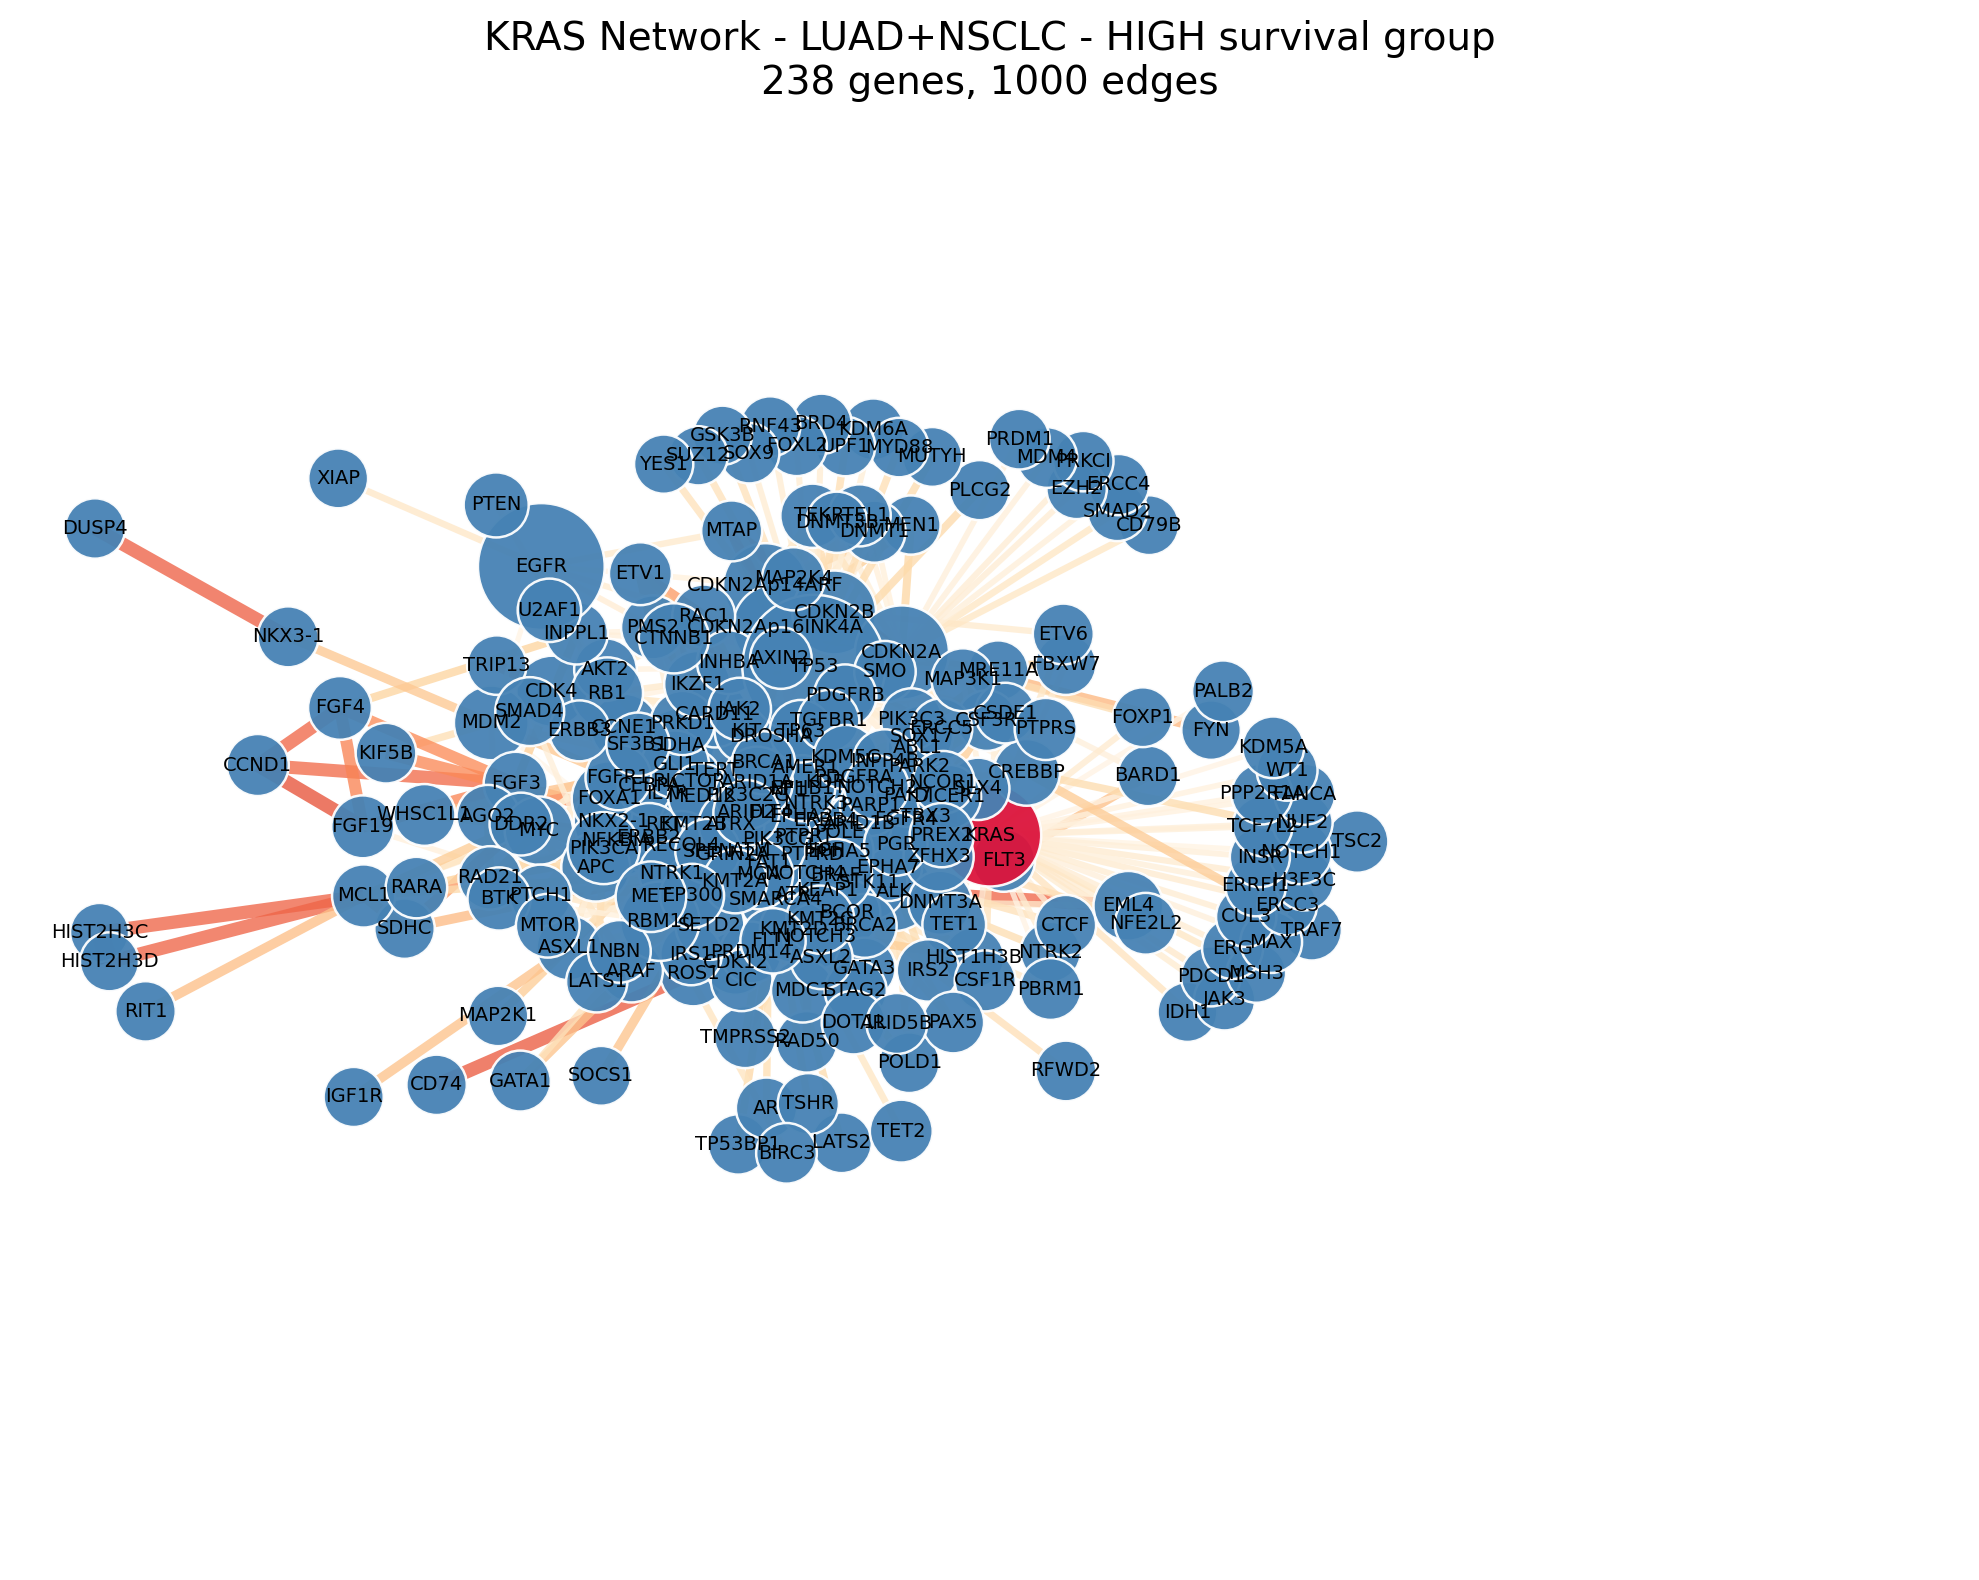


ONCOTREE GROUP: LUAD_NSCLC (LUAD+NSCLC)
SURVIVAL GROUP: low
Patients: 848
Genes: 605
Edges after filters: 860
KRAS subgraph: 238 genes, 860 edges


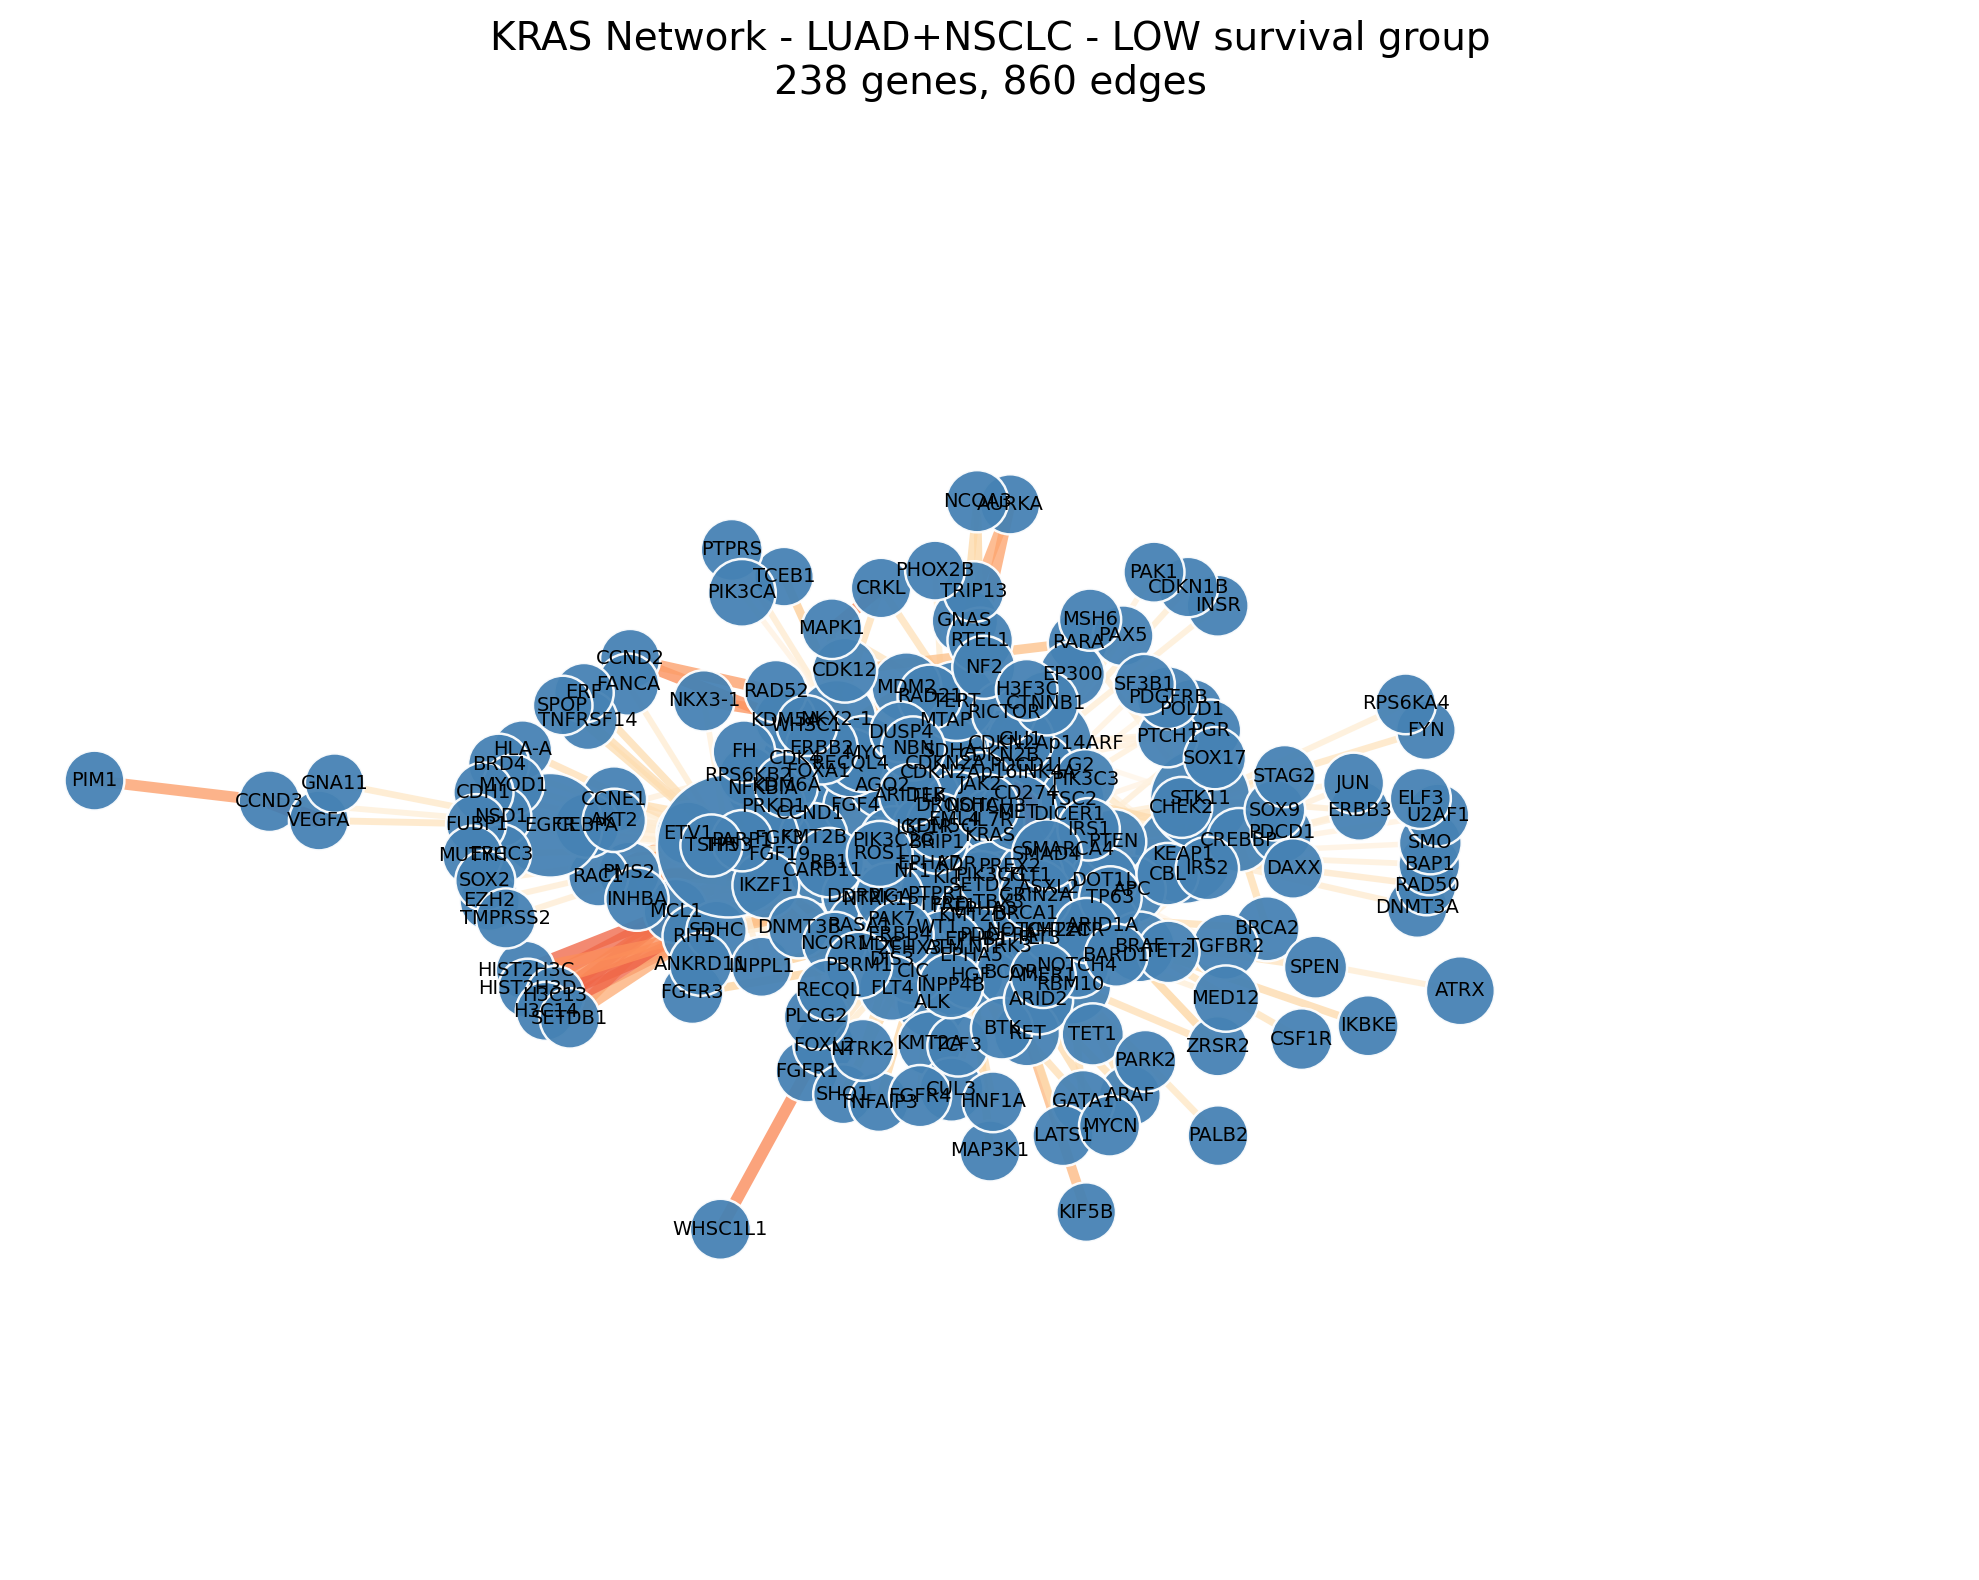


ONCOTREE GROUP: LUSC_NSCLC (LUSC+NSCLC)
SURVIVAL GROUP: high
Patients: 151
Genes: 431
Edges after filters: 86
KRAS subgraph: 34 genes, 79 edges


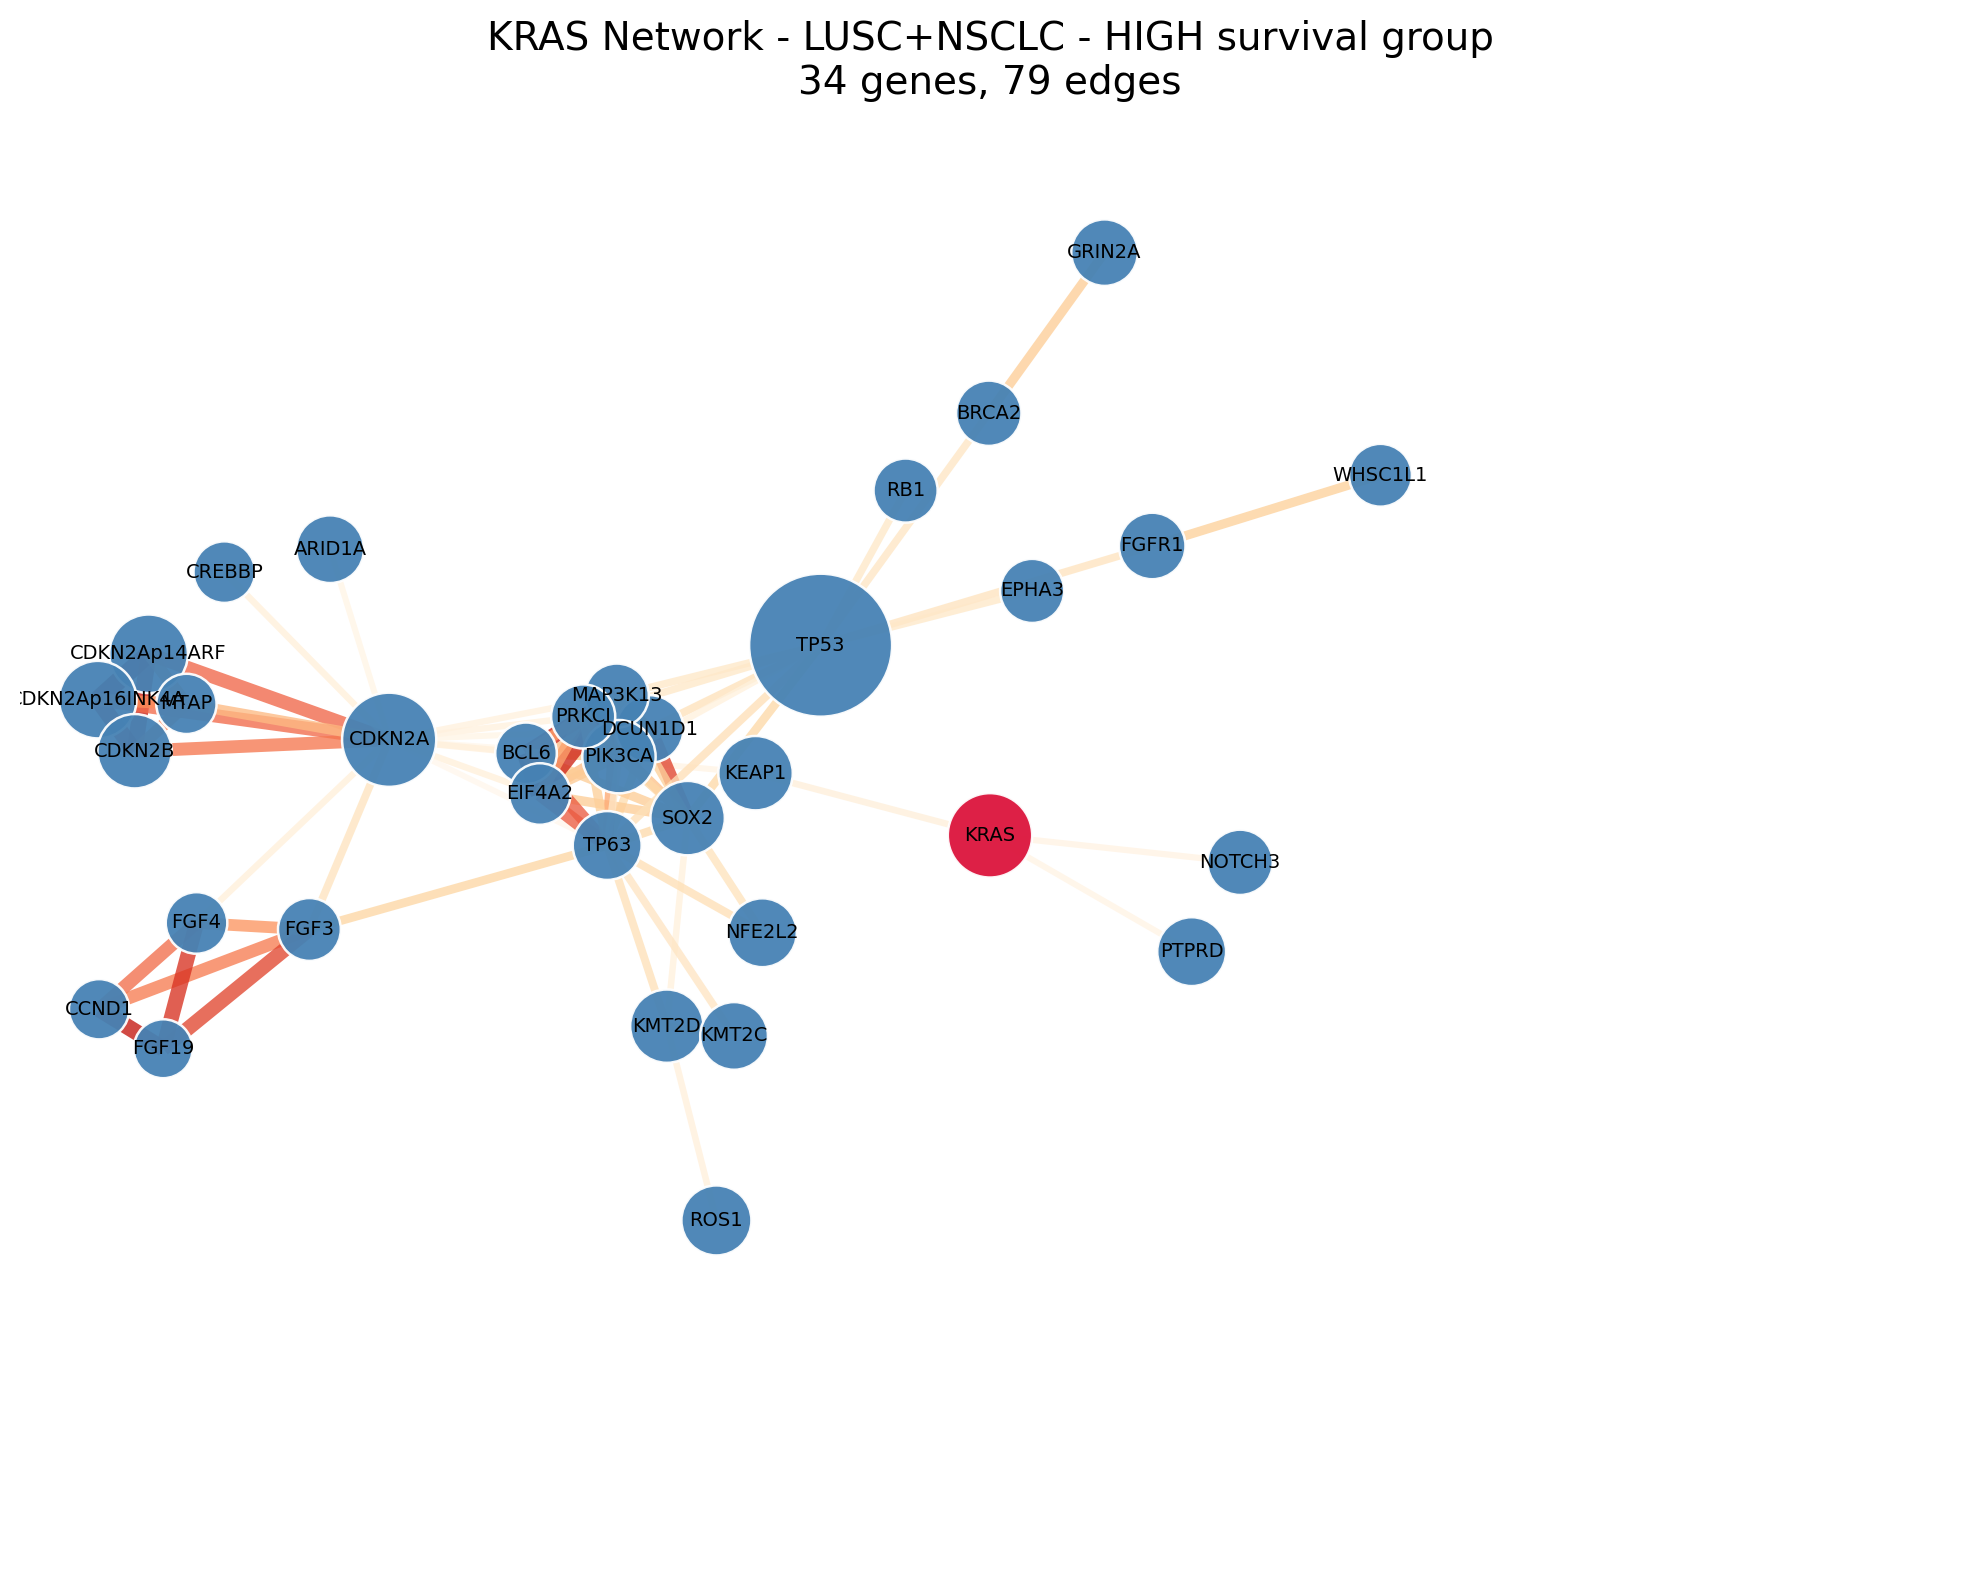


ONCOTREE GROUP: LUSC_NSCLC (LUSC+NSCLC)
SURVIVAL GROUP: low
Patients: 150
Genes: 434
Edges after filters: 92
KRAS subgraph: 13 genes, 14 edges


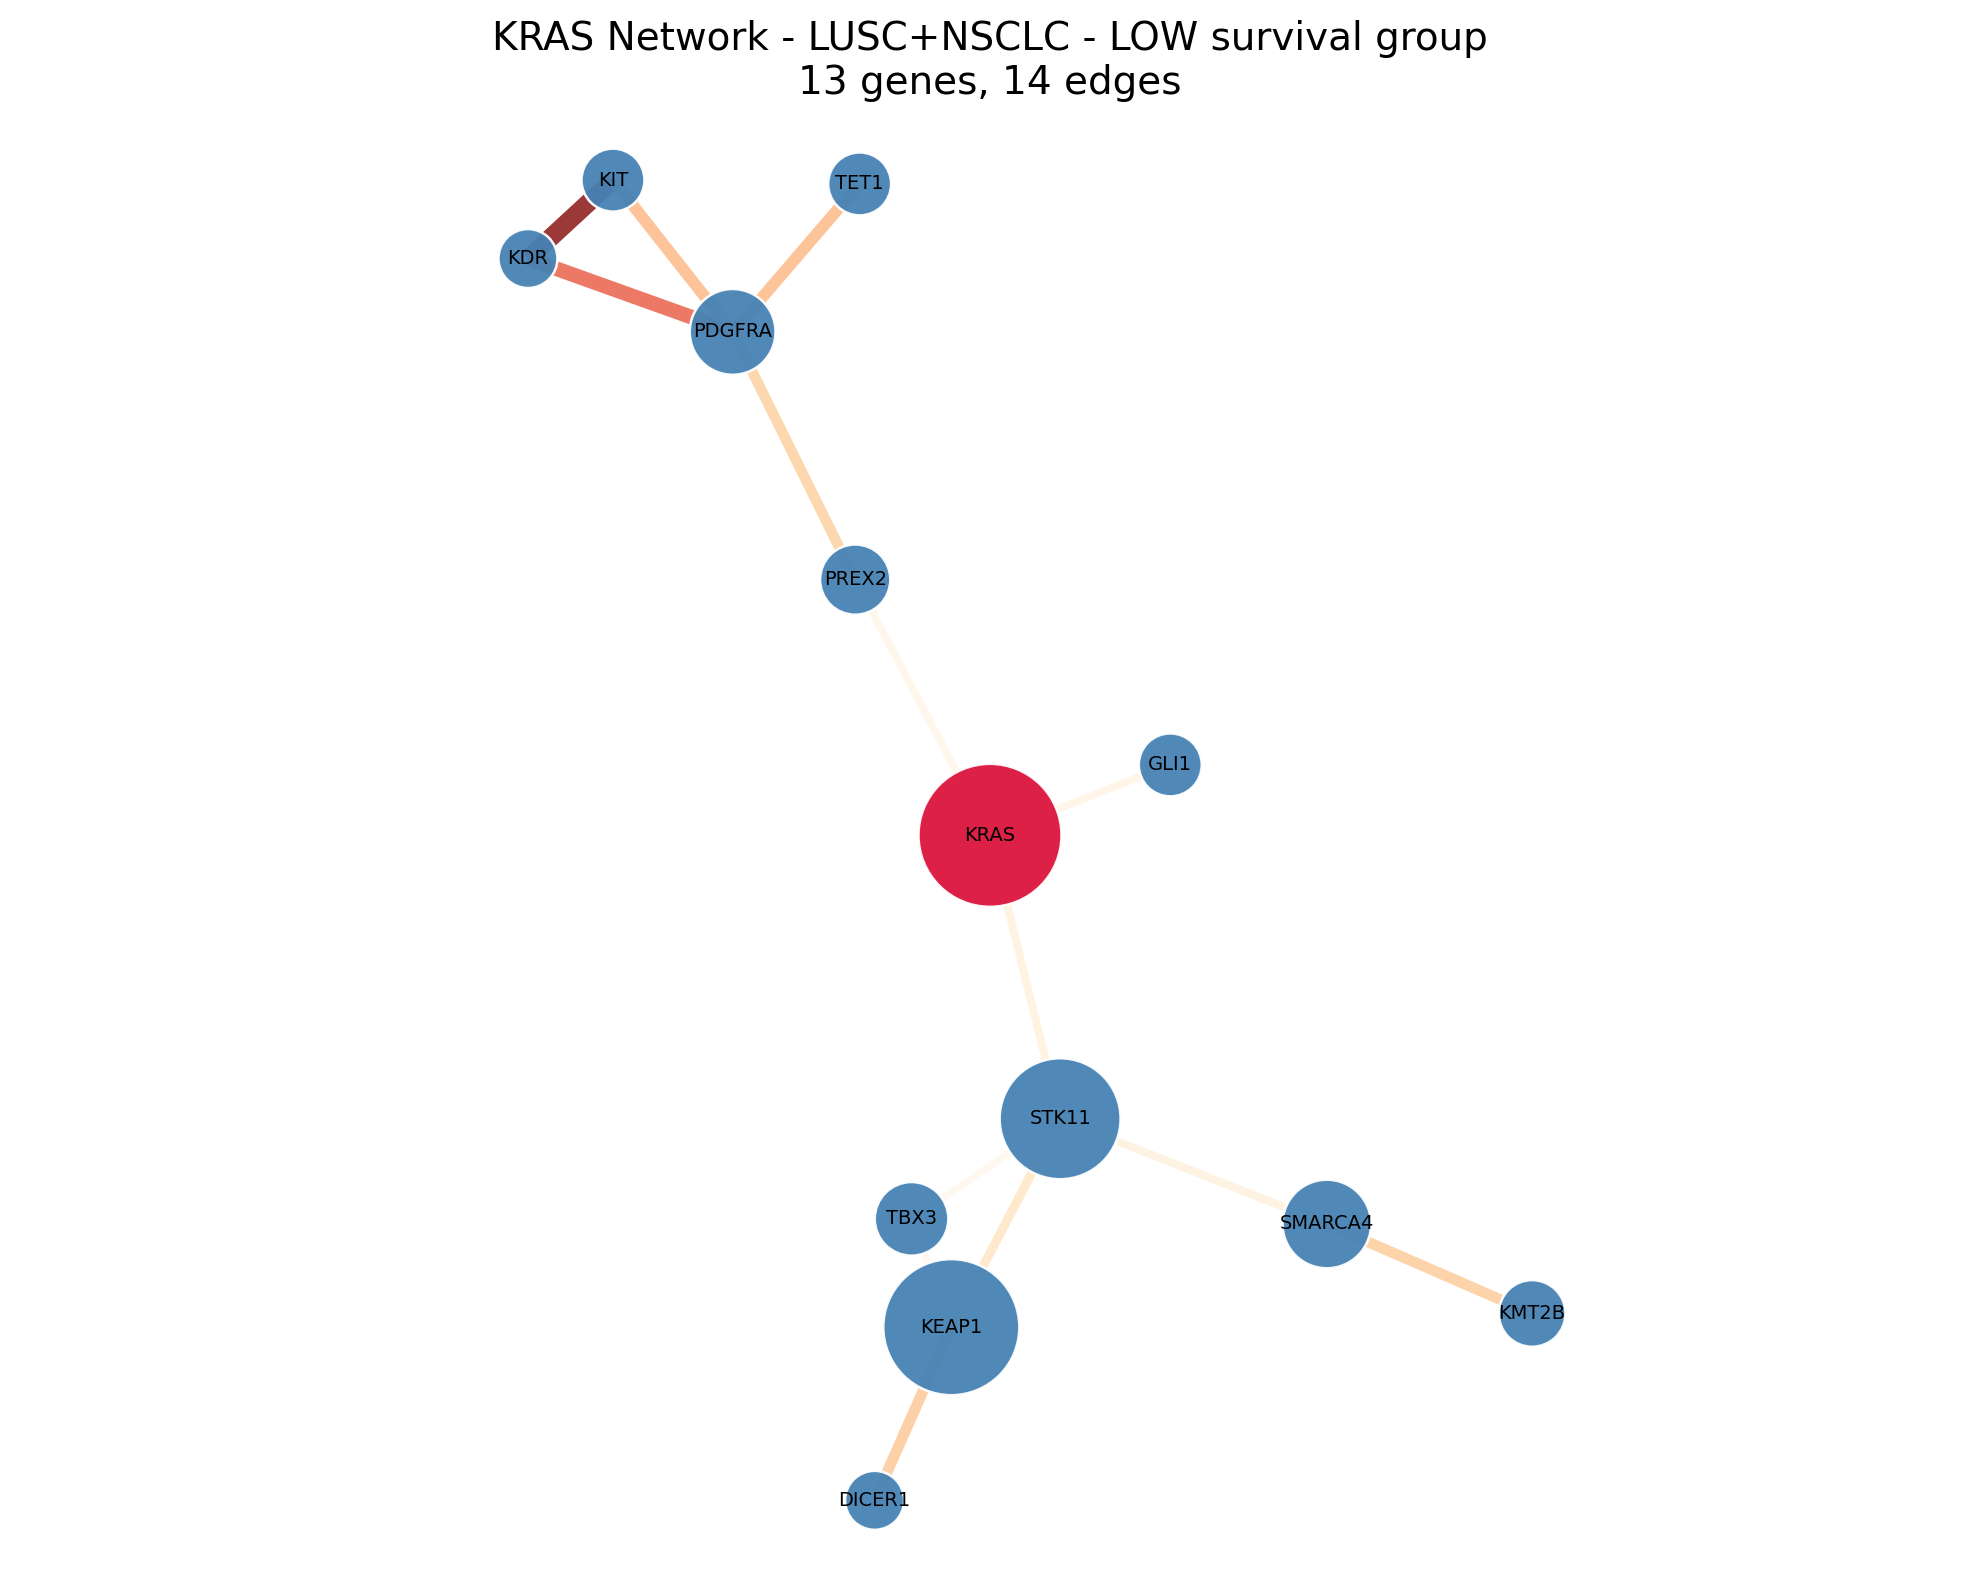


Clinical-to-network summary by Oncotree Group and survival group:


,Oncotree_Group,Included_Oncotree_Codes,survival_group,n_patients,n_rows,n_genes_input,graph_nodes,graph_edges,contains_KRAS
0,LUAD_NSCLC,LUAD+NSCLC,high,849,8596,587,238,1000,True
1,LUAD_NSCLC,LUAD+NSCLC,low,848,9400,605,238,860,True
2,LUSC_NSCLC,LUSC+NSCLC,high,151,1954,431,34,79,True
3,LUSC_NSCLC,LUSC+NSCLC,low,150,2040,434,13,14,True


In [51]:
import pandas as pd
import networkx as nx
import matplotlib.pyplot as plt
import numpy as np
from pathlib import Path
from scipy.stats import fisher_exact


# ============================================================
# SETTINGS
# ============================================================

min_log2_or = 1
max_p_value = 0.05
min_shared = 5
max_hops_from_kras = None

min_patients_for_network = 10

# File nuovo, già annotato con survival_group stratificato per gruppi Oncotree
file_path_merged = (
        Path("data_lung")
        / "CLINICAL_merged_mutations_cna_sv_with_survival_groups_BY_ONCOTREE_GROUPS.csv"
)

# Gruppi istologici da analizzare
selected_oncotree_groups = ["LUAD_NSCLC", "LUSC_NSCLC"]

group_labels = {
    "LUAD_NSCLC": "LUAD+NSCLC",
    "LUSC_NSCLC": "LUSC+NSCLC",
}

survival_groups_to_analyze = ["high", "low"]


# ============================================================
# FUNCTION: build KRAS-focused graph for one Oncotree Group + survival group
# ============================================================

def build_kras_network_for_oncotree_survival_group(
        df,
        oncotree_group,
        group_name,
        oncotree_col="Oncotree_Group",
        group_col="survival_group",
        patient_col="Patient_ID",
        gene_col="Hugo_Symbol",
        min_log2_or=1,
        max_p_value=0.05,
        min_shared=5,
        max_hops_from_kras=None,
        min_patients_for_network=10
):

    readable_group = group_labels.get(oncotree_group, oncotree_group)

    df_group = df[
        (df[oncotree_col] == oncotree_group)
        & (df[group_col] == group_name)
        ].copy()

    tmp = (
        df_group[[patient_col, gene_col]]
        .dropna()
        .drop_duplicates()
    )

    print("\n" + "=" * 90)
    print(f"ONCOTREE GROUP: {oncotree_group} ({readable_group})")
    print(f"SURVIVAL GROUP: {group_name}")
    print(f"Patients: {tmp[patient_col].nunique()}")
    print(f"Genes: {tmp[gene_col].nunique()}")

    if tmp[patient_col].nunique() < min_patients_for_network:
        print(f"Skipped: fewer than {min_patients_for_network} patients.")
        return None, None, df_group

    if tmp[gene_col].nunique() < 2:
        print("Skipped: fewer than 2 genes.")
        return None, None, df_group

    patient_gene = pd.crosstab(
        tmp[patient_col],
        tmp[gene_col]
    ).astype(bool).astype(int)

    N = patient_gene.shape[0]
    gene_counts = patient_gene.sum(axis=0)

    co = patient_gene.T @ patient_gene

    co_np = co.to_numpy(copy=True)
    np.fill_diagonal(co_np, 0)

    co = pd.DataFrame(
        co_np,
        index=co.index,
        columns=co.columns
    )

    edges = (
        co.where(np.triu(np.ones(co.shape), k=1).astype(bool))
        .stack()
        .rename("a_both")
        .rename_axis(index=["Gene1", "Gene2"])
        .reset_index()
    )

    edges = edges.dropna(subset=["a_both"]).copy()
    edges["a_both"] = edges["a_both"].astype(int)

    rows = []

    for r in edges.itertuples(index=False):
        g1, g2, a = r.Gene1, r.Gene2, int(r.a_both)

        b = int(gene_counts[g1] - a)
        c = int(gene_counts[g2] - a)
        d = int(N - a - b - c)

        odds_ratio, p_value = fisher_exact(
            [[a, b], [c, d]],
            alternative="greater"
        )

        log2_or = np.log2(
            ((a + 0.5) * (d + 0.5)) /
            ((b + 0.5) * (c + 0.5))
        )

        rows.append([
            g1,
            g2,
            a,
            b,
            c,
            d,
            odds_ratio,
            log2_or,
            p_value
        ])

    results = pd.DataFrame(
        rows,
        columns=[
            "Gene1",
            "Gene2",
            "a_both",
            "b_g1_only",
            "c_g2_only",
            "d_neither",
            "odds_ratio",
            "log2_OR",
            "p_value"
        ]
    )

    results["Oncotree_Group"] = oncotree_group
    results["Included_Oncotree_Codes"] = readable_group
    results["survival_group"] = group_name
    results["n_patients_group"] = N

    edges_plot = (
        results[
            (results["log2_OR"] > min_log2_or)
            & (results["p_value"] < max_p_value)
            & (results["a_both"] >= min_shared)
            ]
        .sort_values(["p_value", "log2_OR"], ascending=[True, False])
        .copy()
    )

    print(f"Edges after filters: {len(edges_plot)}")

    G_plot = nx.Graph()

    for _, row in edges_plot.iterrows():
        G_plot.add_edge(
            row["Gene1"],
            row["Gene2"],
            log2_or=float(row["log2_OR"]),
            p_value=float(row["p_value"]),
            shared=int(row["a_both"]),
            oncotree_group=oncotree_group,
            included_oncotree_codes=readable_group,
            survival_group=group_name
        )

    if G_plot.number_of_nodes() == 0 or G_plot.number_of_edges() == 0:
        print("No edges with current thresholds.")
        return G_plot, results, df_group

    kras_nodes = [
        n for n in G_plot.nodes()
        if str(n).upper() == "KRAS"
    ]

    if not kras_nodes:
        print("KRAS is not present with these thresholds.")
        return G_plot, results, df_group

    kras_node = kras_nodes[0]

    distances = nx.single_source_shortest_path_length(
        G_plot,
        kras_node
    )

    if max_hops_from_kras is None:
        keep_nodes = set(distances.keys())
    else:
        keep_nodes = {
            n for n, d in distances.items()
            if d <= max_hops_from_kras
        }

    G_kras = G_plot.subgraph(keep_nodes).copy()

    print(
        f"KRAS subgraph: "
        f"{G_kras.number_of_nodes()} genes, "
        f"{G_kras.number_of_edges()} edges"
    )

    return G_kras, results, df_group


# ============================================================
# FUNCTION: plot KRAS-focused graph
# ============================================================

def plot_kras_network(
        G_kras,
        df_group,
        oncotree_group,
        group_name,
        patient_col="Patient_ID",
        gene_col="Hugo_Symbol"
):

    readable_group = group_labels.get(oncotree_group, oncotree_group)

    if G_kras is None or G_kras.number_of_edges() == 0:
        print(f"No graph to plot for {oncotree_group} - {group_name}")
        return

    kras_nodes = [
        n for n in G_kras.nodes()
        if str(n).upper() == "KRAS"
    ]

    if not kras_nodes:
        print(f"KRAS not found in graph for {oncotree_group} - {group_name}")
        return

    kras_node = kras_nodes[0]

    tmp = (
        df_group[[patient_col, gene_col]]
        .dropna()
        .drop_duplicates()
    )

    patient_gene = pd.crosstab(
        tmp[patient_col],
        tmp[gene_col]
    ).astype(bool).astype(int)

    gene_support = patient_gene.sum(axis=0).to_dict()

    plt.figure(figsize=(10, 8), dpi=200)

    local_dist = nx.single_source_shortest_path_length(
        G_kras,
        kras_node
    )

    max_d = max(local_dist.values())

    shells = [[kras_node]] + [
        [n for n in G_kras.nodes() if local_dist[n] == d]
        for d in range(1, max_d + 1)
    ]

    pos0 = nx.shell_layout(G_kras, nlist=shells)
    pos0[kras_node] = np.array([0.0, 0.0])

    pos = nx.spring_layout(
        G_kras,
        seed=42,
        k=0.9,
        pos=pos0,
        fixed=[kras_node],
        center=(0, 0),
        iterations=200
    )

    support_vals = [
        float(gene_support.get(n, 1))
        for n in G_kras.nodes()
    ]

    s_min = min(support_vals) if support_vals else 1.0
    s_max = max(support_vals) if support_vals else 1.0

    if s_max == s_min:
        node_sizes = [1000 for _ in G_kras.nodes()]
    else:
        node_sizes = [
            450 + 2200 *
            ((float(gene_support.get(n, s_min)) - s_min) / (s_max - s_min))
            for n in G_kras.nodes()
        ]

    node_colors = [
        "crimson" if str(n).upper() == "KRAS" else "steelblue"
        for n in G_kras.nodes()
    ]

    edge_vals = [
        G_kras[u][v].get("log2_or", 1.0)
        for u, v in G_kras.edges()
    ]

    max_edge = max(edge_vals) if edge_vals else 1.0

    edge_widths = [
        1.4 + 5.2 * (w / max_edge)
        for w in edge_vals
    ]

    nx.draw_networkx_edges(
        G_kras,
        pos,
        width=edge_widths,
        alpha=0.78,
        edge_color=edge_vals,
        edge_cmap=plt.cm.OrRd,
        edge_vmin=min(edge_vals) if edge_vals else 0.0,
        edge_vmax=max(edge_vals) if edge_vals else 1.0
    )

    nx.draw_networkx_nodes(
        G_kras,
        pos,
        node_size=node_sizes,
        node_color=node_colors,
        alpha=0.95,
        linewidths=0.9,
        edgecolors="white"
    )

    labels_all = {n: n for n in G_kras.nodes()}

    nx.draw_networkx_labels(
        G_kras,
        pos,
        labels=labels_all,
        font_size=7
    )

    xy = np.array(list(pos.values()))

    r = float(np.abs(xy).max()) if xy.size else 1.0
    lim = r + (0.08 * r + 0.05)

    plt.xlim(-lim, lim)
    plt.ylim(-lim, lim)

    plt.title(
        f"KRAS Network - {readable_group} - {group_name.upper()} survival group\n"
        f"{G_kras.number_of_nodes()} genes, {G_kras.number_of_edges()} edges",
        fontsize=14
    )

    plt.axis("off")
    plt.tight_layout()
    plt.show()


# ============================================================
# LOAD DATA
# ============================================================

df_merge = pd.read_csv(file_path_merged, low_memory=False)
df_merge = df_merge.loc[:, ~df_merge.columns.duplicated()].copy()

df_merge = df_merge.rename(columns={
    "PATIENT_ID": "Patient_ID",
    "ONCOTREE_CODE": "ONCOTREE_CODE",
    "Oncotree Code": "ONCOTREE_CODE",
    "Oncotree_Group": "Oncotree_Group",
    "ONCOTREE_GROUP": "Oncotree_Group",
    "Oncotree Group": "Oncotree_Group",
    "Gene": "Hugo_Symbol"
})

df_merge = df_merge.loc[:, ~df_merge.columns.duplicated()].copy()

required_cols = {
    "Patient_ID",
    "Hugo_Symbol",
    "Oncotree_Group",
    "survival_group"
}

missing_cols = required_cols - set(df_merge.columns)

if missing_cols:
    raise ValueError(
        f"Colonne mancanti nel file merged clinical-to-network per gruppi: {missing_cols}"
    )

df_merge["Patient_ID"] = df_merge["Patient_ID"].astype(str)
df_merge["Hugo_Symbol"] = df_merge["Hugo_Symbol"].astype(str)
df_merge["Oncotree_Group"] = df_merge["Oncotree_Group"].astype(str)
df_merge["survival_group"] = df_merge["survival_group"].astype(str)

if "Included_Oncotree_Codes" not in df_merge.columns:
    df_merge["Included_Oncotree_Codes"] = df_merge["Oncotree_Group"].map(group_labels)

print("Loaded:")
print(file_path_merged)

print("\nSurvival group distribution by Oncotree Group:")

try:
    display(
        df_merge
        .drop_duplicates(["Patient_ID", "Oncotree_Group"])
        .groupby(["Oncotree_Group", "Included_Oncotree_Codes", "survival_group"])
        .agg(n_patients=("Patient_ID", "nunique"))
        .reset_index()
        .sort_values(["Oncotree_Group", "survival_group"])
    )
except NameError:
    print(
        df_merge
        .drop_duplicates(["Patient_ID", "Oncotree_Group"])
        .groupby(["Oncotree_Group", "Included_Oncotree_Codes", "survival_group"])
        .agg(n_patients=("Patient_ID", "nunique"))
        .reset_index()
        .sort_values(["Oncotree_Group", "survival_group"])
    )


# ============================================================
# SELECT ONCOTREE GROUPS
# ============================================================

if selected_oncotree_groups is None:
    oncotree_groups_to_analyze = sorted(
        df_merge["Oncotree_Group"]
        .dropna()
        .unique()
    )
else:
    oncotree_groups_to_analyze = selected_oncotree_groups

oncotree_groups_to_analyze = [
    g for g in oncotree_groups_to_analyze
    if g in df_merge["Oncotree_Group"].unique()
]

print("\nOncotree Groups to analyze:")
print(oncotree_groups_to_analyze)


# ============================================================
# BUILD AND PLOT HIGH / LOW NETWORKS BY ONCOTREE GROUP
# ============================================================

graphs_by_oncotree_survival = {}
results_by_oncotree_survival = {}

for oncotree_group in oncotree_groups_to_analyze:

    graphs_by_oncotree_survival[oncotree_group] = {}
    results_by_oncotree_survival[oncotree_group] = {}

    for group_name in survival_groups_to_analyze:

        G_group, results_group, df_group = build_kras_network_for_oncotree_survival_group(
            df=df_merge,
            oncotree_group=oncotree_group,
            group_name=group_name,
            oncotree_col="Oncotree_Group",
            group_col="survival_group",
            patient_col="Patient_ID",
            gene_col="Hugo_Symbol",
            min_log2_or=min_log2_or,
            max_p_value=max_p_value,
            min_shared=min_shared,
            max_hops_from_kras=max_hops_from_kras,
            min_patients_for_network=min_patients_for_network
        )

        graphs_by_oncotree_survival[oncotree_group][group_name] = G_group
        results_by_oncotree_survival[oncotree_group][group_name] = results_group

        plot_kras_network(
            G_kras=G_group,
            df_group=df_group,
            oncotree_group=oncotree_group,
            group_name=group_name,
            patient_col="Patient_ID",
            gene_col="Hugo_Symbol"
        )


# ============================================================
# FINAL SUMMARY
# ============================================================

summary_rows = []

for oncotree_group, group_dict in graphs_by_oncotree_survival.items():

    readable_group = group_labels.get(oncotree_group, oncotree_group)

    for group_name, G in group_dict.items():

        if G is None:
            n_nodes = 0
            n_edges = 0
            has_kras = False
        else:
            n_nodes = G.number_of_nodes()
            n_edges = G.number_of_edges()
            has_kras = any(str(n).upper() == "KRAS" for n in G.nodes())

        df_tmp = df_merge[
            (df_merge["Oncotree_Group"] == oncotree_group)
            & (df_merge["survival_group"] == group_name)
            ]

        summary_rows.append({
            "Oncotree_Group": oncotree_group,
            "Included_Oncotree_Codes": readable_group,
            "survival_group": group_name,
            "n_patients": df_tmp["Patient_ID"].nunique(),
            "n_rows": df_tmp.shape[0],
            "n_genes_input": df_tmp["Hugo_Symbol"].nunique(),
            "graph_nodes": n_nodes,
            "graph_edges": n_edges,
            "contains_KRAS": has_kras
        })

clinical_network_summary = (
    pd.DataFrame(summary_rows)
    .sort_values(["Oncotree_Group", "survival_group"])
    .reset_index(drop=True)
)

print("\nClinical-to-network summary by Oncotree Group and survival group:")

try:
    display(clinical_network_summary)
except NameError:
    print(clinical_network_summary)


# ============================================================
# COMPATIBILITY ALIASES
# ============================================================

graphs_by_oncotree_group_survival = graphs_by_oncotree_survival
results_by_oncotree_group_survival = results_by_oncotree_survival

#### 3. Hub analysis e confronto HIGH vs LOW

In [52]:
import pandas as pd
import numpy as np
import networkx as nx
from pathlib import Path

# ============================================================
# HUB ANALYSIS - ONCOTREE GROUPS ORIENTED
# HIGH vs LOW survival networks within each Oncotree Group
# LUAD_NSCLC = LUAD + NSCLC
# LUSC_NSCLC = LUSC + NSCLC
# ============================================================

if "graphs_by_oncotree_survival" not in globals():
    raise ValueError(
        "graphs_by_oncotree_survival non disponibile. "
        "Esegui prima la cella che costruisce le network high/low per Oncotree Group."
    )

target_groups = ["LUAD_NSCLC", "LUSC_NSCLC"]

group_labels = {
    "LUAD_NSCLC": "LUAD+NSCLC",
    "LUSC_NSCLC": "LUSC+NSCLC",
}

hub_output_dir = (
        Path("data_lung")
        / "clinical_to_network_by_oncotree_groups"
        / "hub_analysis_by_oncotree_group_survival"
)

hub_output_dir.mkdir(parents=True, exist_ok=True)


# ============================================================
# FUNCTION: compute hub table
# ============================================================

def compute_hub_table(
        G,
        oncotree_group,
        group_name,
        weight_col="log2_or"
):
    """
    Calcola le metriche hub per una network specifica:
    - un Oncotree Group: LUAD_NSCLC / LUSC_NSCLC
    - un survival group: high / low
    """

    readable_group = group_labels.get(oncotree_group, oncotree_group)

    if G is None or G.number_of_nodes() == 0 or G.number_of_edges() == 0:
        print(f"No graph available for {oncotree_group} - {group_name}")
        return pd.DataFrame()

    degree = dict(G.degree())

    node_strength = {
        n: sum(
            G[n][nbr].get(weight_col, 1.0)
            for nbr in G.neighbors(n)
        )
        for n in G.nodes()
    }

    betweenness = nx.betweenness_centrality(
        G,
        weight=weight_col,
        normalized=True
    )

    closeness = nx.closeness_centrality(G)

    hub_df = pd.DataFrame({
        "Oncotree_Group": oncotree_group,
        "Included_Oncotree_Codes": readable_group,
        "survival_group": group_name,
        "Gene": list(G.nodes()),
        "Degree": [degree.get(g, 0) for g in G.nodes()],
        "Node_Strength": [node_strength.get(g, 0) for g in G.nodes()],
        "Betweenness": [betweenness.get(g, 0) for g in G.nodes()],
        "Closeness": [closeness.get(g, 0) for g in G.nodes()],
        "Graph_nodes": G.number_of_nodes(),
        "Graph_edges": G.number_of_edges(),
        "Graph_density": nx.density(G)
    })

    # HubScore composito
    hub_df["HubScore"] = (
            hub_df["Degree"].rank(pct=True) * 0.25
            + hub_df["Node_Strength"].rank(pct=True) * 0.25
            + hub_df["Betweenness"].rank(pct=True) * 0.25
            + hub_df["Closeness"].rank(pct=True) * 0.25
    )

    hub_df = hub_df.sort_values(
        "HubScore",
        ascending=False
    ).reset_index(drop=True)

    hub_df["Rank_in_network"] = hub_df.index + 1

    return hub_df


# ============================================================
# 1. Compute hub tables for each Oncotree Group and survival group
# ============================================================

hub_tables_by_oncotree_survival = {}
all_hub_tables_survival = []

for oncotree_group, group_graphs in graphs_by_oncotree_survival.items():

    if oncotree_group not in target_groups:
        continue

    readable_group = group_labels.get(oncotree_group, oncotree_group)

    hub_tables_by_oncotree_survival[oncotree_group] = {}

    for group_name, G in group_graphs.items():

        hub_df = compute_hub_table(
            G=G,
            oncotree_group=oncotree_group,
            group_name=group_name
        )

        hub_tables_by_oncotree_survival[oncotree_group][group_name] = hub_df

        if not hub_df.empty:
            all_hub_tables_survival.append(hub_df)

            output_file = (
                    hub_output_dir
                    / f"hub_genes_{oncotree_group}_{group_name}_survival_network.csv"
            )

            hub_df.to_csv(output_file, index=False)

            print(f"Saved: {output_file}")


# ============================================================
# 2. Combined hub table
# ============================================================

if len(all_hub_tables_survival) > 0:
    hub_all_oncotree_survival = pd.concat(
        all_hub_tables_survival,
        ignore_index=True
    )

    hub_all_file = (
            hub_output_dir
            / "hub_genes_all_oncotree_group_survival_networks.csv"
    )

    hub_all_oncotree_survival.to_csv(
        hub_all_file,
        index=False
    )

    print("\nSaved combined hub table:")
    print(hub_all_file)

else:
    hub_all_oncotree_survival = pd.DataFrame()
    print("No hub tables were created.")


# ============================================================
# 3. Display top hubs per Oncotree Group and survival group
# ============================================================

top_n = 20

for oncotree_group, group_tables in hub_tables_by_oncotree_survival.items():

    readable_group = group_labels.get(oncotree_group, oncotree_group)

    print("\n" + "#" * 100)
    print(f"ONCOTREE GROUP: {oncotree_group} ({readable_group})")
    print("#" * 100)

    for group_name in ["high", "low"]:

        hub_df = group_tables.get(group_name, pd.DataFrame())

        print("\n" + "=" * 90)
        print(
            f"TOP HUB GENES - {oncotree_group} ({readable_group}) - "
            f"{group_name.upper()} SURVIVAL NETWORK"
        )
        print("=" * 90)

        if hub_df is None or hub_df.empty:
            print(f"No hub table available for {oncotree_group} - {group_name}")
            continue

        print(
            f"Questa tabella mostra i geni più centrali nella rete costruita solo sui pazienti "
            f"{group_name.upper()} survival del gruppo {readable_group}."
        )

        display(
            hub_df[
                [
                    "Oncotree_Group",
                    "Included_Oncotree_Codes",
                    "survival_group",
                    "Gene",
                    "Degree",
                    "Node_Strength",
                    "Betweenness",
                    "Closeness",
                    "HubScore",
                    "Rank_in_network"
                ]
            ].head(top_n)
        )


# ============================================================
# 4. Compare HIGH vs LOW hub scores within each Oncotree Group
# ============================================================

comparison_tables = []

for oncotree_group, group_tables in hub_tables_by_oncotree_survival.items():

    readable_group = group_labels.get(oncotree_group, oncotree_group)

    hub_high = group_tables.get("high", pd.DataFrame())
    hub_low = group_tables.get("low", pd.DataFrame())

    if hub_high is None or hub_high.empty:
        print(f"[{oncotree_group}] HIGH hub table missing or empty. Skipping comparison.")
        continue

    if hub_low is None or hub_low.empty:
        print(f"[{oncotree_group}] LOW hub table missing or empty. Skipping comparison.")
        continue

    hub_high_for_merge = hub_high.copy()
    hub_low_for_merge = hub_low.copy()

    hub_high_for_merge = hub_high_for_merge.drop(
        columns=["survival_group"],
        errors="ignore"
    )

    hub_low_for_merge = hub_low_for_merge.drop(
        columns=["survival_group"],
        errors="ignore"
    )

    hub_comparison = hub_high_for_merge.merge(
        hub_low_for_merge,
        on=["Oncotree_Group", "Included_Oncotree_Codes", "Gene"],
        how="outer",
        suffixes=("_high", "_low")
    )

    hub_comparison["Delta_HubScore_high_minus_low"] = (
            hub_comparison["HubScore_high"].fillna(0)
            - hub_comparison["HubScore_low"].fillna(0)
    )

    hub_comparison["Delta_Degree_high_minus_low"] = (
            hub_comparison["Degree_high"].fillna(0)
            - hub_comparison["Degree_low"].fillna(0)
    )

    hub_comparison["Delta_Node_Strength_high_minus_low"] = (
            hub_comparison["Node_Strength_high"].fillna(0)
            - hub_comparison["Node_Strength_low"].fillna(0)
    )

    comparison_tables.append(hub_comparison)

    output_file = (
            hub_output_dir
            / f"hub_genes_{oncotree_group}_high_vs_low_comparison.csv"
    )

    hub_comparison.to_csv(output_file, index=False)

    print(f"\nSaved comparison for {oncotree_group}:")
    print(output_file)

    # ------------------------------------------------------------
    # Genes more important in HIGH survival network
    # ------------------------------------------------------------

    print("\n" + "=" * 90)
    print(f"GENES MORE IMPORTANT IN HIGH SURVIVAL NETWORK - {oncotree_group} ({readable_group})")
    print("=" * 90)
    print(
        "Delta positivo = il gene è più hub/importante nella rete HIGH "
        "rispetto alla rete LOW, dentro lo stesso gruppo istologico."
    )

    display(
        hub_comparison
        .sort_values("Delta_HubScore_high_minus_low", ascending=False)
        [
            [
                "Oncotree_Group",
                "Included_Oncotree_Codes",
                "Gene",
                "HubScore_high",
                "HubScore_low",
                "Delta_HubScore_high_minus_low",
                "Degree_high",
                "Degree_low",
                "Node_Strength_high",
                "Node_Strength_low"
            ]
        ]
        .head(top_n)
    )

    # ------------------------------------------------------------
    # Genes more important in LOW survival network
    # ------------------------------------------------------------

    print("\n" + "=" * 90)
    print(f"GENES MORE IMPORTANT IN LOW SURVIVAL NETWORK - {oncotree_group} ({readable_group})")
    print("=" * 90)
    print(
        "Delta negativo = il gene è più hub/importante nella rete LOW "
        "rispetto alla rete HIGH, dentro lo stesso gruppo istologico."
    )

    display(
        hub_comparison
        .sort_values("Delta_HubScore_high_minus_low", ascending=True)
        [
            [
                "Oncotree_Group",
                "Included_Oncotree_Codes",
                "Gene",
                "HubScore_high",
                "HubScore_low",
                "Delta_HubScore_high_minus_low",
                "Degree_high",
                "Degree_low",
                "Node_Strength_high",
                "Node_Strength_low"
            ]
        ]
        .head(top_n)
    )


# ============================================================
# 5. Combined comparison table
# ============================================================

if len(comparison_tables) > 0:
    hub_comparison_all_oncotree = pd.concat(
        comparison_tables,
        ignore_index=True
    )

    combined_comparison_file = (
            hub_output_dir
            / "hub_genes_high_vs_low_comparison_all_oncotree_groups.csv"
    )

    hub_comparison_all_oncotree.to_csv(
        combined_comparison_file,
        index=False
    )

    print("\nSaved combined high vs low comparison:")
    print(combined_comparison_file)

    print("\nCombined comparison preview:")

    display(
        hub_comparison_all_oncotree
        .sort_values(
            ["Oncotree_Group", "Delta_HubScore_high_minus_low"],
            ascending=[True, False]
        )
        .head(40)
    )

else:
    hub_comparison_all_oncotree = pd.DataFrame()
    print("No high vs low comparison table was created.")


# ============================================================
# OPTIONAL COMPATIBILITY ALIASES
# ============================================================

hub_tables_by_oncotree_group_survival = hub_tables_by_oncotree_survival
hub_comparison_all_oncotree_groups = hub_comparison_all_oncotree

Saved: data_lung\clinical_to_network_by_oncotree_groups\hub_analysis_by_oncotree_group_survival\hub_genes_LUAD_NSCLC_high_survival_network.csv
Saved: data_lung\clinical_to_network_by_oncotree_groups\hub_analysis_by_oncotree_group_survival\hub_genes_LUAD_NSCLC_low_survival_network.csv
Saved: data_lung\clinical_to_network_by_oncotree_groups\hub_analysis_by_oncotree_group_survival\hub_genes_LUSC_NSCLC_high_survival_network.csv
Saved: data_lung\clinical_to_network_by_oncotree_groups\hub_analysis_by_oncotree_group_survival\hub_genes_LUSC_NSCLC_low_survival_network.csv

Saved combined hub table:
data_lung\clinical_to_network_by_oncotree_groups\hub_analysis_by_oncotree_group_survival\hub_genes_all_oncotree_group_survival_networks.csv

####################################################################################################
ONCOTREE GROUP: LUAD_NSCLC (LUAD+NSCLC)
####################################################################################################

TOP HUB GENES - LUA

,Oncotree_Group,Included_Oncotree_Codes,survival_group,Gene,Degree,Node_Strength,Betweenness,Closeness,HubScore,Rank_in_network
0,LUAD_NSCLC,LUAD+NSCLC,high,PTPRD,65,142.432415,0.155081,0.523179,0.993697,1
1,LUAD_NSCLC,LUAD+NSCLC,high,KRAS,67,119.656534,0.297004,0.482688,0.992647,2
2,LUAD_NSCLC,LUAD+NSCLC,high,PTPRT,74,181.550339,0.050454,0.502119,0.991597,3
3,LUAD_NSCLC,LUAD+NSCLC,high,TP53,56,119.677403,0.207860,0.471173,0.986345,4
4,LUAD_NSCLC,LUAD+NSCLC,high,SMARCA4,47,103.243381,0.090539,0.490683,0.981092,5
5,LUAD_NSCLC,LUAD+NSCLC,high,FAT1,48,110.975827,0.040478,0.475904,0.975840,6
6,LUAD_NSCLC,LUAD+NSCLC,high,KEAP1,37,77.539091,0.063684,0.473054,0.970588,7
7,LUAD_NSCLC,LUAD+NSCLC,high,TERT,40,91.897801,0.097583,0.458414,0.969538,8
8,LUAD_NSCLC,LUAD+NSCLC,high,CDKN2A,42,109.240097,0.162912,0.433272,0.951681,9
9,LUAD_NSCLC,LUAD+NSCLC,high,SDHA,29,68.970132,0.039405,0.448015,0.941176,10



TOP HUB GENES - LUAD_NSCLC (LUAD+NSCLC) - LOW SURVIVAL NETWORK
Questa tabella mostra i geni più centrali nella rete costruita solo sui pazienti LOW survival del gruppo LUAD+NSCLC.


,Oncotree_Group,Included_Oncotree_Codes,survival_group,Gene,Degree,Node_Strength,Betweenness,Closeness,HubScore,Rank_in_network
0,LUAD_NSCLC,LUAD+NSCLC,low,TP53,55,105.045333,0.302868,0.448864,0.996849,1
1,LUAD_NSCLC,LUAD+NSCLC,low,NTRK3,40,87.039891,0.088643,0.458414,0.989496,2
2,LUAD_NSCLC,LUAD+NSCLC,low,PTPRD,46,100.917789,0.076271,0.451429,0.986345,3
3,LUAD_NSCLC,LUAD+NSCLC,low,CDKN2Ap14ARF,36,95.302713,0.094972,0.434066,0.983718,4
4,LUAD_NSCLC,LUAD+NSCLC,low,FAT1,38,83.533239,0.077344,0.445489,0.978992,5
5,LUAD_NSCLC,LUAD+NSCLC,low,EPHA3,35,74.471376,0.079346,0.478788,0.976891,6
6,LUAD_NSCLC,LUAD+NSCLC,low,PTPRT,36,71.009459,0.084031,0.447170,0.974265,7
7,LUAD_NSCLC,LUAD+NSCLC,low,SMARCA4,31,56.775745,0.110992,0.444653,0.969538,8
8,LUAD_NSCLC,LUAD+NSCLC,low,CDKN2Ap16INK4A,30,82.921759,0.060287,0.422460,0.959034,9
9,LUAD_NSCLC,LUAD+NSCLC,low,KEAP1,32,62.900339,0.090682,0.414336,0.954832,10



####################################################################################################
ONCOTREE GROUP: LUSC_NSCLC (LUSC+NSCLC)
####################################################################################################

TOP HUB GENES - LUSC_NSCLC (LUSC+NSCLC) - HIGH SURVIVAL NETWORK
Questa tabella mostra i geni più centrali nella rete costruita solo sui pazienti HIGH survival del gruppo LUSC+NSCLC.


,Oncotree_Group,Included_Oncotree_Codes,survival_group,Gene,Degree,Node_Strength,Betweenness,Closeness,HubScore,Rank_in_network
0,LUSC_NSCLC,LUSC+NSCLC,high,CDKN2A,16,55.260318,0.702652,0.540984,0.985294,1
1,LUSC_NSCLC,LUSC+NSCLC,high,TP63,13,57.527016,0.202652,0.550000,0.970588,2
2,LUSC_NSCLC,LUSC+NSCLC,high,PIK3CA,9,34.550111,0.225379,0.492537,0.838235,3
3,LUSC_NSCLC,LUSC+NSCLC,high,TP53,10,31.248037,0.331439,0.440000,0.823529,4
4,LUSC_NSCLC,LUSC+NSCLC,high,SOX2,10,45.545326,0.045455,0.434211,0.797794,5
5,LUSC_NSCLC,LUSC+NSCLC,high,MAP3K13,9,50.424507,0.000000,0.492537,0.738971,6
6,LUSC_NSCLC,LUSC+NSCLC,high,DCUN1D1,9,45.008501,0.000000,0.492537,0.724265,7
7,LUSC_NSCLC,LUSC+NSCLC,high,PRKCI,9,43.932101,0.000000,0.492537,0.716912,8
8,LUSC_NSCLC,LUSC+NSCLC,high,BCL6,8,54.238945,0.000000,0.445946,0.705882,9
9,LUSC_NSCLC,LUSC+NSCLC,high,EIF4A2,8,54.238945,0.000000,0.445946,0.705882,10


... (8 outputs left out)


GENES MORE IMPORTANT IN LOW SURVIVAL NETWORK - LUSC_NSCLC (LUSC+NSCLC)
Delta negativo = il gene è più hub/importante nella rete LOW rispetto alla rete HIGH, dentro lo stesso gruppo istologico.


,Oncotree_Group,Included_Oncotree_Codes,Gene,HubScore_high,HubScore_low,Delta_HubScore_high_minus_low,Degree_high,Degree_low,Node_Strength_high,Node_Strength_low
39,LUSC_NSCLC,LUSC+NSCLC,STK11,NaN,0.903846,-0.903846,NaN,4.0,NaN,9.386194
30,LUSC_NSCLC,LUSC+NSCLC,PDGFRA,NaN,0.875000,-0.875000,NaN,4.0,NaN,18.193816
32,LUSC_NSCLC,LUSC+NSCLC,PREX2,NaN,0.673077,-0.673077,NaN,2.0,NaN,5.683638
37,LUSC_NSCLC,LUSC+NSCLC,SMARCA4,NaN,0.576923,-0.576923,NaN,2.0,NaN,6.115779
19,LUSC_NSCLC,LUSC+NSCLC,KDR,NaN,0.528846,-0.528846,NaN,2.0,NaN,13.877219
21,LUSC_NSCLC,LUSC+NSCLC,KIT,NaN,0.509615,-0.509615,NaN,2.0,NaN,12.247815
40,LUSC_NSCLC,LUSC+NSCLC,TBX3,NaN,0.413462,-0.413462,NaN,2.0,NaN,3.892603
25,LUSC_NSCLC,LUSC+NSCLC,KRAS,0.455882,0.846154,-0.390271,3.0,3.0,6.217899,6.471805
41,LUSC_NSCLC,LUSC+NSCLC,TET1,NaN,0.278846,-0.278846,NaN,1.0,NaN,4.309608
17,LUSC_NSCLC,LUSC+NSCLC,GLI1,NaN,0.259615,-0.259615,NaN,1.0,NaN,2.144357



Saved combined high vs low comparison:
data_lung\clinical_to_network_by_oncotree_groups\hub_analysis_by_oncotree_group_survival\hub_genes_high_vs_low_comparison_all_oncotree_groups.csv

Combined comparison preview:


,Oncotree_Group,Included_Oncotree_Codes,Gene,Degree_high,Node_Strength_high,Betweenness_high,Closeness_high,Graph_nodes_high,Graph_edges_high,Graph_density_high,...,Betweenness_low,Closeness_low,Graph_nodes_low,Graph_edges_low,Graph_density_low,HubScore_low,Rank_in_network_low,Delta_HubScore_high_minus_low,Delta_Degree_high_minus_low,Delta_Node_Strength_high_minus_low
212,LUAD_NSCLC,LUAD+NSCLC,POLE,18.0,46.091337,0.000107,0.434066,238.0,1000.0,0.035457,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.827731,18.0,46.091337
13,LUAD_NSCLC,LUAD+NSCLC,ASXL1,6.0,16.903063,0.008439,0.364615,238.0,1000.0,0.035457,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.621324,6.0,16.903063
17,LUAD_NSCLC,LUAD+NSCLC,ATRX,8.0,19.115936,0.010727,0.423214,238.0,1000.0,0.035457,...,0.000000,0.246362,238.0,860.0,0.030493,0.132878,235.0,0.615021,7.0,16.906808
258,LUAD_NSCLC,LUAD+NSCLC,SPEN,11.0,26.484576,0.001001,0.430909,238.0,1000.0,0.035457,...,0.000000,0.275261,238.0,860.0,0.030493,0.161239,222.0,0.606618,10.0,23.481677
249,LUAD_NSCLC,LUAD+NSCLC,SLX4,6.0,14.931129,0.000000,0.430127,238.0,1000.0,0.035457,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.581408,6.0,14.931129
159,LUAD_NSCLC,LUAD+NSCLC,MED12,13.0,31.688322,0.005006,0.413613,238.0,1000.0,0.035457,...,0.000000,0.324213,238.0,860.0,0.030493,0.214286,195.0,0.564601,12.0,29.731009
0,LUAD_NSCLC,LUAD+NSCLC,ABL1,5.0,17.529142,0.000000,0.415061,238.0,1000.0,0.035457,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.561975,5.0,17.529142
206,LUAD_NSCLC,LUAD+NSCLC,PIK3CA,9.0,17.173542,0.005650,0.368012,238.0,1000.0,0.035457,...,0.000000,0.271167,238.0,860.0,0.030493,0.120798,238.0,0.526786,8.0,15.612663
81,LUAD_NSCLC,LUAD+NSCLC,ERCC5,4.0,12.034970,0.000000,0.411458,238.0,1000.0,0.035457,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.507353,4.0,12.034970
63,LUAD_NSCLC,LUAD+NSCLC,DNMT3A,7.0,18.394141,0.008439,0.387889,238.0,1000.0,0.035457,...,0.000000,0.293317,238.0,860.0,0.030493,0.175420,216.0,0.506828,6.0,16.042792


#### 4. Plot degli hub e differenze HIGH vs LOW


####################################################################################################
ONCOTREE GROUP: LUAD_NSCLC (LUAD+NSCLC)
####################################################################################################


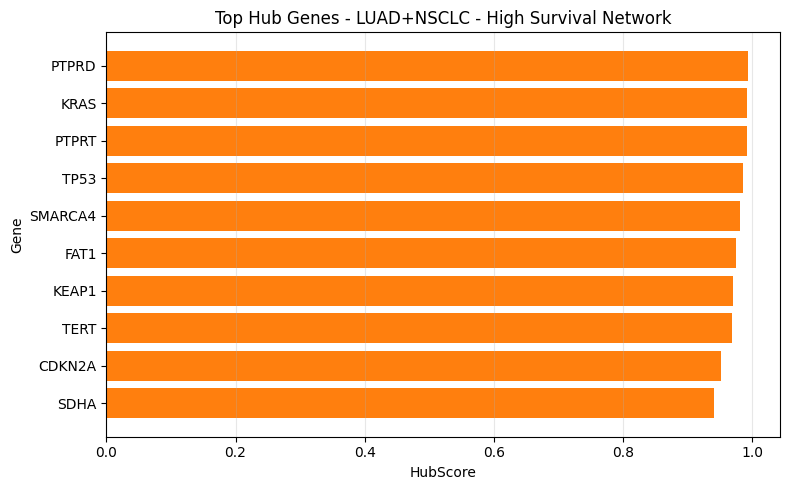

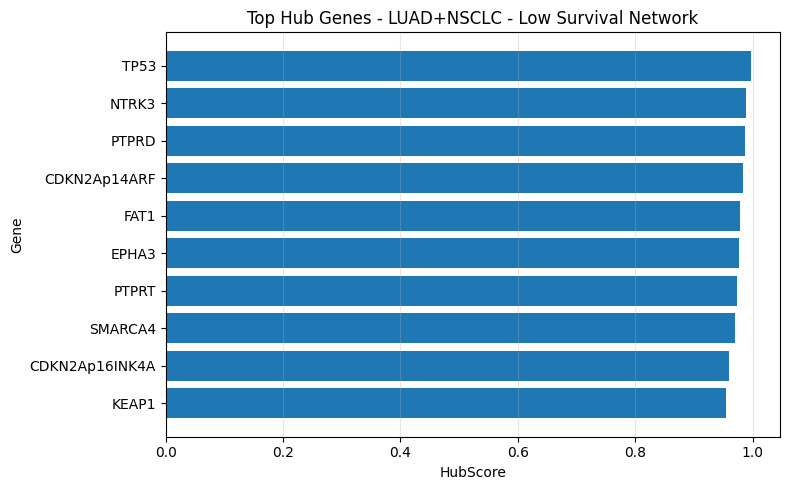

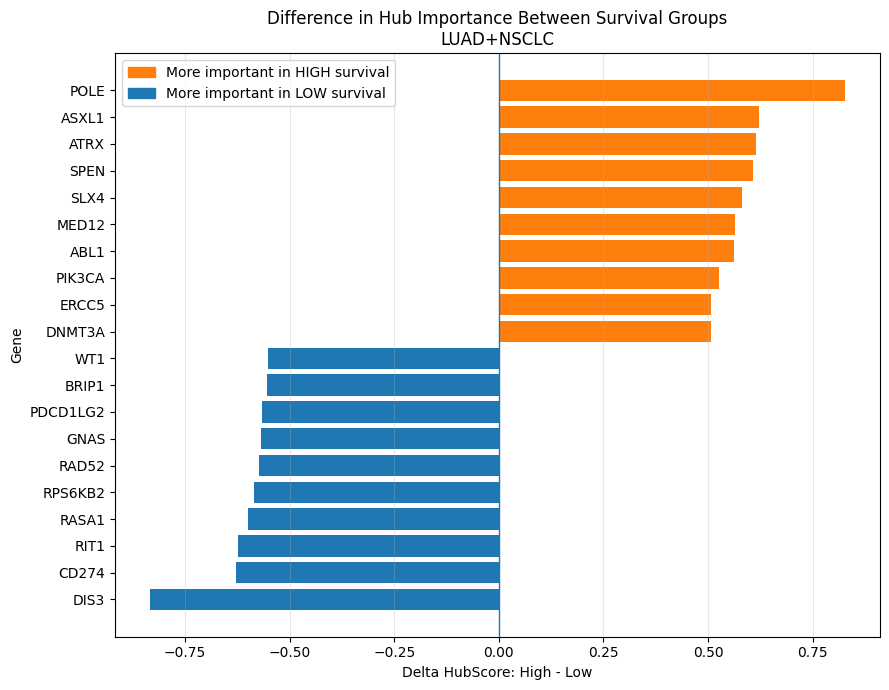


####################################################################################################
ONCOTREE GROUP: LUSC_NSCLC (LUSC+NSCLC)
####################################################################################################


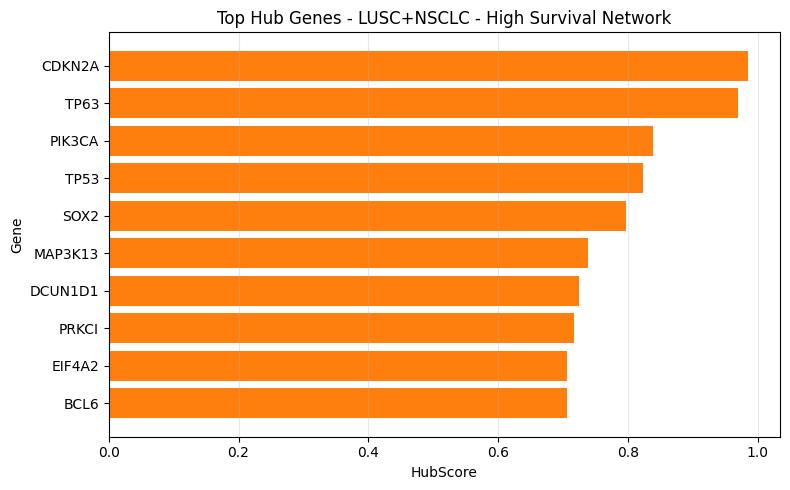

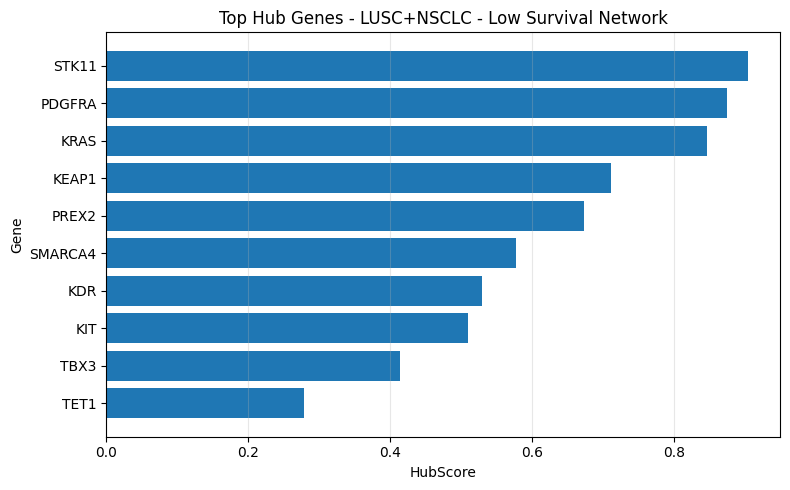

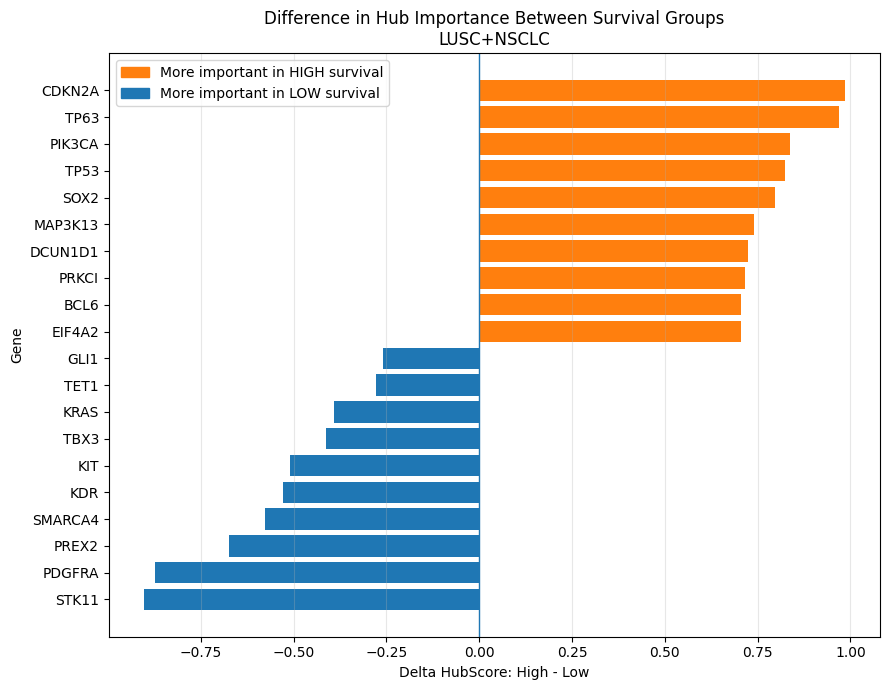

In [53]:
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import pandas as pd
import numpy as np

# ============================================================
# HUB PLOTS - ONCOTREE GROUPS ORIENTED
# High vs Low survival networks
# LUAD_NSCLC = LUAD + NSCLC
# LUSC_NSCLC = LUSC + NSCLC
# ============================================================

if "hub_tables_by_oncotree_survival" not in globals():
    raise ValueError(
        "hub_tables_by_oncotree_survival non disponibile. "
        "Esegui prima la cella hub analysis per Oncotree Group."
    )

if "hub_comparison_all_oncotree" not in globals():
    raise ValueError(
        "hub_comparison_all_oncotree non disponibile. "
        "Esegui prima la cella di confronto hub high vs low per Oncotree Group."
    )

top_n = 10

target_groups = ["LUAD_NSCLC", "LUSC_NSCLC"]

group_labels = {
    "LUAD_NSCLC": "LUAD+NSCLC",
    "LUSC_NSCLC": "LUSC+NSCLC",
}

# Colori survival groups
HIGH_COLOR = "tab:orange"   # High survival -> arancione
LOW_COLOR = "tab:blue"      # Low survival -> blu

# Metti una lista se vuoi plottare solo un gruppo, esempio:
# oncotree_groups_to_plot = ["LUAD_NSCLC"]
oncotree_groups_to_plot = [
    group_name
    for group_name in target_groups
    if group_name in hub_tables_by_oncotree_survival
]


# ============================================================
# LOOP PER ONCOTREE GROUP
# ============================================================

for oncotree_group in oncotree_groups_to_plot:

    readable_group = group_labels.get(oncotree_group, oncotree_group)

    print("\n" + "#" * 100)
    print(f"ONCOTREE GROUP: {oncotree_group} ({readable_group})")
    print("#" * 100)

    group_tables = hub_tables_by_oncotree_survival.get(oncotree_group, {})

    hub_high = group_tables.get("high", pd.DataFrame())
    hub_low = group_tables.get("low", pd.DataFrame())

    # ------------------------------------------------------------
    # Recupero confronto HIGH vs LOW
    # ------------------------------------------------------------

    if "Oncotree_Group" in hub_comparison_all_oncotree.columns:
        hub_comparison = hub_comparison_all_oncotree[
            hub_comparison_all_oncotree["Oncotree_Group"] == oncotree_group
            ].copy()

    elif "ONCOTREE_CODE" in hub_comparison_all_oncotree.columns:
        # fallback se hai mantenuto vecchio nome colonna
        hub_comparison = hub_comparison_all_oncotree[
            hub_comparison_all_oncotree["ONCOTREE_CODE"] == oncotree_group
            ].copy()

    else:
        raise ValueError(
            "hub_comparison_all_oncotree deve contenere 'Oncotree_Group' "
            "oppure 'ONCOTREE_CODE'."
        )

    # ========================================================
    # 1. Top hubs HIGH survival
    # ========================================================

    if hub_high is None or hub_high.empty:
        print(f"[{oncotree_group}] Nessuna hub table HIGH disponibile.")
    else:

        top_high = (
            hub_high
            .sort_values("HubScore", ascending=False)
            .head(top_n)
            .copy()
        )

        plt.figure(figsize=(8, 5))

        plt.barh(
            top_high["Gene"][::-1],
            top_high["HubScore"][::-1],
            color=HIGH_COLOR
        )

        plt.title(
            f"Top Hub Genes - {readable_group} - High Survival Network"
        )
        plt.xlabel("HubScore")
        plt.ylabel("Gene")
        plt.grid(axis="x", alpha=0.3)
        plt.tight_layout()
        plt.show()

    # ========================================================
    # 2. Top hubs LOW survival
    # ========================================================

    if hub_low is None or hub_low.empty:
        print(f"[{oncotree_group}] Nessuna hub table LOW disponibile.")
    else:

        top_low = (
            hub_low
            .sort_values("HubScore", ascending=False)
            .head(top_n)
            .copy()
        )

        plt.figure(figsize=(8, 5))

        plt.barh(
            top_low["Gene"][::-1],
            top_low["HubScore"][::-1],
            color=LOW_COLOR
        )

        plt.title(
            f"Top Hub Genes - {readable_group} - Low Survival Network"
        )
        plt.xlabel("HubScore")
        plt.ylabel("Gene")
        plt.grid(axis="x", alpha=0.3)
        plt.tight_layout()
        plt.show()

    # ========================================================
    # 3. Difference HIGH vs LOW
    # ========================================================

    if hub_comparison is None or hub_comparison.empty:
        print(f"[{oncotree_group}] Nessun confronto HIGH vs LOW disponibile.")
        continue

    if "Delta_HubScore_high_minus_low" not in hub_comparison.columns:
        print(
            f"[{oncotree_group}] Colonna Delta_HubScore_high_minus_low mancante. "
            "Controlla la cella precedente."
        )
        continue

    delta_high = (
        hub_comparison
        .sort_values("Delta_HubScore_high_minus_low", ascending=False)
        .head(top_n)
        .copy()
    )

    delta_low = (
        hub_comparison
        .sort_values("Delta_HubScore_high_minus_low", ascending=True)
        .head(top_n)
        .copy()
    )

    delta_plot = pd.concat(
        [delta_low, delta_high],
        axis=0
    ).drop_duplicates(
        subset=["Gene"]
    )

    delta_plot = delta_plot.sort_values(
        "Delta_HubScore_high_minus_low"
    )

    colors = [
        HIGH_COLOR if val > 0 else LOW_COLOR
        for val in delta_plot["Delta_HubScore_high_minus_low"]
    ]

    plt.figure(figsize=(9, 7))

    plt.barh(
        delta_plot["Gene"],
        delta_plot["Delta_HubScore_high_minus_low"],
        color=colors
    )

    plt.axvline(0, linewidth=1)

    plt.title(
        f"Difference in Hub Importance Between Survival Groups\n"
        f"{readable_group}"
    )

    plt.xlabel("Delta HubScore: High - Low")
    plt.ylabel("Gene")
    plt.grid(axis="x", alpha=0.3)

    orange_patch = mpatches.Patch(
        color=HIGH_COLOR,
        label="More important in HIGH survival"
    )

    blue_patch = mpatches.Patch(
        color=LOW_COLOR,
        label="More important in LOW survival"
    )

    plt.legend(handles=[orange_patch, blue_patch])

    plt.tight_layout()
    plt.show()

In [54]:
import pandas as pd
import numpy as np
from pathlib import Path

# ============================================================
# MAP SURVIVAL HUB GENES TO LEIDEN CLUSTERS
# LUAD_NSCLC
#
# Feature clinica di partenza: OS_MONTH
#
# Obiettivo:
# - prendere i geni hub più rappresentativi di HIGH survival vs LOW survival
# - vedere in quali cluster Leiden cadono
# - riassumere quali cluster sono più rappresentati
#
# Nota:
# - questa cella NON ricalcola high/low survival da OS_MONTH
# - usa i file/variabili prodotti dalla cella precedente di hub analysis survival
# ============================================================


# ============================================================
# 0. Paths and parameters
# ============================================================

data_dir = Path("data_lung")

oncotree_group = "LUAD_NSCLC"
included_codes = "LUAD+NSCLC"

HIGH_LABEL = "high"
LOW_LABEL = "low"

clusters_path = (
        data_dir
        / "networks_by_oncotree_groups"
        / "final_leiden_clusters_with_hub_metrics"
        / f"leiden_clusters_with_hub_metrics_{oncotree_group}.csv"
)

survival_base_dir = (
        data_dir
        / "clinical_to_network_by_oncotree_groups"
)

hub_analysis_dir = (
        survival_base_dir
        / "hub_analysis_by_oncotree_group_survival"
)

output_dir = (
        survival_base_dir
        / "hub_genes_cluster_mapping_survival"
)

output_dir.mkdir(parents=True, exist_ok=True)

# Numero di geni da prendere per ciascun gruppo
top_n = 20

# Se vuoi usare più geni:
# top_n = 30
# top_n = 50


# ============================================================
# 1. Helper functions
# ============================================================

def safe_display(df_obj):
    try:
        display(df_obj)
    except NameError:
        print(df_obj)


def clean_gene_name(x):
    if pd.isna(x):
        return np.nan
    return str(x).strip().upper()


def find_existing_file(candidate_paths, search_dir=None, patterns=None, description="file"):
    """
    Cerca un file in questo ordine:
    1. path candidati espliciti;
    2. ricerca automatica con glob nella cartella indicata.

    Serve per evitare errori quando il nome del CSV salvato cambia leggermente.
    """

    print(f"\nSearching for {description}...")

    for path in candidate_paths:
        print("Candidate:", path)
        if path.exists():
            print("Found:", path)
            return path

    if search_dir is not None and search_dir.exists() and patterns is not None:
        print(f"\nTrying automatic search in: {search_dir}")

        matches = []

        for pattern in patterns:
            found = sorted(search_dir.glob(pattern))
            matches.extend(found)

        unique_matches = []
        seen = set()

        for path in matches:
            if path not in seen:
                unique_matches.append(path)
                seen.add(path)

        if len(unique_matches) > 0:
            print("Found by automatic search:")
            for path in unique_matches:
                print(path)

            return unique_matches[0]

    print(f"\nNo {description} found.")
    return None


def load_hub_comparison():
    """
    Carica la tabella di confronto HIGH survival vs LOW survival.
    Prima prova a usare la variabile già in memoria.
    Se non esiste, cerca il CSV salvato dalla cella precedente.
    """

    possible_memory_vars = [
        "hub_comparison_all_oncotree_survival",
        "hub_comparison_all_oncotree_groups",
        "hub_comparison_all_oncotree"
    ]

    for var_name in possible_memory_vars:
        if var_name in globals():
            print(f"Uso {var_name} già presente in memoria.")
            return globals()[var_name].copy()

    candidate_paths = [
        hub_analysis_dir
        / "hub_genes_high_vs_low_comparison_all_oncotree_groups.csv",

        hub_analysis_dir
        / "hub_genes_high_vs_low_comparison_all_oncotree_group.csv",

        hub_analysis_dir
        / "hub_genes_survival_comparison_all_oncotree_groups.csv",
    ]

    patterns = [
        "*high*low*comparison*all*oncotree*.csv",
        "*survival*comparison*all*oncotree*.csv",
        "*hub*survival*comparison*.csv",
        "*comparison*survival*.csv",
    ]

    found_path = find_existing_file(
        candidate_paths=candidate_paths,
        search_dir=hub_analysis_dir,
        patterns=patterns,
        description="hub comparison HIGH survival vs LOW survival"
    )

    if found_path is not None:
        print("\nCarico hub comparison da CSV:")
        print(found_path)
        return pd.read_csv(found_path, low_memory=False)

    raise FileNotFoundError(
        "Non trovo la tabella di confronto HIGH vs LOW survival.\n"
        "Controlla che sia stata eseguita prima la cella di hub comparison survival.\n"
        f"Cartella cercata:\n{hub_analysis_dir}"
    )


def load_hub_all():
    """
    Carica la tabella con gli hub separati HIGH survival e LOW survival.
    Prima prova a usare la variabile già in memoria.
    Se non esiste, cerca il CSV salvato.
    """

    possible_memory_vars = [
        "hub_all_oncotree_survival",
        "hub_all_oncotree",
    ]

    for var_name in possible_memory_vars:
        if var_name in globals():
            print(f"Uso {var_name} già presente in memoria.")
            return globals()[var_name].copy()

    candidate_paths = [
        hub_analysis_dir
        / "hub_genes_all_oncotree_group_survival_networks.csv",

        hub_analysis_dir
        / "hub_genes_all_oncotree_survival_networks.csv",

        hub_analysis_dir
        / "hub_genes_all_survival_networks.csv",
    ]

    patterns = [
        "*hub_genes_all*survival*network*.csv",
        "*all_oncotree*survival*.csv",
        "*hub*all*survival*.csv",
    ]

    found_path = find_existing_file(
        candidate_paths=candidate_paths,
        search_dir=hub_analysis_dir,
        patterns=patterns,
        description="separate hub table HIGH survival / LOW survival"
    )

    if found_path is not None:
        print("\nCarico hub all da CSV:")
        print(found_path)
        return pd.read_csv(found_path, low_memory=False)

    print(
        "\nTabella hub separata non trovata. "
        "Salto l'analisi alternativa sui top hub separati."
    )
    return None


def map_genes_to_clusters(gene_table, cluster_table):
    """
    Associa ogni gene alla sua informazione di cluster Leiden.
    """

    gene_table = gene_table.copy()
    cluster_table = cluster_table.copy()

    gene_table["Gene_clean"] = gene_table["Gene"].apply(clean_gene_name)
    cluster_table["Gene_clean"] = cluster_table["Gene"].apply(clean_gene_name)

    cluster_cols = [
        "Gene_clean",
        "Cluster",
        "Rank_in_cluster",
        "HubScore",
        "Degree",
        "Node Strength",
        "Node_Strength",
        "Betweenness",
        "Closeness"
    ]

    cluster_cols = [
        col for col in cluster_cols
        if col in cluster_table.columns
    ]

    cluster_gene_map = (
        cluster_table[cluster_cols]
        .drop_duplicates("Gene_clean")
        .copy()
    )

    mapped = gene_table.merge(
        cluster_gene_map,
        on="Gene_clean",
        how="left",
        suffixes=("", "_cluster")
    )

    mapped["Found_in_Leiden_clusters"] = mapped["Cluster"].notna()

    return mapped


def summarize_cluster_distribution(mapped_df, group_col):
    """
    Riassume quanti geni di ciascun gruppo cadono in ciascun cluster.
    """

    if mapped_df.empty:
        return pd.DataFrame()

    mapped_valid = mapped_df.dropna(subset=["Cluster"]).copy()

    if mapped_valid.empty:
        return pd.DataFrame()

    agg_dict = {
        "n_genes": ("Gene", "nunique"),
        "genes": ("Gene", lambda x: ", ".join(sorted(x.dropna().astype(str).unique()))),
        "mean_cluster_rank": ("Rank_in_cluster", "mean")
    }

    if "Abs_Delta_HubScore" in mapped_valid.columns:
        agg_dict["mean_abs_delta"] = ("Abs_Delta_HubScore", "mean")

    summary = (
        mapped_valid
        .groupby([group_col, "Cluster"])
        .agg(**agg_dict)
        .reset_index()
    )

    totals = (
        mapped_valid
        .groupby(group_col)
        .agg(total_mapped_genes=("Gene", "nunique"))
        .reset_index()
    )

    summary = summary.merge(
        totals,
        on=group_col,
        how="left"
    )

    summary["percentage"] = (
            summary["n_genes"]
            / summary["total_mapped_genes"]
            * 100
    ).round(2)

    summary = summary.sort_values(
        [group_col, "n_genes", "percentage"],
        ascending=[True, False, False]
    ).reset_index(drop=True)

    return summary


# ============================================================
# 2. Load Leiden cluster table
# ============================================================

if not clusters_path.exists():
    raise FileNotFoundError(
        "Non trovo il file dei cluster Leiden:\n"
        f"{clusters_path}"
    )

clusters = pd.read_csv(clusters_path, low_memory=False)
clusters = clusters.loc[:, ~clusters.columns.duplicated()].copy()

# Normalize column names from the final Leiden cluster file
clusters = clusters.rename(columns={
    "Hugo_Symbol": "Gene",
    "gene": "Gene",
    "GENE": "Gene",
    "cluster": "Cluster",
    "Leiden_cluster": "Cluster",
    "Leiden_Cluster": "Cluster",
    "leiden_cluster": "Cluster",
    "hubscore": "HubScore",
    "rank_in_cluster": "Rank_in_cluster",
    "Oncotree_Code": "Oncotree_Group",
    "ONCOTREE_CODE": "Oncotree_Group",
    "Oncotree Code": "Oncotree_Group"
})
clusters = clusters.loc[:, ~clusters.columns.duplicated()].copy()

required_cluster_cols = {
    "Gene",
    "Cluster"
}

missing_cluster_cols = required_cluster_cols - set(clusters.columns)

if missing_cluster_cols:
    raise ValueError(
        f"Colonne mancanti nel file Leiden clusters: {missing_cluster_cols}"
    )

clusters["Gene"] = clusters["Gene"].astype(str)
clusters["Gene_clean"] = clusters["Gene"].apply(clean_gene_name)

print("Loaded Leiden clusters:")
print(clusters_path)
print("Rows:", clusters.shape[0])
print("Genes:", clusters["Gene_clean"].nunique())
print("Clusters:", sorted(clusters["Cluster"].dropna().unique()))

print("\nCluster size summary:")

cluster_size_summary = (
    clusters
    .groupby("Cluster")
    .agg(
        n_genes=("Gene", "nunique"),
        top_cluster_genes=(
            "Gene",
            lambda x: ", ".join(x.dropna().astype(str).head(10))
        )
    )
    .reset_index()
    .sort_values("n_genes", ascending=False)
)

safe_display(cluster_size_summary)


# ============================================================
# 3. ANALISI PRINCIPALE:
#    uso i geni differenziali HIGH survival vs LOW survival
# ============================================================

hub_comparison = load_hub_comparison()
hub_comparison = hub_comparison.loc[:, ~hub_comparison.columns.duplicated()].copy()

# Normalizzo eventuale nome gruppo
if "Oncotree_Group" not in hub_comparison.columns:
    if "ONCOTREE_CODE" in hub_comparison.columns:
        hub_comparison = hub_comparison.rename(
            columns={"ONCOTREE_CODE": "Oncotree_Group"}
        )
    else:
        raise ValueError(
            "La tabella hub_comparison deve contenere Oncotree_Group oppure ONCOTREE_CODE."
        )

delta_col = "Delta_HubScore_high_minus_low"

required_comparison_cols = {
    "Oncotree_Group",
    "Gene",
    delta_col
}

missing_comparison_cols = required_comparison_cols - set(hub_comparison.columns)

if missing_comparison_cols:
    print("\nColonne disponibili nella tabella hub_comparison:")
    print(hub_comparison.columns.tolist())

    raise ValueError(
        f"Colonne mancanti nella tabella di confronto hub survival: {missing_comparison_cols}"
    )

hub_comparison = hub_comparison[
    hub_comparison["Oncotree_Group"].astype(str) == oncotree_group
    ].copy()

hub_comparison["Gene"] = hub_comparison["Gene"].astype(str)

hub_comparison[delta_col] = pd.to_numeric(
    hub_comparison[delta_col],
    errors="coerce"
)

hub_comparison = hub_comparison.dropna(
    subset=["Gene", delta_col]
).copy()

# Geni più rappresentativi della rete HIGH survival
high_genes = (
    hub_comparison
    .sort_values(delta_col, ascending=False)
    .head(top_n)
    .copy()
)

high_genes["Signature_Group"] = "High-survival enriched hub genes"

# Geni più rappresentativi della rete LOW survival
low_genes = (
    hub_comparison
    .sort_values(delta_col, ascending=True)
    .head(top_n)
    .copy()
)

low_genes["Signature_Group"] = "Low-survival enriched hub genes"

differential_genes = pd.concat(
    [high_genes, low_genes],
    ignore_index=True
)

differential_genes["Abs_Delta_HubScore"] = (
    differential_genes[delta_col]
    .abs()
)

differential_mapped = map_genes_to_clusters(
    gene_table=differential_genes,
    cluster_table=clusters
)

print("\n" + "=" * 100)
print("DIFFERENTIAL SURVIVAL HUB GENES MAPPED TO LEIDEN CLUSTERS")
print("=" * 100)

cols_to_show = [
    "Signature_Group",
    "Gene",
    delta_col,
    "Abs_Delta_HubScore",
    "HubScore_high",
    "HubScore_low",
    "Degree_high",
    "Degree_low",
    "Node_Strength_high",
    "Node_Strength_low",
    "Cluster",
    "Rank_in_cluster",
    "HubScore_cluster",
    "Degree",
    "Node Strength",
    "Node_Strength",
    "Found_in_Leiden_clusters"
]

cols_to_show = [
    col for col in cols_to_show
    if col in differential_mapped.columns
]

safe_display(
    differential_mapped[cols_to_show]
    .sort_values(
        ["Signature_Group", "Abs_Delta_HubScore"],
        ascending=[True, False]
    )
)

differential_cluster_summary = summarize_cluster_distribution(
    mapped_df=differential_mapped,
    group_col="Signature_Group"
)

print("\n" + "=" * 100)
print("CLUSTER DISTRIBUTION OF DIFFERENTIAL SURVIVAL HUB GENES")
print("=" * 100)

safe_display(differential_cluster_summary)


# ============================================================
# 4. Dominant cluster per gruppo differenziale
# ============================================================

if not differential_cluster_summary.empty:
    dominant_clusters = (
        differential_cluster_summary
        .sort_values(
            ["Signature_Group", "n_genes", "percentage"],
            ascending=[True, False, False]
        )
        .groupby("Signature_Group")
        .head(1)
        .reset_index(drop=True)
    )
else:
    dominant_clusters = pd.DataFrame()

print("\n" + "=" * 100)
print("DOMINANT LEIDEN CLUSTER FOR EACH DIFFERENTIAL SURVIVAL HUB SIGNATURE")
print("=" * 100)

safe_display(dominant_clusters)


# ============================================================
# 5. ANALISI ALTERNATIVA:
#    uso le top hub list separate HIGH survival e LOW survival
# ============================================================

hub_all = load_hub_all()

if hub_all is not None:

    hub_all = hub_all.loc[:, ~hub_all.columns.duplicated()].copy()

    # Normalizzo eventuale nome gruppo
    if "Oncotree_Group" not in hub_all.columns:
        if "ONCOTREE_CODE" in hub_all.columns:
            hub_all = hub_all.rename(columns={"ONCOTREE_CODE": "Oncotree_Group"})

    # Normalizzo survival_group
    if "survival_group" not in hub_all.columns:
        if "SURVIVAL_GROUP" in hub_all.columns:
            hub_all = hub_all.rename(columns={"SURVIVAL_GROUP": "survival_group"})
        elif "Survival_Group" in hub_all.columns:
            hub_all = hub_all.rename(columns={"Survival_Group": "survival_group"})

    required_hub_all_cols = {
        "Oncotree_Group",
        "survival_group",
        "Gene",
        "HubScore"
    }

    missing_hub_all_cols = required_hub_all_cols - set(hub_all.columns)

    if missing_hub_all_cols:
        print(
            "\nColonne mancanti nella tabella hub separata. "
            f"Salto analisi alternativa. Mancano: {missing_hub_all_cols}"
        )
        print("\nColonne disponibili:")
        print(hub_all.columns.tolist())

        separate_mapped = pd.DataFrame()
        separate_cluster_summary = pd.DataFrame()

    else:
        hub_all = hub_all[
            hub_all["Oncotree_Group"].astype(str) == oncotree_group
            ].copy()

        hub_all["Gene"] = hub_all["Gene"].astype(str)
        hub_all["HubScore"] = pd.to_numeric(
            hub_all["HubScore"],
            errors="coerce"
        )

        hub_all["survival_group_clean"] = (
            hub_all["survival_group"]
            .astype(str)
            .str.strip()
            .str.lower()
        )

        high_top_hubs = (
            hub_all[
                hub_all["survival_group_clean"] == HIGH_LABEL
                ]
            .sort_values("HubScore", ascending=False)
            .head(top_n)
            .copy()
        )

        high_top_hubs["Hub_List_Group"] = "Top High-survival hub genes"

        low_top_hubs = (
            hub_all[
                hub_all["survival_group_clean"] == LOW_LABEL
                ]
            .sort_values("HubScore", ascending=False)
            .head(top_n)
            .copy()
        )

        low_top_hubs["Hub_List_Group"] = "Top Low-survival hub genes"

        separate_top_hubs = pd.concat(
            [high_top_hubs, low_top_hubs],
            ignore_index=True
        )

        separate_mapped = map_genes_to_clusters(
            gene_table=separate_top_hubs,
            cluster_table=clusters
        )

        print("\n" + "=" * 100)
        print("SEPARATE SURVIVAL TOP HUB LISTS MAPPED TO LEIDEN CLUSTERS")
        print("=" * 100)

        cols_to_show_sep = [
            "Hub_List_Group",
            "survival_group",
            "Gene",
            "HubScore",
            "Degree",
            "Node_Strength",
            "Betweenness",
            "Closeness",
            "Cluster",
            "Rank_in_cluster",
            "HubScore_cluster",
            "Found_in_Leiden_clusters"
        ]

        cols_to_show_sep = [
            col for col in cols_to_show_sep
            if col in separate_mapped.columns
        ]

        safe_display(
            separate_mapped[cols_to_show_sep]
            .sort_values(["Hub_List_Group", "HubScore"], ascending=[True, False])
        )

        separate_cluster_summary = (
            separate_mapped
            .dropna(subset=["Cluster"])
            .groupby(["Hub_List_Group", "Cluster"])
            .agg(
                n_genes=("Gene", "nunique"),
                genes=("Gene", lambda x: ", ".join(sorted(x.dropna().astype(str).unique()))),
                mean_hubscore=("HubScore", "mean"),
                mean_cluster_rank=("Rank_in_cluster", "mean")
            )
            .reset_index()
        )

        separate_totals = (
            separate_mapped
            .dropna(subset=["Cluster"])
            .groupby("Hub_List_Group")
            .agg(total_mapped_genes=("Gene", "nunique"))
            .reset_index()
        )

        separate_cluster_summary = separate_cluster_summary.merge(
            separate_totals,
            on="Hub_List_Group",
            how="left"
        )

        separate_cluster_summary["percentage"] = (
                separate_cluster_summary["n_genes"]
                / separate_cluster_summary["total_mapped_genes"]
                * 100
        ).round(2)

        separate_cluster_summary = separate_cluster_summary.sort_values(
            ["Hub_List_Group", "n_genes", "percentage"],
            ascending=[True, False, False]
        ).reset_index(drop=True)

        print("\n" + "=" * 100)
        print("CLUSTER DISTRIBUTION OF SEPARATE SURVIVAL TOP HUB LISTS")
        print("=" * 100)

        safe_display(separate_cluster_summary)

else:
    separate_mapped = pd.DataFrame()
    separate_cluster_summary = pd.DataFrame()


# ============================================================
# 6. Save outputs
# ============================================================

differential_mapped_file = (
        output_dir
        / f"{oncotree_group}_differential_high_vs_low_survival_hub_genes_mapped_to_leiden_clusters.csv"
)

differential_summary_file = (
        output_dir
        / f"{oncotree_group}_differential_high_vs_low_survival_cluster_distribution.csv"
)

dominant_clusters_file = (
        output_dir
        / f"{oncotree_group}_dominant_clusters_for_differential_survival_hub_signatures.csv"
)

differential_mapped.to_csv(
    differential_mapped_file,
    index=False
)

differential_cluster_summary.to_csv(
    differential_summary_file,
    index=False
)

dominant_clusters.to_csv(
    dominant_clusters_file,
    index=False
)

print("\nSaved differential mapped table:")
print(differential_mapped_file)

print("\nSaved differential cluster summary:")
print(differential_summary_file)

print("\nSaved dominant clusters table:")
print(dominant_clusters_file)

if not separate_mapped.empty:

    separate_mapped_file = (
            output_dir
            / f"{oncotree_group}_separate_high_low_survival_top_hub_genes_mapped_to_leiden_clusters.csv"
    )

    separate_summary_file = (
            output_dir
            / f"{oncotree_group}_separate_high_low_survival_top_hub_cluster_distribution.csv"
    )

    separate_mapped.to_csv(
        separate_mapped_file,
        index=False
    )

    separate_cluster_summary.to_csv(
        separate_summary_file,
        index=False
    )

    print("\nSaved separate top hub mapped table:")
    print(separate_mapped_file)

    print("\nSaved separate top hub cluster summary:")
    print(separate_summary_file)


# ============================================================
# 7. Final interpretation helper
# ============================================================

print("\n" + "=" * 100)
print("INTERPRETATION GUIDE")
print("=" * 100)

print(
    "1. Usa soprattutto la tabella 'differential_cluster_summary' per il report.\n"
    "   Questa indica in quali cluster cadono maggiormente i geni più specifici\n"
    "   della rete HIGH survival oppure LOW survival.\n"
)

print(
    f"2. {delta_col} > 0 significa che il gene è più hub\n"
    f"   nella rete HIGH survival rispetto alla rete LOW survival.\n"
)

print(
    f"3. {delta_col} < 0 significa che il gene è più hub\n"
    f"   nella rete LOW survival rispetto alla rete HIGH survival.\n"
)

print(
    "4. La tabella 'dominant_clusters' ti dà direttamente il cluster principale\n"
    "   per ciascuna signature differenziale survival.\n"
)

print(
    "5. L'analisi alternativa con le top hub list separate è utile come controllo,\n"
    "   ma è meno specifica perché un gene può essere molto hub in entrambi i gruppi.\n"
)

print(
    "6. Se nella cella precedente HIGH/LOW è stato definito usando OS_MONTH,\n"
    "   allora questa cella rappresenta il mapping cluster dei geni hub legati alla survival.\n"
)

Loaded Leiden clusters:
data_lung\networks_by_oncotree_groups\final_leiden_clusters_with_hub_metrics\leiden_clusters_with_hub_metrics_LUAD_NSCLC.csv
Rows: 359
Genes: 359
Clusters: [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10]

Cluster size summary:


,Cluster,n_genes,top_cluster_genes
0,0,93,"PTPRT, PTPRD, NTRK3, EPHA3, ERBB4, GRIN2A, EPHA7, KDR, EPHB1, EPHA5"
1,1,49,"SMARCA4, KEAP1, PIK3C2G, STK11, KRAS, ATRX, ETV6, MYOD1, ERCC4, ERCC5"
2,2,48,"FAT1, NF1, HGF, MGA, PIK3CG, ATM, RBM10, ARID1A, PGR, WT1"
3,3,44,"SDHA, TERT, KMT2B, CARD11, DROSHA, IL7R, EP300, RET, IKZF1, RICTOR"
4,4,39,"CDKN2A, CDKN2Ap16INK4A, CDKN2Ap14ARF, CDKN2B, TEK, JAK2, MAP2K4, H3F3C, RTEL1, CCND3"
5,5,23,"PREX2, FGFR1, RECQL4, MYC, SOX17, AGO2, NBN, RAD21, PIK3CA, PRDM14"
6,6,23,"FGF3, NFKBIA, FOXA1, NKX2-1, CCND1, FGF4, FGF19, PRKD1, INPPL1, WHSC1"
7,7,15,"NTRK1, DDR2, MCL1, RB1, RIT1, SDHC, SETDB1, HIST2H3C, HIST2H3D, H3C13"
8,8,15,"TP53, BRD4, CTCF, FGFR3, GAB1, MITF, SPOP, HLA-B, CENPA, SESN2"
9,9,7,"ALK, CREBBP, TSC2, SLX4, EML4, PPP2R1A, TRAF7"


Uso hub_comparison_all_oncotree_groups già presente in memoria.

DIFFERENTIAL SURVIVAL HUB GENES MAPPED TO LEIDEN CLUSTERS


,Signature_Group,Gene,Delta_HubScore_high_minus_low,Abs_Delta_HubScore,HubScore_high,HubScore_low,Degree_high,Degree_low,Node_Strength_high,Node_Strength_low,Cluster,Rank_in_cluster,Degree,Node Strength,Found_in_Leiden_clusters
0,High-survival enriched hub genes,POLE,0.827731,0.827731,0.827731,NaN,18.0,NaN,46.091337,NaN,0,21,37,79.137422,True
1,High-survival enriched hub genes,ASXL1,0.621324,0.621324,0.621324,NaN,6.0,NaN,16.903063,NaN,3,11,21,43.567051,True
2,High-survival enriched hub genes,ATRX,0.615021,0.615021,0.747899,0.132878,8.0,1.0,19.115936,2.209129,1,6,18,35.724411,True
3,High-survival enriched hub genes,SPEN,0.606618,0.606618,0.767857,0.161239,11.0,1.0,26.484576,3.002899,0,49,21,45.940840,True
4,High-survival enriched hub genes,SLX4,0.581408,0.581408,0.581408,NaN,6.0,NaN,14.931129,NaN,9,4,7,16.256199,True
5,High-survival enriched hub genes,MED12,0.564601,0.564601,0.778887,0.214286,13.0,1.0,31.688322,1.957314,0,67,11,19.653812,True
6,High-survival enriched hub genes,ABL1,0.561975,0.561975,0.561975,NaN,5.0,NaN,17.529142,NaN,2,26,7,19.587049,True
7,High-survival enriched hub genes,PIK3CA,0.526786,0.526786,0.647584,0.120798,9.0,1.0,17.173542,1.560879,5,9,21,34.052814,True
8,High-survival enriched hub genes,ERCC5,0.507353,0.507353,0.507353,NaN,4.0,NaN,12.034970,NaN,1,10,9,15.248551,True
9,High-survival enriched hub genes,DNMT3A,0.506828,0.506828,0.682248,0.175420,7.0,1.0,18.394141,2.351349,0,53,15,36.160781,True



CLUSTER DISTRIBUTION OF DIFFERENTIAL SURVIVAL HUB GENES


,Signature_Group,Cluster,n_genes,genes,mean_cluster_rank,mean_abs_delta,total_mapped_genes,percentage
0,High-survival enriched hub genes,0,9,"CSDE1, CSF3R, DNMT3A, HIST1H3B, MED12, NOTCH4, POLE, SPEN, TGFBR1",54.777778,0.516165,20,45.0
1,High-survival enriched hub genes,1,3,"ATRX, ERCC5, MRE11A",9.666667,0.539041,20,15.0
2,High-survival enriched hub genes,5,3,"GATA3, PIK3CA, PRDM14",11.333333,0.464636,20,15.0
3,High-survival enriched hub genes,4,2,"AXIN2, MAP2K4",15.000000,0.452731,20,10.0
4,High-survival enriched hub genes,2,1,ABL1,26.000000,0.561975,20,5.0
5,High-survival enriched hub genes,3,1,ASXL1,11.000000,0.621324,20,5.0
6,High-survival enriched hub genes,9,1,SLX4,4.000000,0.581408,20,5.0
7,Low-survival enriched hub genes,4,5,"CCND3, CD274, GNAS, PDCD1LG2, RTEL1",11.800000,0.525525,20,25.0
8,Low-survival enriched hub genes,7,4,"H3C13, H3C14, RIT1, SETDB1",8.250000,0.492778,20,20.0
9,Low-survival enriched hub genes,0,3,"BRIP1, DIS3, RASA1",50.666667,0.662465,20,15.0


... (3 outputs left out)

,Hub_List_Group,survival_group,Gene,HubScore,Degree,Node_Strength,Betweenness,Closeness,Cluster,Rank_in_cluster,HubScore_cluster,Found_in_Leiden_clusters
0,Top High-survival hub genes,high,PTPRD,0.993697,65,142.432415,0.155081,0.523179,0,2,0.996518,True
1,Top High-survival hub genes,high,KRAS,0.992647,67,119.656534,0.297004,0.482688,1,5,0.876741,True
2,Top High-survival hub genes,high,PTPRT,0.991597,74,181.550339,0.050454,0.502119,0,1,0.999304,True
3,Top High-survival hub genes,high,TP53,0.986345,56,119.677403,0.207860,0.471173,8,1,0.976323,True
4,Top High-survival hub genes,high,SMARCA4,0.981092,47,103.243381,0.090539,0.490683,1,1,0.988858,True
5,Top High-survival hub genes,high,FAT1,0.975840,48,110.975827,0.040478,0.475904,2,1,0.990599,True
6,Top High-survival hub genes,high,KEAP1,0.970588,37,77.539091,0.063684,0.473054,1,2,0.972841,True
7,Top High-survival hub genes,high,TERT,0.969538,40,91.897801,0.097583,0.458414,3,2,0.946727,True
8,Top High-survival hub genes,high,CDKN2A,0.951681,42,109.240097,0.162912,0.433272,4,1,0.933148,True
9,Top High-survival hub genes,high,SDHA,0.941176,29,68.970132,0.039405,0.448015,3,1,0.955780,True



CLUSTER DISTRIBUTION OF SEPARATE SURVIVAL TOP HUB LISTS


,Hub_List_Group,Cluster,n_genes,genes,mean_hubscore,mean_cluster_rank,total_mapped_genes,percentage
0,Top High-survival hub genes,0,5,"EPHA3, ERBB4, GRIN2A, PTPRD, PTPRT",0.945588,3.600000,20,25.0
1,Top High-survival hub genes,1,5,"KEAP1, KRAS, PIK3C2G, SMARCA4, STK11",0.953361,3.000000,20,25.0
2,Top High-survival hub genes,2,4,"FAT1, HGF, NF1, PIK3CG",0.932248,2.750000,20,20.0
3,Top High-survival hub genes,3,4,"CARD11, KMT2B, SDHA, TERT",0.936187,2.500000,20,20.0
4,Top High-survival hub genes,4,1,CDKN2A,0.951681,1.000000,20,5.0
5,Top High-survival hub genes,8,1,TP53,0.986345,1.000000,20,5.0
6,Top Low-survival hub genes,0,6,"EPHA3, EPHA5, EPHA7, NTRK3, PTPRD, PTPRT",0.961222,4.500000,20,30.0
7,Top Low-survival hub genes,4,4,"CDKN2A, CDKN2Ap14ARF, CDKN2Ap16INK4A, CDKN2B",0.957458,2.500000,20,20.0
8,Top Low-survival hub genes,1,3,"KEAP1, SMARCA4, STK11",0.934874,2.333333,20,15.0
9,Top Low-survival hub genes,2,2,"FAT1, NF1",0.958246,1.500000,20,10.0



Saved differential mapped table:
data_lung\clinical_to_network_by_oncotree_groups\hub_genes_cluster_mapping_survival\LUAD_NSCLC_differential_high_vs_low_survival_hub_genes_mapped_to_leiden_clusters.csv

Saved differential cluster summary:
data_lung\clinical_to_network_by_oncotree_groups\hub_genes_cluster_mapping_survival\LUAD_NSCLC_differential_high_vs_low_survival_cluster_distribution.csv

Saved dominant clusters table:
data_lung\clinical_to_network_by_oncotree_groups\hub_genes_cluster_mapping_survival\LUAD_NSCLC_dominant_clusters_for_differential_survival_hub_signatures.csv

Saved separate top hub mapped table:
data_lung\clinical_to_network_by_oncotree_groups\hub_genes_cluster_mapping_survival\LUAD_NSCLC_separate_high_low_survival_top_hub_genes_mapped_to_leiden_clusters.csv

Saved separate top hub cluster summary:
data_lung\clinical_to_network_by_oncotree_groups\hub_genes_cluster_mapping_survival\LUAD_NSCLC_separate_high_low_survival_top_hub_cluster_distribution.csv

INTERPRETATION 

Loaded clusters file:
data_lung\networks_by_oncotree_groups\final_leiden_clusters_with_hub_metrics\leiden_clusters_with_hub_metrics_LUAD_NSCLC.csv

Loaded mapped hub file:
data_lung\clinical_to_network_by_oncotree_groups\hub_genes_cluster_mapping_survival\LUAD_NSCLC_differential_high_vs_low_survival_hub_genes_mapped_to_leiden_clusters.csv

HUB COUNTS BY CLUSTER - DIFFERENTIAL SURVIVAL HUB LIST


,Cluster,cluster_size_genes,High_n_hubs,High_pct_of_group_hubs,Low_n_hubs,Low_pct_of_group_hubs,Delta_n_hubs_High_minus_Low,Delta_pct_group_High_minus_Low,High_genes,Low_genes
0,0,93,9,45.0,3,15.0,6,30.0,"CSDE1, CSF3R, DNMT3A, HIST1H3B, MED12, NOTCH4, POLE, SPEN, TGFBR1","BRIP1, DIS3, RASA1"
1,1,49,3,15.0,3,15.0,0,0.0,"ATRX, ERCC5, MRE11A","CHEK2, RAD52, TGFBR2"
2,2,48,1,5.0,1,5.0,0,0.0,ABL1,WT1
3,3,44,1,5.0,0,0.0,1,5.0,ASXL1,-
4,4,39,2,10.0,5,25.0,-3,-15.0,"AXIN2, MAP2K4","CCND3, CD274, GNAS, PDCD1LG2, RTEL1"
5,5,23,3,15.0,0,0.0,3,15.0,"GATA3, PIK3CA, PRDM14",-
6,6,23,0,0.0,3,15.0,-3,-15.0,-,"MAPK1, RPS6KB2, WHSC1"
7,7,15,0,0.0,4,20.0,-4,-20.0,-,"H3C13, H3C14, RIT1, SETDB1"
8,8,15,0,0.0,0,0.0,0,0.0,-,-
9,9,7,1,5.0,1,5.0,0,0.0,SLX4,TSC2



FOCUS ON PROGNOSTIC CLUSTERS 1 AND 3


,Cluster,cluster_size_genes,High_n_hubs,High_pct_of_group_hubs,Low_n_hubs,Low_pct_of_group_hubs,Delta_n_hubs_High_minus_Low,Delta_pct_group_High_minus_Low,High_genes,Low_genes
1,1,49,3,15.0,3,15.0,0,0.0,"ATRX, ERCC5, MRE11A","CHEK2, RAD52, TGFBR2"
3,3,44,1,5.0,0,0.0,1,5.0,ASXL1,-


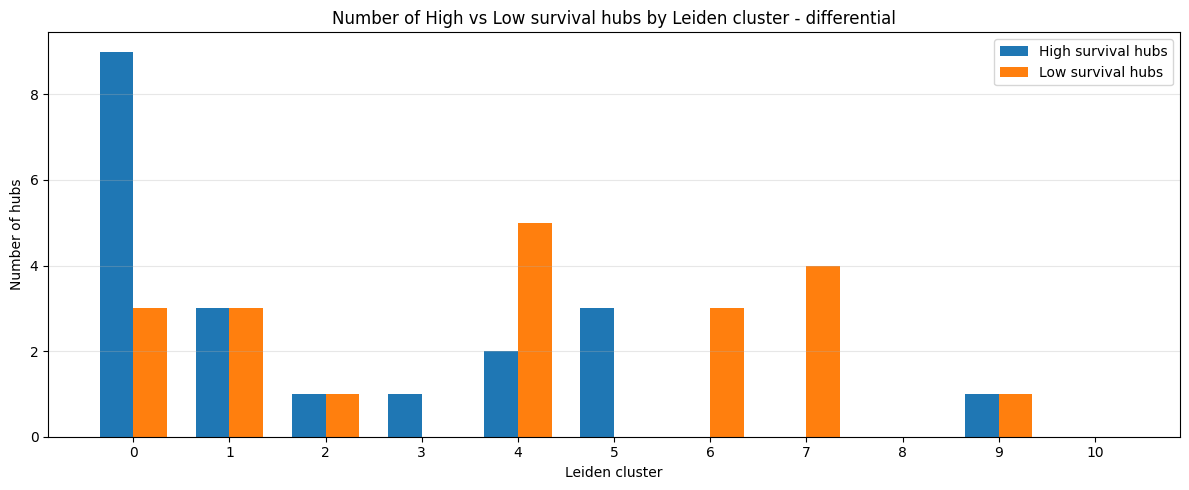

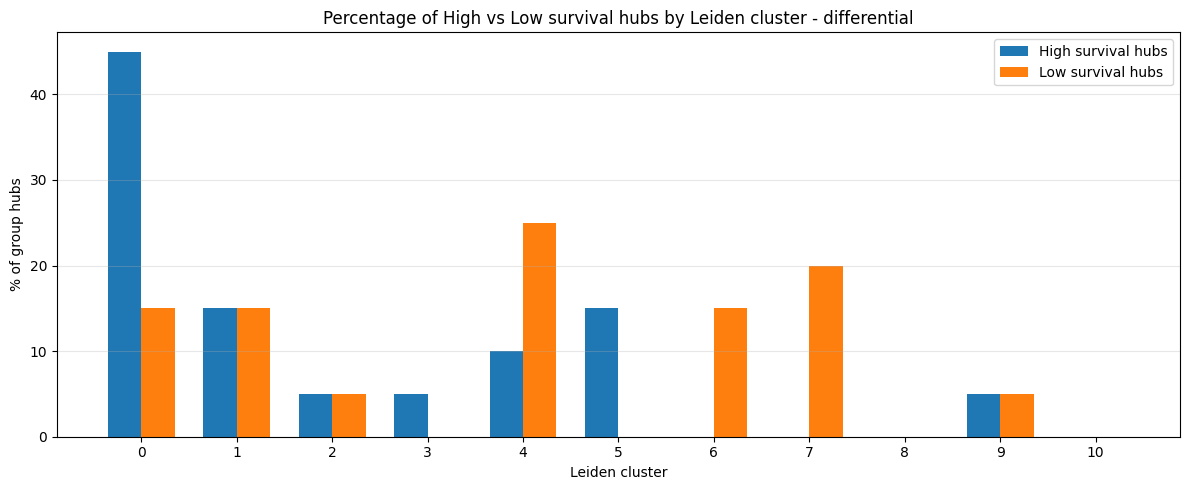


Saved long table:
data_lung\clinical_to_network_by_oncotree_groups\hub_genes_cluster_mapping_survival\readable_hub_counts_by_cluster\LUAD_NSCLC_differential_survival_hub_counts_by_cluster_long.csv

Saved wide readable table:
data_lung\clinical_to_network_by_oncotree_groups\hub_genes_cluster_mapping_survival\readable_hub_counts_by_cluster\LUAD_NSCLC_differential_survival_hub_counts_by_cluster_wide.csv

Saved focus table for clusters 1 and 3:
data_lung\clinical_to_network_by_oncotree_groups\hub_genes_cluster_mapping_survival\readable_hub_counts_by_cluster\LUAD_NSCLC_differential_survival_hub_counts_clusters_1_3.csv


In [55]:
import pandas as pd
import numpy as np
from pathlib import Path
import matplotlib.pyplot as plt

# ============================================================
# HUB COUNTS AND PERCENTAGES BY LEIDEN CLUSTER
# HIGH survival vs LOW survival
# LUAD_NSCLC
#
# Feature clinica di partenza: OS_MONTH
# ============================================================

data_dir = Path("data_lung")

oncotree_group = "LUAD_NSCLC"

HIGH_LABEL = "High survival"
LOW_LABEL = "Low survival"

survival_groups = [
    HIGH_LABEL,
    LOW_LABEL
]

# Scegli quale analisi usare:
# "differential" = geni più rappresentativi HIGH survival vs LOW survival
# "separate" = top hub genes presi separatamente da HIGH e LOW survival
ANALYSIS_MODE = "differential"
# ANALYSIS_MODE = "separate"

clusters_path = (
    data_dir
    / "networks_by_oncotree_groups"
    / "final_leiden_clusters_with_hub_metrics"
    / f"leiden_clusters_with_hub_metrics_{oncotree_group}.csv"
)

# ============================================================
# Input mapped files
# ============================================================

if ANALYSIS_MODE == "differential":

    candidate_mapped_paths = [
        data_dir
        / "clinical_to_network_by_oncotree_groups"
        / "hub_genes_cluster_mapping_survival"
        / "LUAD_NSCLC_differential_high_vs_low_survival_hub_genes_mapped_to_leiden_clusters.csv",

        data_dir
        / "clinical_to_network_by_oncotree_groups"
        / "hub_genes_cluster_mapping_survival"
        / "LUAD_NSCLC_differential_survival_hub_genes_mapped_to_leiden_clusters.csv",
    ]

elif ANALYSIS_MODE == "separate":

    candidate_mapped_paths = [
        data_dir
        / "clinical_to_network_by_oncotree_groups"
        / "hub_genes_cluster_mapping_survival"
        / "LUAD_NSCLC_separate_high_low_survival_top_hub_genes_mapped_to_leiden_clusters.csv",

        data_dir
        / "clinical_to_network_by_oncotree_groups"
        / "hub_genes_cluster_mapping_survival"
        / "LUAD_NSCLC_separate_high_vs_low_survival_top_hub_genes_mapped_to_leiden_clusters.csv",

        data_dir
        / "clinical_to_network_by_oncotree_groups"
        / "hub_genes_cluster_mapping_survival"
        / "LUAD_NSCLC_separate_survival_top_hub_genes_mapped_to_leiden_clusters.csv",
    ]

else:
    raise ValueError("ANALYSIS_MODE deve essere 'differential' oppure 'separate'.")

existing_paths = [
    path for path in candidate_mapped_paths
    if path.exists()
]

if len(existing_paths) == 0:
    print("Nessun file mapped trovato. Ho cercato questi path:")
    for path in candidate_mapped_paths:
        print(path)

    raise FileNotFoundError(
        "File di mapping hub genes -> Leiden clusters non trovato. "
        "Controlla il nome del file nella cartella hub_genes_cluster_mapping_survival."
    )

mapped_path = existing_paths[0]

output_dir = (
        data_dir
        / "clinical_to_network_by_oncotree_groups"
        / "hub_genes_cluster_mapping_survival"
        / "readable_hub_counts_by_cluster"
)

output_dir.mkdir(parents=True, exist_ok=True)


# ============================================================
# 1. Load files
# ============================================================

clusters = pd.read_csv(clusters_path, low_memory=False)
mapped = pd.read_csv(mapped_path, low_memory=False)

clusters = clusters.loc[:, ~clusters.columns.duplicated()].copy()

# Normalize column names from the final Leiden cluster file
clusters = clusters.rename(columns={
    "Hugo_Symbol": "Gene",
    "gene": "Gene",
    "GENE": "Gene",
    "cluster": "Cluster",
    "Leiden_cluster": "Cluster",
    "Leiden_Cluster": "Cluster",
    "leiden_cluster": "Cluster",
    "hubscore": "HubScore",
    "rank_in_cluster": "Rank_in_cluster",
    "Oncotree_Code": "Oncotree_Group",
    "ONCOTREE_CODE": "Oncotree_Group",
    "Oncotree Code": "Oncotree_Group"
})
clusters = clusters.loc[:, ~clusters.columns.duplicated()].copy()
mapped = mapped.loc[:, ~mapped.columns.duplicated()].copy()

clusters["Cluster"] = pd.to_numeric(clusters["Cluster"], errors="coerce")
mapped["Cluster"] = pd.to_numeric(mapped["Cluster"], errors="coerce")

clusters["Gene"] = clusters["Gene"].astype(str)
mapped["Gene"] = mapped["Gene"].astype(str)

print("Loaded clusters file:")
print(clusters_path)

print("\nLoaded mapped hub file:")
print(mapped_path)


# ============================================================
# 2. Identify hub group: HIGH survival or LOW survival
# ============================================================

def infer_hub_group(row):
    """
    Ricava se il gene appartiene al gruppo HIGH survival oppure LOW survival.

    Funziona con colonne come:
    - Signature_Group
    - Hub_List_Group
    - survival_group
    - Network_Group
    - Signature
    - Delta_HubScore_high_minus_low
    """

    text_parts = []

    possible_text_cols = [
        "Signature_Group",
        "Hub_List_Group",
        "survival_group",
        "Survival_Group",
        "SURVIVAL_GROUP",
        "Network_Group",
        "Group",
        "Signature",
        "signature_name",
        "Source_Group"
    ]

    for col in possible_text_cols:
        if col in row.index:
            text_parts.append(str(row[col]))

    text = " ".join(text_parts).lower()

    text_norm = (
        text
        .replace("-", " ")
        .replace("_", " ")
        .replace("/", " ")
        .replace("(", " ")
        .replace(")", " ")
    )

    tokens = set(text_norm.split())

    has_high = (
            "high" in tokens
            or "high survival" in text_norm
            or "high-survival" in text
            or "high_survival" in text
    )

    has_low = (
            "low" in tokens
            or "low survival" in text_norm
            or "low-survival" in text
            or "low_survival" in text
    )

    if has_high and not has_low:
        return HIGH_LABEL

    if has_low and not has_high:
        return LOW_LABEL

    # Fallback per tabelle differential:
    # se è presente il delta, il segno indica il gruppo.
    delta_col = "Delta_HubScore_high_minus_low"

    if delta_col in row.index:
        delta_value = pd.to_numeric(row[delta_col], errors="coerce")

        if pd.notna(delta_value):
            if delta_value > 0:
                return HIGH_LABEL
            elif delta_value < 0:
                return LOW_LABEL

    return np.nan


mapped["Hub_Group"] = mapped.apply(infer_hub_group, axis=1)

mapped = mapped.dropna(
    subset=["Gene", "Hub_Group"]
).copy()

# Tengo solo geni che sono stati effettivamente trovati nei cluster Leiden
mapped_in_clusters = mapped.dropna(subset=["Cluster"]).copy()
mapped_in_clusters["Cluster"] = mapped_in_clusters["Cluster"].astype(int)


# ============================================================
# 3. Cluster size
# ============================================================

cluster_sizes = (
    clusters
    .dropna(subset=["Cluster"])
    .assign(Cluster=lambda x: x["Cluster"].astype(int))
    .groupby("Cluster")
    .agg(
        cluster_size_genes=("Gene", "nunique")
    )
    .reset_index()
)


# ============================================================
# 4. Count hubs by survival group and cluster
# ============================================================

# Totale hub per gruppo, considerando solo quelli mappati nei cluster
total_hubs_by_group = (
    mapped_in_clusters
    .groupby("Hub_Group")
    .agg(
        total_hubs_group=("Gene", "nunique")
    )
    .reset_index()
)

hub_counts_long = (
    mapped_in_clusters
    .groupby(["Hub_Group", "Cluster"])
    .agg(
        n_hubs=("Gene", "nunique"),
        genes=("Gene", lambda x: ", ".join(sorted(x.dropna().astype(str).unique())))
    )
    .reset_index()
)

hub_counts_long = hub_counts_long.merge(
    total_hubs_by_group,
    on="Hub_Group",
    how="left"
)

hub_counts_long = hub_counts_long.merge(
    cluster_sizes,
    on="Cluster",
    how="left"
)

# Percentuale rispetto al totale degli hub del gruppo
# Esempio: quanti hub HIGH survival cadono nel cluster 1 rispetto a tutti gli hub HIGH?
hub_counts_long["pct_of_group_hubs"] = np.where(
    hub_counts_long["total_hubs_group"] > 0,
    hub_counts_long["n_hubs"] / hub_counts_long["total_hubs_group"] * 100,
    0
).round(2)

# Percentuale rispetto alla dimensione del cluster
# Esempio: quanti geni del cluster 1 sono hub HIGH survival?
hub_counts_long["pct_of_cluster_genes"] = np.where(
    hub_counts_long["cluster_size_genes"] > 0,
    hub_counts_long["n_hubs"] / hub_counts_long["cluster_size_genes"] * 100,
    0
).round(2)

hub_counts_long = hub_counts_long.sort_values(
    ["Cluster", "Hub_Group"]
).reset_index(drop=True)


# ============================================================
# 5. Wide table: easier to read HIGH vs LOW survival
# ============================================================

all_clusters = sorted(clusters["Cluster"].dropna().astype(int).unique())

all_combinations = pd.MultiIndex.from_product(
    [survival_groups, all_clusters],
    names=["Hub_Group", "Cluster"]
).to_frame(index=False)

hub_counts_complete = all_combinations.merge(
    hub_counts_long,
    on=["Hub_Group", "Cluster"],
    how="left"
)

hub_counts_complete = hub_counts_complete.merge(
    cluster_sizes,
    on="Cluster",
    how="left",
    suffixes=("", "_from_clusters")
)

hub_counts_complete["cluster_size_genes"] = (
    hub_counts_complete["cluster_size_genes"]
    .fillna(hub_counts_complete["cluster_size_genes_from_clusters"])
)

hub_counts_complete = hub_counts_complete.drop(
    columns=["cluster_size_genes_from_clusters"],
    errors="ignore"
)

hub_counts_complete["n_hubs"] = hub_counts_complete["n_hubs"].fillna(0).astype(int)
hub_counts_complete["genes"] = hub_counts_complete["genes"].fillna("-")

# Riaggiungo i totali per calcolare percentuali anche dove n_hubs = 0
hub_counts_complete = hub_counts_complete.drop(
    columns=["total_hubs_group"],
    errors="ignore"
).merge(
    total_hubs_by_group,
    on="Hub_Group",
    how="left"
)

hub_counts_complete["total_hubs_group"] = (
    hub_counts_complete["total_hubs_group"]
    .fillna(0)
)

hub_counts_complete["pct_of_group_hubs"] = np.where(
    hub_counts_complete["total_hubs_group"] > 0,
    hub_counts_complete["n_hubs"] / hub_counts_complete["total_hubs_group"] * 100,
    0
).round(2)

hub_counts_complete["pct_of_cluster_genes"] = np.where(
    hub_counts_complete["cluster_size_genes"] > 0,
    hub_counts_complete["n_hubs"] / hub_counts_complete["cluster_size_genes"] * 100,
    0
).round(2)


# ============================================================
# 5b. Build wide table with clean column names
# ============================================================

group_prefix = {
    HIGH_LABEL: "High",
    LOW_LABEL: "Low"
}

wide_parts = []

for group in survival_groups:

    prefix = group_prefix[group]

    tmp = hub_counts_complete[
        hub_counts_complete["Hub_Group"] == group
        ][
        [
            "Cluster",
            "n_hubs",
            "pct_of_group_hubs",
            "pct_of_cluster_genes",
            "genes"
        ]
    ].copy()

    tmp = tmp.rename(columns={
        "n_hubs": f"{prefix}_n_hubs",
        "pct_of_group_hubs": f"{prefix}_pct_of_group_hubs",
        "pct_of_cluster_genes": f"{prefix}_pct_of_cluster_genes",
        "genes": f"{prefix}_genes"
    })

    wide_parts.append(tmp)

hub_counts_wide = cluster_sizes.copy()

for tmp in wide_parts:
    hub_counts_wide = hub_counts_wide.merge(
        tmp,
        on="Cluster",
        how="left"
    )

hub_counts_wide = hub_counts_wide.fillna({
    "High_n_hubs": 0,
    "High_pct_of_group_hubs": 0,
    "High_pct_of_cluster_genes": 0,
    "High_genes": "-",
    "Low_n_hubs": 0,
    "Low_pct_of_group_hubs": 0,
    "Low_pct_of_cluster_genes": 0,
    "Low_genes": "-"
})

hub_counts_wide["High_n_hubs"] = hub_counts_wide["High_n_hubs"].astype(int)
hub_counts_wide["Low_n_hubs"] = hub_counts_wide["Low_n_hubs"].astype(int)

hub_counts_wide["Delta_n_hubs_High_minus_Low"] = (
        hub_counts_wide["High_n_hubs"]
        - hub_counts_wide["Low_n_hubs"]
)

hub_counts_wide["Delta_pct_group_High_minus_Low"] = (
        hub_counts_wide["High_pct_of_group_hubs"]
        - hub_counts_wide["Low_pct_of_group_hubs"]
).round(2)

hub_counts_wide = hub_counts_wide.sort_values("Cluster").reset_index(drop=True)


# ============================================================
# 6. Focus on prognostic clusters 1 and 3
# ============================================================

clusters_of_interest = [1, 3]

hub_counts_focus = hub_counts_wide[
    hub_counts_wide["Cluster"].isin(clusters_of_interest)
].copy()


# ============================================================
# 7. Display results
# ============================================================

pd.set_option("display.max_colwidth", 200)

display_cols = [
    "Cluster",
    "cluster_size_genes",
    "High_n_hubs",
    "High_pct_of_group_hubs",
    "Low_n_hubs",
    "Low_pct_of_group_hubs",
    "Delta_n_hubs_High_minus_Low",
    "Delta_pct_group_High_minus_Low",
    "High_genes",
    "Low_genes"
]

print("\n" + "=" * 120)
print(f"HUB COUNTS BY CLUSTER - {ANALYSIS_MODE.upper()} SURVIVAL HUB LIST")
print("=" * 120)

display(hub_counts_wide[display_cols])

print("\n" + "=" * 120)
print("FOCUS ON PROGNOSTIC CLUSTERS 1 AND 3")
print("=" * 120)

display(hub_counts_focus[display_cols])


# ============================================================
# 8. Plot: number of hubs by cluster
# ============================================================

plot_df = hub_counts_wide[
    [
        "Cluster",
        "High_n_hubs",
        "Low_n_hubs"
    ]
].copy()

x = np.arange(len(plot_df))
width = 0.35

plt.figure(figsize=(12, 5))

plt.bar(
    x - width / 2,
    plot_df["High_n_hubs"],
    width,
    label="High survival hubs"
)

plt.bar(
    x + width / 2,
    plot_df["Low_n_hubs"],
    width,
    label="Low survival hubs"
)

plt.xticks(x, plot_df["Cluster"])
plt.xlabel("Leiden cluster")
plt.ylabel("Number of hubs")
plt.title(
    f"Number of High vs Low survival hubs "
    f"by Leiden cluster - {ANALYSIS_MODE}"
)
plt.grid(axis="y", alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()


# ============================================================
# 9. Plot: percentage of group hubs by cluster
# ============================================================

plot_pct_df = hub_counts_wide[
    [
        "Cluster",
        "High_pct_of_group_hubs",
        "Low_pct_of_group_hubs"
    ]
].copy()

x = np.arange(len(plot_pct_df))
width = 0.35

plt.figure(figsize=(12, 5))

plt.bar(
    x - width / 2,
    plot_pct_df["High_pct_of_group_hubs"],
    width,
    label="High survival hubs"
)

plt.bar(
    x + width / 2,
    plot_pct_df["Low_pct_of_group_hubs"],
    width,
    label="Low survival hubs"
)

plt.xticks(x, plot_pct_df["Cluster"])
plt.xlabel("Leiden cluster")
plt.ylabel("% of group hubs")
plt.title(
    f"Percentage of High vs Low survival hubs "
    f"by Leiden cluster - {ANALYSIS_MODE}"
)
plt.grid(axis="y", alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()


# ============================================================
# 10. Save outputs
# ============================================================

long_output = (
        output_dir
        / f"LUAD_NSCLC_{ANALYSIS_MODE}_survival_hub_counts_by_cluster_long.csv"
)

wide_output = (
        output_dir
        / f"LUAD_NSCLC_{ANALYSIS_MODE}_survival_hub_counts_by_cluster_wide.csv"
)

focus_output = (
        output_dir
        / f"LUAD_NSCLC_{ANALYSIS_MODE}_survival_hub_counts_clusters_1_3.csv"
)

hub_counts_long.to_csv(long_output, index=False)
hub_counts_wide.to_csv(wide_output, index=False)
hub_counts_focus.to_csv(focus_output, index=False)

print("\nSaved long table:")
print(long_output)

print("\nSaved wide readable table:")
print(wide_output)

print("\nSaved focus table for clusters 1 and 3:")
print(focus_output)


Searching for differential survival mapped hub genes...
Candidate: data_lung\clinical_to_network_by_oncotree_groups\hub_genes_cluster_mapping_survival\LUAD_NSCLC_differential_high_vs_low_survival_hub_genes_mapped_to_leiden_clusters.csv
Found: data_lung\clinical_to_network_by_oncotree_groups\hub_genes_cluster_mapping_survival\LUAD_NSCLC_differential_high_vs_low_survival_hub_genes_mapped_to_leiden_clusters.csv

Loaded clusters:
data_lung\networks_by_oncotree_groups\final_leiden_clusters_with_hub_metrics\leiden_clusters_with_hub_metrics_LUAD_NSCLC.csv

Loaded mapped hub file:
data_lung\clinical_to_network_by_oncotree_groups\hub_genes_cluster_mapping_survival\LUAD_NSCLC_differential_high_vs_low_survival_hub_genes_mapped_to_leiden_clusters.csv

WEIGHTED HUB DISTRIBUTION BY CLUSTER - DIFFERENTIAL - RANK_INVERSE


,Cluster,cluster_size_genes,High_n_hubs,High_weighted_pct,Low_n_hubs,Low_weighted_pct,Delta_weighted_pct_High_minus_Low,High_best_rank,Low_best_rank,High_genes,Low_genes
0,0,93,9,69.14,3,34.08,35.06,1.0,1.0,"CSDE1, CSF3R, DNMT3A, HIST1H3B, MED12, NOTCH4, POLE, SPEN, TGFBR1","BRIP1, DIS3, RASA1"
1,1,49,3,10.40,3,6.69,3.71,5.0,9.0,"ATRX, ERCC5, MRE11A","CHEK2, RAD52, TGFBR2"
2,2,48,1,2.78,1,9.27,-6.49,10.0,3.0,ABL1,WT1
3,3,44,1,3.47,0,0.00,3.47,8.0,NaN,ASXL1,-
4,4,39,2,3.77,5,18.87,-15.10,13.0,4.0,"AXIN2, MAP2K4","CCND3, CD274, GNAS, PDCD1LG2, RTEL1"
5,5,23,3,7.35,0,0.00,7.35,7.0,NaN,"GATA3, PIK3CA, PRDM14",-
6,6,23,0,0.00,3,6.41,-6.41,NaN,8.0,-,"MAPK1, RPS6KB2, WHSC1"
7,7,15,0,0.00,4,19.12,-19.12,NaN,2.0,-,"H3C13, H3C14, RIT1, SETDB1"
8,8,15,0,0.00,0,0.00,0.00,NaN,NaN,-,-
9,9,7,1,3.09,1,5.56,-2.47,9.0,5.0,SLX4,TSC2



FOCUS ON PROGNOSTIC CLUSTERS 1 AND 3


,Cluster,cluster_size_genes,High_n_hubs,High_weighted_pct,Low_n_hubs,Low_weighted_pct,Delta_weighted_pct_High_minus_Low,High_best_rank,Low_best_rank,High_genes,Low_genes
1,1,49,3,10.40,3,6.69,3.71,5.0,9.0,"ATRX, ERCC5, MRE11A","CHEK2, RAD52, TGFBR2"
3,3,44,1,3.47,0,0.00,3.47,8.0,NaN,ASXL1,-



WEIGHTED GENE DETAIL - CLUSTERS 1 AND 3


,Hub_Group,Gene,Cluster,HubScore_for_weight,Hub_rank_in_group,raw_weight,normalized_weight,Signature_Group,Delta_HubScore_high_minus_low,Abs_Delta_HubScore,HubScore_high,HubScore_low,Degree_high,Degree_low,Node_Strength_high,Node_Strength_low
4,High survival,ATRX,1,0.747899,5,0.200000,5.5590,High-survival enriched hub genes,0.615021,0.615021,0.747899,0.132878,8.0,1.0,19.115936,2.209129
7,High survival,ASXL1,3,0.621324,8,0.125000,3.4744,High-survival enriched hub genes,0.621324,0.621324,0.621324,NaN,6.0,NaN,16.903063,NaN
10,High survival,ERCC5,1,0.507353,11,0.090909,2.5268,High-survival enriched hub genes,0.507353,0.507353,0.507353,NaN,4.0,NaN,12.034970,NaN
11,High survival,MRE11A,1,0.494748,12,0.083333,2.3163,High-survival enriched hub genes,0.494748,0.494748,0.494748,NaN,4.0,NaN,11.342280,NaN
28,Low survival,RAD52,1,0.573529,9,0.111111,3.0884,Low-survival enriched hub genes,-0.573529,0.573529,NaN,0.573529,NaN,4.0,NaN,20.573130
32,Low survival,TGFBR2,1,0.474265,13,0.076923,2.1381,Low-survival enriched hub genes,-0.474265,0.474265,NaN,0.474265,NaN,3.0,NaN,5.604694
38,Low survival,CHEK2,1,0.419643,19,0.052632,1.4629,Low-survival enriched hub genes,-0.419643,0.419643,NaN,0.419643,NaN,4.0,NaN,9.529857


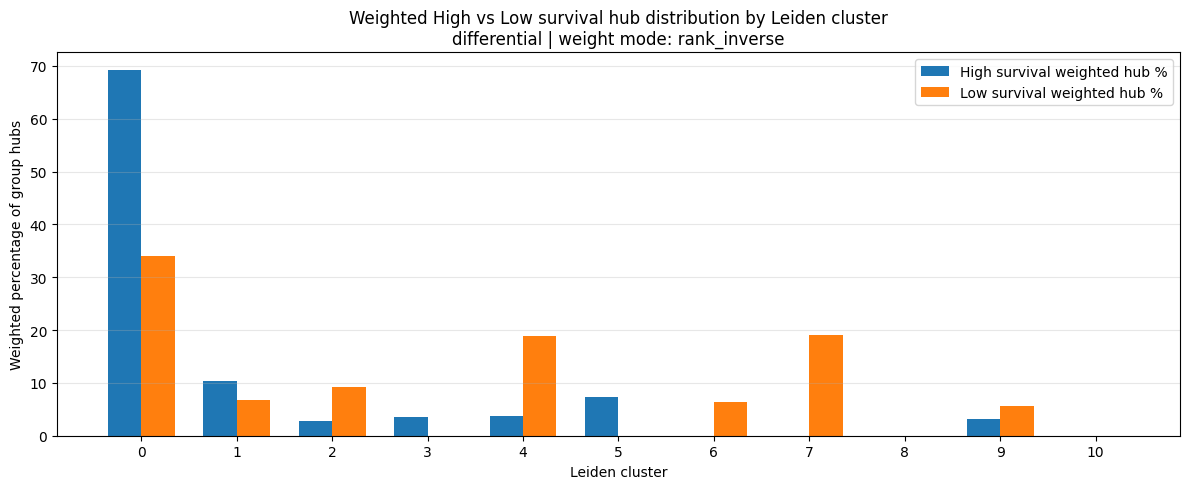

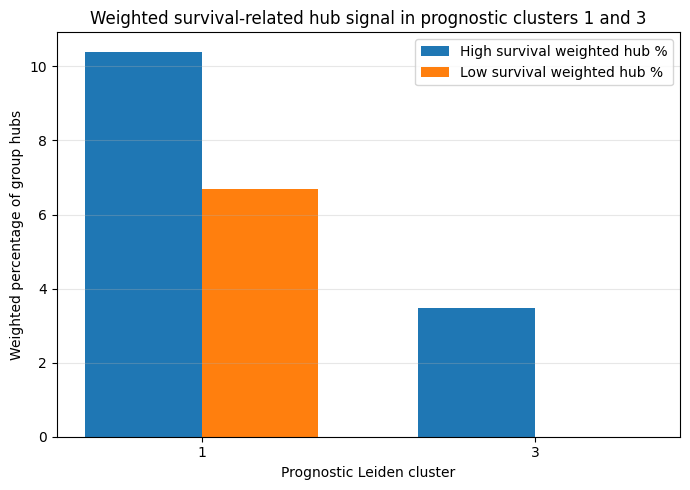


Saved weighted long table:
data_lung\clinical_to_network_by_oncotree_groups\hub_genes_cluster_mapping_survival\weighted_hub_distribution_by_cluster\LUAD_NSCLC_differential_rank_inverse_survival_weighted_hub_distribution_long.csv

Saved weighted wide table:
data_lung\clinical_to_network_by_oncotree_groups\hub_genes_cluster_mapping_survival\weighted_hub_distribution_by_cluster\LUAD_NSCLC_differential_rank_inverse_survival_weighted_hub_distribution_wide.csv

Saved weighted focus table:
data_lung\clinical_to_network_by_oncotree_groups\hub_genes_cluster_mapping_survival\weighted_hub_distribution_by_cluster\LUAD_NSCLC_differential_rank_inverse_survival_weighted_hub_distribution_clusters_1_3.csv

Saved weighted gene detail:
data_lung\clinical_to_network_by_oncotree_groups\hub_genes_cluster_mapping_survival\weighted_hub_distribution_by_cluster\LUAD_NSCLC_differential_rank_inverse_survival_weighted_gene_detail.csv

Saved weighted gene detail for clusters 1 and 3:
data_lung\clinical_to_network_

In [56]:
import pandas as pd
import numpy as np
from pathlib import Path
import matplotlib.pyplot as plt

# ============================================================
# WEIGHTED HUB DISTRIBUTION BY LEIDEN CLUSTER
# HIGH survival vs LOW survival
# LUAD_NSCLC
#
# Feature clinica di partenza: OS_MONTH
#
# Idea:
# - non conto solo quanti hub cadono in ogni cluster
# - do più peso agli hub più importanti
# - il peso diminuisce man mano che l'HubScore/rank peggiora
# ============================================================


# ============================================================
# 0. Settings
# ============================================================

data_dir = Path("data_lung")

oncotree_group = "LUAD_NSCLC"

HIGH_LABEL = "High survival"
LOW_LABEL = "Low survival"

SURVIVAL_GROUPS = [
    HIGH_LABEL,
    LOW_LABEL
]

# Scegli quale lista usare:
# "differential" = geni più rappresentativi HIGH survival vs LOW survival
# "separate" = top hub presi separatamente da HIGH e LOW survival
ANALYSIS_MODE = "differential"
# ANALYSIS_MODE = "separate"

# Tipo di peso:
# "hubscore" = usa direttamente HubScore normalizzato
# "rank_inverse" = peso = 1 / rank, quindi il primo pesa molto più degli ultimi
# "rank_linear" = peso decresce linearmente dal primo all'ultimo
WEIGHT_MODE = "rank_inverse"
# WEIGHT_MODE = "hubscore"
# WEIGHT_MODE = "rank_linear"

clusters_path = (
    data_dir
    / "networks_by_oncotree_groups"
    / "final_leiden_clusters_with_hub_metrics"
    / f"leiden_clusters_with_hub_metrics_{oncotree_group}.csv"
)

survival_base_dir = (
        data_dir
        / "clinical_to_network_by_oncotree_groups"
)

mapping_dir = (
        survival_base_dir
        / "hub_genes_cluster_mapping_survival"
)


# ============================================================
# Trova automaticamente il mapped file corretto
# ============================================================

def find_existing_file(candidate_paths, search_dir=None, patterns=None, description="file"):
    print(f"\nSearching for {description}...")

    for path in candidate_paths:
        print("Candidate:", path)
        if path.exists():
            print("Found:", path)
            return path

    if search_dir is not None and search_dir.exists() and patterns is not None:
        print(f"\nTrying automatic search in: {search_dir}")

        matches = []

        for pattern in patterns:
            matches.extend(sorted(search_dir.glob(pattern)))

        unique_matches = []
        seen = set()

        for path in matches:
            if path not in seen:
                unique_matches.append(path)
                seen.add(path)

        if len(unique_matches) > 0:
            print("Found by automatic search:")
            for path in unique_matches:
                print(path)

            return unique_matches[0]

    print(f"\nNo {description} found.")
    return None


if ANALYSIS_MODE == "differential":

    candidate_mapped_paths = [
        mapping_dir
        / "LUAD_NSCLC_differential_high_vs_low_survival_hub_genes_mapped_to_leiden_clusters.csv",

        mapping_dir
        / "LUAD_NSCLC_differential_survival_hub_genes_mapped_to_leiden_clusters.csv",
    ]

    mapped_patterns = [
        "*differential*high*low*survival*hub_genes_mapped_to_leiden_clusters.csv",
        "*differential*survival*hub_genes_mapped_to_leiden_clusters.csv",
        "*differential*survival*clusters*.csv",
    ]

elif ANALYSIS_MODE == "separate":

    candidate_mapped_paths = [
        mapping_dir
        / "LUAD_NSCLC_separate_high_low_survival_top_hub_genes_mapped_to_leiden_clusters.csv",

        mapping_dir
        / "LUAD_NSCLC_separate_high_vs_low_survival_top_hub_genes_mapped_to_leiden_clusters.csv",

        mapping_dir
        / "LUAD_NSCLC_separate_survival_top_hub_genes_mapped_to_leiden_clusters.csv",
    ]

    mapped_patterns = [
        "*separate*high*low*survival*top_hub_genes_mapped_to_leiden_clusters.csv",
        "*separate*survival*top_hub_genes_mapped_to_leiden_clusters.csv",
        "*separate*survival*clusters*.csv",
    ]

else:
    raise ValueError("ANALYSIS_MODE deve essere 'differential' oppure 'separate'.")


mapped_path = find_existing_file(
    candidate_paths=candidate_mapped_paths,
    search_dir=mapping_dir,
    patterns=mapped_patterns,
    description=f"{ANALYSIS_MODE} survival mapped hub genes"
)

if mapped_path is None:
    raise FileNotFoundError(
        "Non trovo il file mapped hub genes -> Leiden clusters per survival.\n"
        "Prima devi eseguire la cella che mappa gli hub HIGH/LOW survival sui cluster Leiden.\n"
        f"Cartella cercata:\n{mapping_dir}"
    )


output_dir = (
        survival_base_dir
        / "hub_genes_cluster_mapping_survival"
        / "weighted_hub_distribution_by_cluster"
)

output_dir.mkdir(parents=True, exist_ok=True)


# ============================================================
# 1. Load files
# ============================================================

if not clusters_path.exists():
    raise FileNotFoundError(
        "Non trovo il file dei cluster Leiden:\n"
        f"{clusters_path}"
    )

clusters = pd.read_csv(clusters_path, low_memory=False)
mapped = pd.read_csv(mapped_path, low_memory=False)

clusters = clusters.loc[:, ~clusters.columns.duplicated()].copy()

# Normalize column names from the final Leiden cluster file
clusters = clusters.rename(columns={
    "Hugo_Symbol": "Gene",
    "gene": "Gene",
    "GENE": "Gene",
    "cluster": "Cluster",
    "Leiden_cluster": "Cluster",
    "Leiden_Cluster": "Cluster",
    "leiden_cluster": "Cluster",
    "hubscore": "HubScore",
    "rank_in_cluster": "Rank_in_cluster",
    "Oncotree_Code": "Oncotree_Group",
    "ONCOTREE_CODE": "Oncotree_Group",
    "Oncotree Code": "Oncotree_Group"
})
clusters = clusters.loc[:, ~clusters.columns.duplicated()].copy()
mapped = mapped.loc[:, ~mapped.columns.duplicated()].copy()

clusters["Cluster"] = pd.to_numeric(clusters["Cluster"], errors="coerce")
mapped["Cluster"] = pd.to_numeric(mapped["Cluster"], errors="coerce")

clusters["Gene"] = clusters["Gene"].astype(str)
mapped["Gene"] = mapped["Gene"].astype(str)

print("\nLoaded clusters:")
print(clusters_path)

print("\nLoaded mapped hub file:")
print(mapped_path)


# ============================================================
# 2. Identify HIGH survival / LOW survival group
# ============================================================

def infer_hub_group(row):
    """
    Ricava se il gene appartiene al gruppo HIGH survival oppure LOW survival.

    Funziona sia per:
    - differential mapped table
    - separate top hub mapped table
    """

    text_parts = []

    possible_text_cols = [
        "Signature_Group",
        "Hub_List_Group",
        "survival_group",
        "Survival_Group",
        "SURVIVAL_GROUP",
        "Network_Group",
        "Group",
        "Signature",
        "signature_name",
        "Source_Group"
    ]

    for col in possible_text_cols:
        if col in row.index:
            text_parts.append(str(row[col]))

    text = " ".join(text_parts).lower()

    text_norm = (
        text
        .replace("-", " ")
        .replace("_", " ")
        .replace("/", " ")
        .replace("(", " ")
        .replace(")", " ")
        .replace(",", " ")
    )

    tokens = set(text_norm.split())

    has_high = (
            "high" in tokens
            or "high survival" in text_norm
            or "high-survival" in text
            or "high_survival" in text
    )

    has_low = (
            "low" in tokens
            or "low survival" in text_norm
            or "low-survival" in text
            or "low_survival" in text
    )

    if has_high and not has_low:
        return HIGH_LABEL

    if has_low and not has_high:
        return LOW_LABEL

    # Fallback per tabelle differential:
    # se è presente il delta, uso il segno del delta.
    delta_col = "Delta_HubScore_high_minus_low"

    if delta_col in row.index:
        delta_value = pd.to_numeric(row[delta_col], errors="coerce")

        if pd.notna(delta_value):
            if delta_value > 0:
                return HIGH_LABEL
            elif delta_value < 0:
                return LOW_LABEL

    return np.nan


mapped["Hub_Group"] = mapped.apply(infer_hub_group, axis=1)

mapped = mapped.dropna(
    subset=["Gene", "Hub_Group", "Cluster"]
).copy()

mapped["Cluster"] = mapped["Cluster"].astype(int)


# ============================================================
# 3. Select correct HubScore for each row
# ============================================================

def get_group_hubscore(row):
    """
    Per differential:
    - HIGH survival usa HubScore_high
    - LOW survival usa HubScore_low

    Per separate:
    - usa HubScore
    """

    group = row["Hub_Group"]

    if group == HIGH_LABEL:
        if "HubScore_high" in row.index and pd.notna(row["HubScore_high"]):
            return row["HubScore_high"]

    if group == LOW_LABEL:
        if "HubScore_low" in row.index and pd.notna(row["HubScore_low"]):
            return row["HubScore_low"]

    if "HubScore" in row.index and pd.notna(row["HubScore"]):
        return row["HubScore"]

    if "Abs_Delta_HubScore" in row.index and pd.notna(row["Abs_Delta_HubScore"]):
        return row["Abs_Delta_HubScore"]

    return np.nan


mapped["HubScore_for_weight"] = mapped.apply(get_group_hubscore, axis=1)

mapped["HubScore_for_weight"] = pd.to_numeric(
    mapped["HubScore_for_weight"],
    errors="coerce"
)

mapped = mapped.dropna(
    subset=["HubScore_for_weight"]
).copy()

if mapped.empty:
    raise ValueError(
        "Dopo il filtro HubScore_for_weight, la tabella mapped è vuota. "
        "Controlla che il file mapped contenga HubScore_high / HubScore_low "
        "oppure HubScore."
    )


# ============================================================
# 4. Rank hubs within each group and assign weight
# ============================================================

mapped = mapped.sort_values(
    ["Hub_Group", "HubScore_for_weight"],
    ascending=[True, False]
).copy()

mapped["Hub_rank_in_group"] = (
    mapped
    .groupby("Hub_Group")["HubScore_for_weight"]
    .rank(method="first", ascending=False)
    .astype(int)
)

mapped["n_hubs_in_group"] = (
    mapped
    .groupby("Hub_Group")["Gene"]
    .transform("nunique")
)


def assign_weight(row):
    rank = row["Hub_rank_in_group"]
    n = row["n_hubs_in_group"]
    hubscore = row["HubScore_for_weight"]

    if WEIGHT_MODE == "hubscore":
        return hubscore

    if WEIGHT_MODE == "rank_inverse":
        return 1 / rank

    if WEIGHT_MODE == "rank_linear":
        if n <= 1:
            return 1
        return (n - rank + 1) / n

    raise ValueError("WEIGHT_MODE non valido.")


mapped["raw_weight"] = mapped.apply(assign_weight, axis=1)

# Normalizzo i pesi dentro ciascun gruppo:
# la somma dei pesi HIGH survival = 100
# la somma dei pesi LOW survival = 100
mapped["normalized_weight"] = (
        mapped["raw_weight"]
        / mapped.groupby("Hub_Group")["raw_weight"].transform("sum")
        * 100
)

mapped["normalized_weight"] = mapped["normalized_weight"].round(4)


# ============================================================
# 5. Cluster sizes
# ============================================================

cluster_sizes = (
    clusters
    .dropna(subset=["Cluster"])
    .assign(Cluster=lambda x: x["Cluster"].astype(int))
    .groupby("Cluster")
    .agg(
        cluster_size_genes=("Gene", "nunique")
    )
    .reset_index()
)


# ============================================================
# 6. Weighted summary by group and cluster
# ============================================================

weighted_long = (
    mapped
    .groupby(["Hub_Group", "Cluster"])
    .agg(
        n_hubs=("Gene", "nunique"),
        weighted_hub_score=("normalized_weight", "sum"),
        mean_hubscore=("HubScore_for_weight", "mean"),
        max_hubscore=("HubScore_for_weight", "max"),
        best_rank=("Hub_rank_in_group", "min"),
        genes=(
            "Gene",
            lambda x: ", ".join(sorted(x.dropna().astype(str).unique()))
        )
    )
    .reset_index()
)

weighted_long["weighted_hub_score"] = weighted_long["weighted_hub_score"].round(2)
weighted_long["mean_hubscore"] = weighted_long["mean_hubscore"].round(4)
weighted_long["max_hubscore"] = weighted_long["max_hubscore"].round(4)

weighted_long = weighted_long.merge(
    cluster_sizes,
    on="Cluster",
    how="left"
)

weighted_long["pct_cluster_covered_by_hubs"] = np.where(
    weighted_long["cluster_size_genes"] > 0,
    weighted_long["n_hubs"] / weighted_long["cluster_size_genes"] * 100,
    0
).round(2)

weighted_long = weighted_long.sort_values(
    ["Hub_Group", "weighted_hub_score"],
    ascending=[True, False]
).reset_index(drop=True)


# ============================================================
# 7. Wide readable table
# ============================================================

all_clusters = sorted(clusters["Cluster"].dropna().astype(int).unique())

all_combinations = pd.MultiIndex.from_product(
    [SURVIVAL_GROUPS, all_clusters],
    names=["Hub_Group", "Cluster"]
).to_frame(index=False)

weighted_complete = all_combinations.merge(
    weighted_long,
    on=["Hub_Group", "Cluster"],
    how="left"
)

weighted_complete = weighted_complete.merge(
    cluster_sizes,
    on="Cluster",
    how="left",
    suffixes=("", "_from_clusters")
)

weighted_complete["cluster_size_genes"] = (
    weighted_complete["cluster_size_genes"]
    .fillna(weighted_complete["cluster_size_genes_from_clusters"])
)

weighted_complete = weighted_complete.drop(
    columns=["cluster_size_genes_from_clusters"],
    errors="ignore"
)

fill_zero_cols = [
    "n_hubs",
    "weighted_hub_score",
    "mean_hubscore",
    "max_hubscore",
    "pct_cluster_covered_by_hubs"
]

for col in fill_zero_cols:
    if col in weighted_complete.columns:
        weighted_complete[col] = weighted_complete[col].fillna(0)

weighted_complete["best_rank"] = weighted_complete["best_rank"].fillna(np.nan)
weighted_complete["genes"] = weighted_complete["genes"].fillna("-")


group_prefix = {
    HIGH_LABEL: "High",
    LOW_LABEL: "Low"
}

wide_parts = []

for group in SURVIVAL_GROUPS:

    prefix = group_prefix[group]

    tmp = weighted_complete[
        weighted_complete["Hub_Group"] == group
        ][
        [
            "Cluster",
            "n_hubs",
            "weighted_hub_score",
            "mean_hubscore",
            "max_hubscore",
            "best_rank",
            "pct_cluster_covered_by_hubs",
            "genes"
        ]
    ].copy()

    tmp = tmp.rename(columns={
        "n_hubs": f"{prefix}_n_hubs",
        "weighted_hub_score": f"{prefix}_weighted_pct",
        "mean_hubscore": f"{prefix}_mean_hubscore",
        "max_hubscore": f"{prefix}_max_hubscore",
        "best_rank": f"{prefix}_best_rank",
        "pct_cluster_covered_by_hubs": f"{prefix}_pct_cluster_covered",
        "genes": f"{prefix}_genes"
    })

    wide_parts.append(tmp)

weighted_wide = cluster_sizes.copy()

for tmp in wide_parts:
    weighted_wide = weighted_wide.merge(
        tmp,
        on="Cluster",
        how="left"
    )

weighted_wide = weighted_wide.fillna({
    "High_n_hubs": 0,
    "High_weighted_pct": 0,
    "High_mean_hubscore": 0,
    "High_max_hubscore": 0,
    "High_pct_cluster_covered": 0,
    "High_genes": "-",
    "Low_n_hubs": 0,
    "Low_weighted_pct": 0,
    "Low_mean_hubscore": 0,
    "Low_max_hubscore": 0,
    "Low_pct_cluster_covered": 0,
    "Low_genes": "-"
})

weighted_wide["High_n_hubs"] = weighted_wide["High_n_hubs"].astype(int)
weighted_wide["Low_n_hubs"] = weighted_wide["Low_n_hubs"].astype(int)

weighted_wide["Delta_weighted_pct_High_minus_Low"] = (
        weighted_wide["High_weighted_pct"]
        - weighted_wide["Low_weighted_pct"]
).round(2)

weighted_wide["Delta_n_hubs_High_minus_Low"] = (
        weighted_wide["High_n_hubs"]
        - weighted_wide["Low_n_hubs"]
)

weighted_wide = weighted_wide.sort_values("Cluster").reset_index(drop=True)


# ============================================================
# 8. Add ranked genes with weights for easier inspection
# ============================================================

weighted_gene_detail = mapped[
    [
        "Hub_Group",
        "Gene",
        "Cluster",
        "HubScore_for_weight",
        "Hub_rank_in_group",
        "raw_weight",
        "normalized_weight"
    ]
].copy()

extra_cols = [
    "Signature_Group",
    "Hub_List_Group",
    "Delta_HubScore_high_minus_low",
    "Abs_Delta_HubScore",
    "HubScore_high",
    "HubScore_low",
    "Degree_high",
    "Degree_low",
    "Node_Strength_high",
    "Node_Strength_low"
]

for col in extra_cols:
    if col in mapped.columns:
        weighted_gene_detail[col] = mapped[col]

weighted_gene_detail = weighted_gene_detail.sort_values(
    ["Hub_Group", "Hub_rank_in_group"]
).reset_index(drop=True)


# ============================================================
# 9. Focus on prognostic clusters 1 and 3
# ============================================================

clusters_of_interest = [1, 3]

weighted_focus = weighted_wide[
    weighted_wide["Cluster"].isin(clusters_of_interest)
].copy()

weighted_gene_focus = weighted_gene_detail[
    weighted_gene_detail["Cluster"].isin(clusters_of_interest)
].copy()


# ============================================================
# 10. Display results
# ============================================================

pd.set_option("display.max_colwidth", 220)

display_cols = [
    "Cluster",
    "cluster_size_genes",
    "High_n_hubs",
    "High_weighted_pct",
    "Low_n_hubs",
    "Low_weighted_pct",
    "Delta_weighted_pct_High_minus_Low",
    "High_best_rank",
    "Low_best_rank",
    "High_genes",
    "Low_genes"
]

print("\n" + "=" * 120)
print(f"WEIGHTED HUB DISTRIBUTION BY CLUSTER - {ANALYSIS_MODE.upper()} - {WEIGHT_MODE.upper()}")
print("=" * 120)

display(weighted_wide[display_cols])

print("\n" + "=" * 120)
print("FOCUS ON PROGNOSTIC CLUSTERS 1 AND 3")
print("=" * 120)

display(weighted_focus[display_cols])

print("\n" + "=" * 120)
print("WEIGHTED GENE DETAIL - CLUSTERS 1 AND 3")
print("=" * 120)

display(weighted_gene_focus)


# ============================================================
# 11. Plot weighted percentage by cluster
# ============================================================

plot_df = weighted_wide[
    [
        "Cluster",
        "High_weighted_pct",
        "Low_weighted_pct"
    ]
].copy()

x = np.arange(len(plot_df))
width = 0.35

plt.figure(figsize=(12, 5))

plt.bar(
    x - width / 2,
    plot_df["High_weighted_pct"],
    width,
    label="High survival weighted hub %"
)

plt.bar(
    x + width / 2,
    plot_df["Low_weighted_pct"],
    width,
    label="Low survival weighted hub %"
)

plt.xticks(x, plot_df["Cluster"])
plt.xlabel("Leiden cluster")
plt.ylabel("Weighted percentage of group hubs")
plt.title(
    f"Weighted High vs Low survival hub distribution by Leiden cluster\n"
    f"{ANALYSIS_MODE} | weight mode: {WEIGHT_MODE}"
)
plt.grid(axis="y", alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()


# ============================================================
# 12. Plot focus clusters 1 and 3
# ============================================================

plot_focus = weighted_focus[
    [
        "Cluster",
        "High_weighted_pct",
        "Low_weighted_pct"
    ]
].copy()

x = np.arange(len(plot_focus))
width = 0.35

plt.figure(figsize=(7, 5))

plt.bar(
    x - width / 2,
    plot_focus["High_weighted_pct"],
    width,
    label="High survival weighted hub %"
)

plt.bar(
    x + width / 2,
    plot_focus["Low_weighted_pct"],
    width,
    label="Low survival weighted hub %"
)

plt.xticks(x, plot_focus["Cluster"])
plt.xlabel("Prognostic Leiden cluster")
plt.ylabel("Weighted percentage of group hubs")
plt.title("Weighted survival-related hub signal in prognostic clusters 1 and 3")
plt.grid(axis="y", alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()


# ============================================================
# 13. Save outputs
# ============================================================

weighted_long_output = (
        output_dir
        / f"LUAD_NSCLC_{ANALYSIS_MODE}_{WEIGHT_MODE}_survival_weighted_hub_distribution_long.csv"
)

weighted_wide_output = (
        output_dir
        / f"LUAD_NSCLC_{ANALYSIS_MODE}_{WEIGHT_MODE}_survival_weighted_hub_distribution_wide.csv"
)

weighted_focus_output = (
        output_dir
        / f"LUAD_NSCLC_{ANALYSIS_MODE}_{WEIGHT_MODE}_survival_weighted_hub_distribution_clusters_1_3.csv"
)

weighted_gene_detail_output = (
        output_dir
        / f"LUAD_NSCLC_{ANALYSIS_MODE}_{WEIGHT_MODE}_survival_weighted_gene_detail.csv"
)

weighted_gene_focus_output = (
        output_dir
        / f"LUAD_NSCLC_{ANALYSIS_MODE}_{WEIGHT_MODE}_survival_weighted_gene_detail_clusters_1_3.csv"
)

weighted_long.to_csv(weighted_long_output, index=False)
weighted_wide.to_csv(weighted_wide_output, index=False)
weighted_focus.to_csv(weighted_focus_output, index=False)
weighted_gene_detail.to_csv(weighted_gene_detail_output, index=False)
weighted_gene_focus.to_csv(weighted_gene_focus_output, index=False)

print("\nSaved weighted long table:")
print(weighted_long_output)

print("\nSaved weighted wide table:")
print(weighted_wide_output)

print("\nSaved weighted focus table:")
print(weighted_focus_output)

print("\nSaved weighted gene detail:")
print(weighted_gene_detail_output)

print("\nSaved weighted gene detail for clusters 1 and 3:")
print(weighted_gene_focus_output)


Available mapped genes by group:


,Hub_Group,available_genes,max_rank
0,High survival,20,20
1,Low survival,20,20



ATTENZIONE: almeno un gruppo ha meno geni disponibili del massimo top_n richiesto.
Se il file mapped è stato generato con top_n=20, non puoi fare una vera sensitivity a top_n=30 o top_n=50 senza rigenerare prima il mapping con un top_n più alto.

TOP 3 DOMINANT CLUSTERS BY TOP_N AND GROUP


,top_n,Hub_Group,Cluster,n_hubs,weighted_hub_score,best_rank,genes
0,10,High survival,0,5,76.82,1,"DNMT3A, MED12, NOTCH4, POLE, SPEN"
1,10,High survival,1,1,6.83,5,ATRX
2,10,High survival,5,1,4.88,7,PIK3CA
3,10,Low survival,0,2,39.02,1,"DIS3, RASA1"
4,10,Low survival,4,3,17.64,4,"CD274, GNAS, RTEL1"
5,10,Low survival,7,1,17.07,2,RIT1
6,20,High survival,0,9,69.14,1,"CSDE1, CSF3R, DNMT3A, HIST1H3B, MED12, NOTCH4, POLE, SPEN, TGFBR1"
7,20,High survival,1,3,10.40,5,"ATRX, ERCC5, MRE11A"
8,20,High survival,5,3,7.35,7,"GATA3, PIK3CA, PRDM14"
9,20,Low survival,0,3,34.08,1,"BRIP1, DIS3, RASA1"



SENSITIVITY FOCUS ON CLUSTERS [1, 3]


,top_n,Cluster,cluster_size_genes,High_n_hubs,High_weighted_pct,Low_n_hubs,Low_weighted_pct,Delta_weighted_pct_High_minus_Low,High_genes,Low_genes
1,10,1,49,1,6.83,1,3.79,3.04,ATRX,RAD52
3,10,3,44,1,4.27,0,0.00,4.27,ASXL1,-
12,20,1,49,3,10.40,3,6.69,3.71,"ATRX, ERCC5, MRE11A","CHEK2, RAD52, TGFBR2"
14,20,3,44,1,3.47,0,0.00,3.47,ASXL1,-
23,30,1,49,3,10.40,3,6.69,3.71,"ATRX, ERCC5, MRE11A","CHEK2, RAD52, TGFBR2"
25,30,3,44,1,3.47,0,0.00,3.47,ASXL1,-
34,50,1,49,3,10.40,3,6.69,3.71,"ATRX, ERCC5, MRE11A","CHEK2, RAD52, TGFBR2"
36,50,3,44,1,3.47,0,0.00,3.47,ASXL1,-


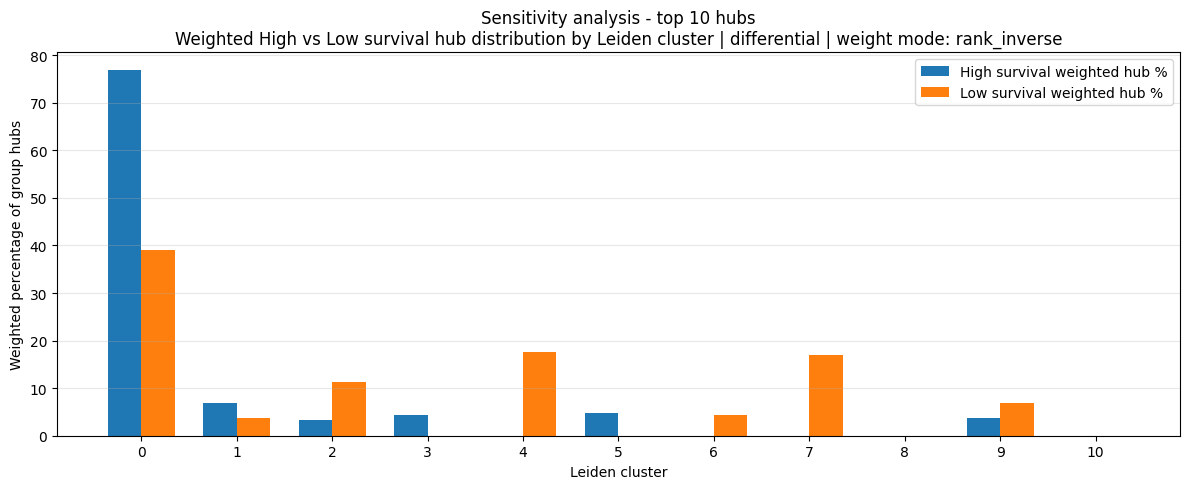

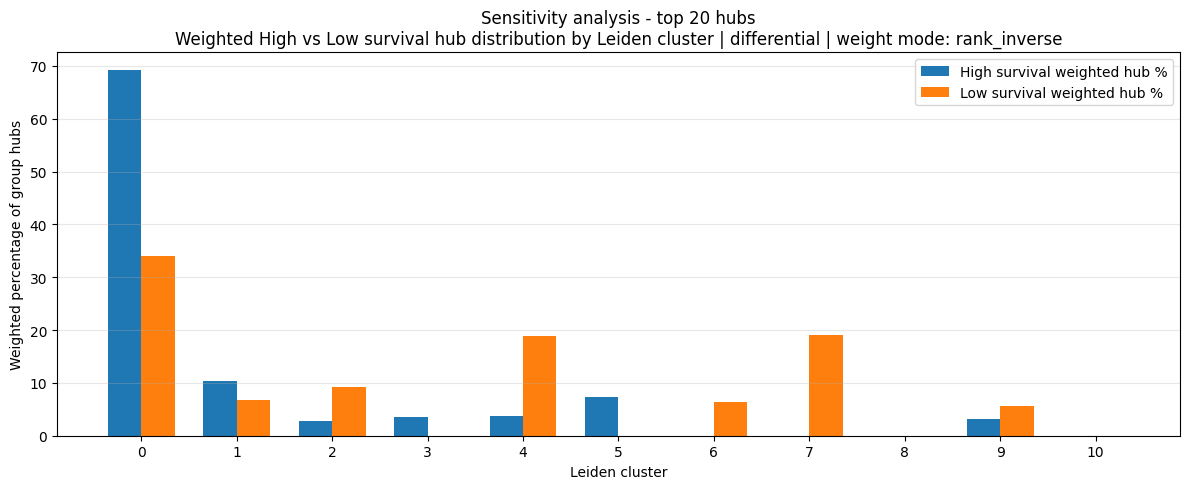

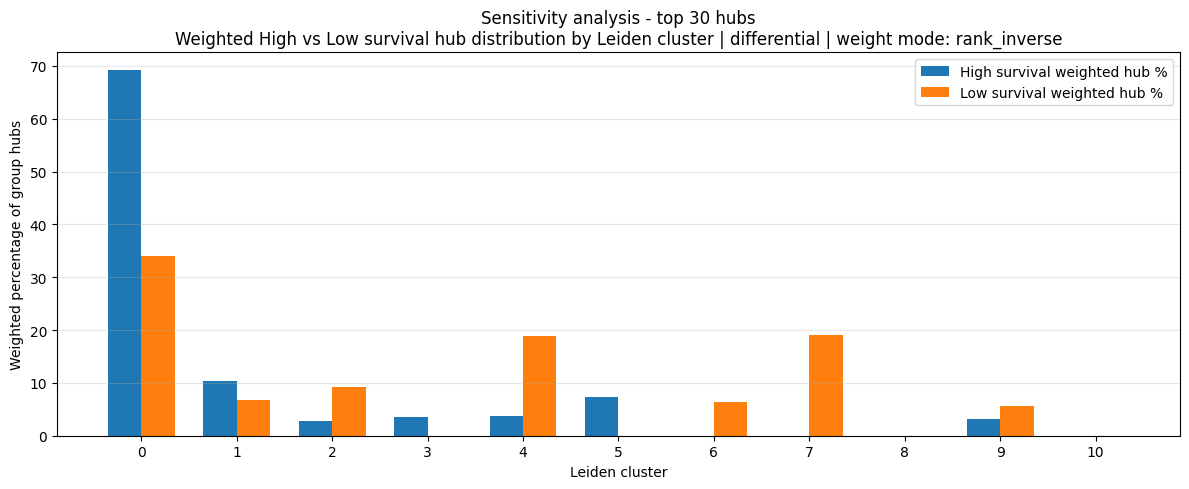

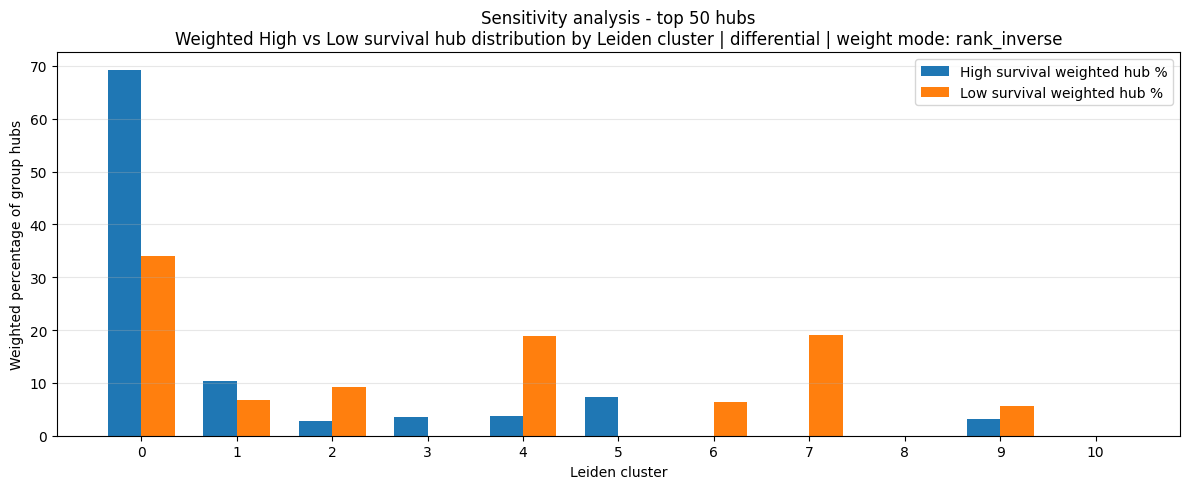

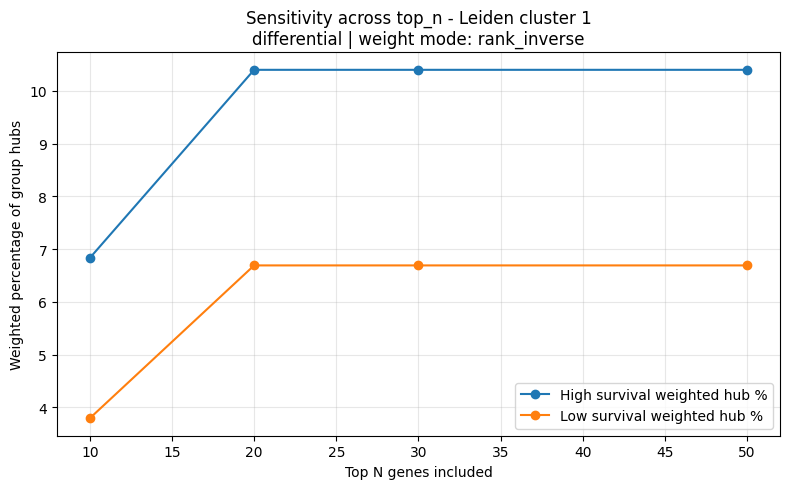

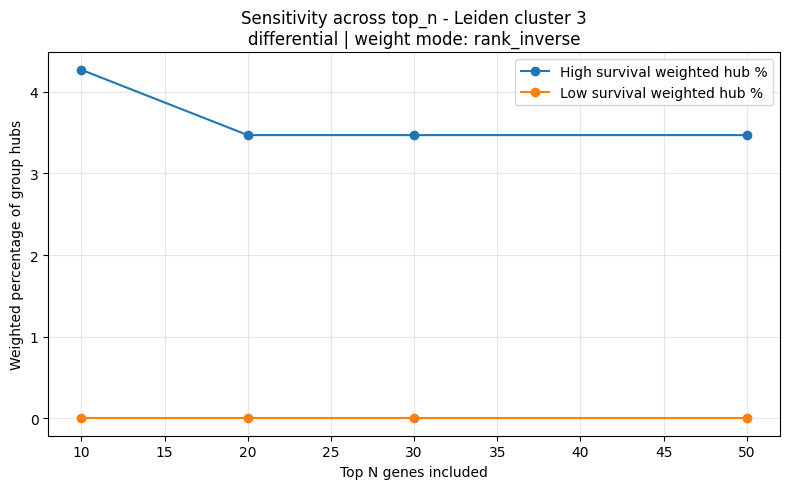


Saved sensitivity long table:
data_lung\clinical_to_network_by_oncotree_groups\hub_genes_cluster_mapping_survival\weighted_hub_distribution_by_cluster\sensitivity_analysis_top_n\LUAD_NSCLC_differential_rank_inverse_survival_sensitivity_top_n_long.csv

Saved sensitivity wide table:
data_lung\clinical_to_network_by_oncotree_groups\hub_genes_cluster_mapping_survival\weighted_hub_distribution_by_cluster\sensitivity_analysis_top_n\LUAD_NSCLC_differential_rank_inverse_survival_sensitivity_top_n_wide.csv

Saved sensitivity focus table:
data_lung\clinical_to_network_by_oncotree_groups\hub_genes_cluster_mapping_survival\weighted_hub_distribution_by_cluster\sensitivity_analysis_top_n\LUAD_NSCLC_differential_rank_inverse_survival_sensitivity_top_n_focus_clusters.csv

Saved dominant clusters table:
data_lung\clinical_to_network_by_oncotree_groups\hub_genes_cluster_mapping_survival\weighted_hub_distribution_by_cluster\sensitivity_analysis_top_n\LUAD_NSCLC_differential_rank_inverse_survival_sensiti

In [57]:
# ============================================================
# SENSITIVITY ANALYSIS
# Weighted hub distribution by Leiden cluster
# HIGH survival vs LOW survival
#
# Obiettivo:
# - confrontare la distribuzione pesata degli hub usando diversi top_n
# - capire se il segnale sui cluster è stabile
#
# Da eseguire DOPO la cella:
# WEIGHTED HUB DISTRIBUTION BY LEIDEN CLUSTER - HIGH vs LOW survival
# ============================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path


# ============================================================
# 0. Settings
# ============================================================

TOP_N_VALUES = [10, 20, 30, 50]

# Mantengo lo stesso weight mode della cella precedente
SENSITIVITY_WEIGHT_MODE = WEIGHT_MODE

# Cluster da monitorare in modo specifico
# Modifica qui se vuoi concentrarti su altri cluster
clusters_of_interest = [1, 3]

sensitivity_output_dir = (
        output_dir
        / "sensitivity_analysis_top_n"
)

sensitivity_output_dir.mkdir(parents=True, exist_ok=True)


# ============================================================
# 1. Check input variables
# ============================================================

required_vars = [
    "mapped",
    "clusters",
    "HIGH_LABEL",
    "LOW_LABEL",
    "SURVIVAL_GROUPS",
    "ANALYSIS_MODE",
    "WEIGHT_MODE",
    "output_dir"
]

missing_vars = [
    var for var in required_vars
    if var not in globals()
]

if missing_vars:
    raise ValueError(
        f"Variabili mancanti: {missing_vars}. "
        "Esegui prima la cella della weighted hub distribution HIGH vs LOW survival."
    )

if "oncotree_group" not in globals():
    oncotree_group = "LUAD_NSCLC"


# ============================================================
# 2. Prepare base mapped table
# ============================================================

base_mapped = mapped.copy()
base_mapped = base_mapped.loc[:, ~base_mapped.columns.duplicated()].copy()

required_cols = {
    "Gene",
    "Cluster",
    "Hub_Group",
    "HubScore_for_weight"
}

missing_cols = required_cols - set(base_mapped.columns)

if missing_cols:
    raise ValueError(
        f"Colonne mancanti in mapped: {missing_cols}. "
        "Controlla che la cella precedente abbia creato Hub_Group e HubScore_for_weight."
    )

base_mapped["Gene"] = base_mapped["Gene"].astype(str)
base_mapped["Cluster"] = pd.to_numeric(base_mapped["Cluster"], errors="coerce")
base_mapped["HubScore_for_weight"] = pd.to_numeric(
    base_mapped["HubScore_for_weight"],
    errors="coerce"
)

base_mapped = base_mapped.dropna(
    subset=[
        "Gene",
        "Cluster",
        "Hub_Group",
        "HubScore_for_weight"
    ]
).copy()

base_mapped["Cluster"] = base_mapped["Cluster"].astype(int)

# Una riga per gene dentro ciascun gruppo
base_mapped = (
    base_mapped
    .sort_values(
        ["Hub_Group", "HubScore_for_weight"],
        ascending=[True, False]
    )
    .drop_duplicates(["Hub_Group", "Gene"], keep="first")
    .copy()
)

base_mapped["Full_rank_in_group"] = (
    base_mapped
    .groupby("Hub_Group")["HubScore_for_weight"]
    .rank(method="first", ascending=False)
    .astype(int)
)

available_by_group = (
    base_mapped
    .groupby("Hub_Group")
    .agg(
        available_genes=("Gene", "nunique"),
        max_rank=("Full_rank_in_group", "max")
    )
    .reset_index()
)

print("\nAvailable mapped genes by group:")
display(available_by_group)

max_requested_top_n = max(TOP_N_VALUES)

if available_by_group["available_genes"].min() < max_requested_top_n:
    print(
        "\nATTENZIONE: almeno un gruppo ha meno geni disponibili del massimo top_n richiesto.\n"
        "Se il file mapped è stato generato con top_n=20, non puoi fare una vera sensitivity "
        "a top_n=30 o top_n=50 senza rigenerare prima il mapping con un top_n più alto."
    )


# ============================================================
# 3. Cluster sizes
# ============================================================

clusters_tmp = clusters.copy()
clusters_tmp = clusters_tmp.loc[:, ~clusters_tmp.columns.duplicated()].copy()

clusters_tmp["Cluster"] = pd.to_numeric(
    clusters_tmp["Cluster"],
    errors="coerce"
)

clusters_tmp["Gene"] = clusters_tmp["Gene"].astype(str)

cluster_sizes_sens = (
    clusters_tmp
    .dropna(subset=["Cluster"])
    .assign(Cluster=lambda x: x["Cluster"].astype(int))
    .groupby("Cluster")
    .agg(
        cluster_size_genes=("Gene", "nunique")
    )
    .reset_index()
)

all_clusters = sorted(
    cluster_sizes_sens["Cluster"]
    .dropna()
    .astype(int)
    .unique()
)


# ============================================================
# 4. Helper functions
# ============================================================

def assign_sensitivity_weight(row, weight_mode):
    rank = row["Hub_rank_in_selected_group"]
    n = row["n_hubs_in_selected_group"]
    hubscore = row["HubScore_for_weight"]

    if weight_mode == "hubscore":
        return hubscore

    if weight_mode == "rank_inverse":
        return 1 / rank

    if weight_mode == "rank_linear":
        if n <= 1:
            return 1
        return (n - rank + 1) / n

    raise ValueError("SENSITIVITY_WEIGHT_MODE non valido.")


def compute_weighted_distribution_for_top_n(top_n):
    """
    Calcola distribuzione pesata per uno specifico top_n.
    """

    selected = (
        base_mapped[
            base_mapped["Full_rank_in_group"] <= top_n
            ]
        .copy()
    )

    if selected.empty:
        return pd.DataFrame(), pd.DataFrame(), pd.DataFrame()

    selected = selected.sort_values(
        ["Hub_Group", "HubScore_for_weight"],
        ascending=[True, False]
    ).copy()

    selected["Hub_rank_in_selected_group"] = (
        selected
        .groupby("Hub_Group")["HubScore_for_weight"]
        .rank(method="first", ascending=False)
        .astype(int)
    )

    selected["n_hubs_in_selected_group"] = (
        selected
        .groupby("Hub_Group")["Gene"]
        .transform("nunique")
    )

    selected["raw_weight"] = selected.apply(
        lambda row: assign_sensitivity_weight(
            row,
            SENSITIVITY_WEIGHT_MODE
        ),
        axis=1
    )

    selected["normalized_weight"] = (
            selected["raw_weight"]
            / selected.groupby("Hub_Group")["raw_weight"].transform("sum")
            * 100
    )

    selected["normalized_weight"] = selected["normalized_weight"].round(4)

    weighted_long_top = (
        selected
        .groupby(["Hub_Group", "Cluster"])
        .agg(
            n_hubs=("Gene", "nunique"),
            weighted_hub_score=("normalized_weight", "sum"),
            mean_hubscore=("HubScore_for_weight", "mean"),
            best_rank=("Hub_rank_in_selected_group", "min"),
            genes=("Gene", lambda x: ", ".join(sorted(x.dropna().astype(str).unique())))
        )
        .reset_index()
    )

    weighted_long_top["weighted_hub_score"] = (
        weighted_long_top["weighted_hub_score"]
        .round(2)
    )

    weighted_long_top["mean_hubscore"] = (
        weighted_long_top["mean_hubscore"]
        .round(4)
    )

    weighted_long_top = weighted_long_top.merge(
        cluster_sizes_sens,
        on="Cluster",
        how="left"
    )

    weighted_long_top["pct_cluster_covered_by_hubs"] = np.where(
        weighted_long_top["cluster_size_genes"] > 0,
        weighted_long_top["n_hubs"] / weighted_long_top["cluster_size_genes"] * 100,
        0
    ).round(2)

    weighted_long_top["top_n"] = top_n

    # Completo anche i cluster con 0 hub
    all_combinations = pd.MultiIndex.from_product(
        [SURVIVAL_GROUPS, all_clusters],
        names=["Hub_Group", "Cluster"]
    ).to_frame(index=False)

    complete = all_combinations.merge(
        weighted_long_top,
        on=["Hub_Group", "Cluster"],
        how="left"
    )

    complete = complete.merge(
        cluster_sizes_sens,
        on="Cluster",
        how="left",
        suffixes=("", "_from_clusters")
    )

    complete["cluster_size_genes"] = (
        complete["cluster_size_genes"]
        .fillna(complete["cluster_size_genes_from_clusters"])
    )

    complete = complete.drop(
        columns=["cluster_size_genes_from_clusters"],
        errors="ignore"
    )

    fill_zero_cols = [
        "n_hubs",
        "weighted_hub_score",
        "mean_hubscore",
        "pct_cluster_covered_by_hubs"
    ]

    for col in fill_zero_cols:
        complete[col] = complete[col].fillna(0)

    complete["best_rank"] = complete["best_rank"].fillna(np.nan)
    complete["genes"] = complete["genes"].fillna("-")
    complete["top_n"] = top_n

    # Wide table
    group_prefix = {
        HIGH_LABEL: "High",
        LOW_LABEL: "Low"
    }

    wide_parts = []

    for group in SURVIVAL_GROUPS:

        prefix = group_prefix[group]

        tmp = complete[
            complete["Hub_Group"] == group
            ][
            [
                "Cluster",
                "n_hubs",
                "weighted_hub_score",
                "mean_hubscore",
                "best_rank",
                "pct_cluster_covered_by_hubs",
                "genes"
            ]
        ].copy()

        tmp = tmp.rename(columns={
            "n_hubs": f"{prefix}_n_hubs",
            "weighted_hub_score": f"{prefix}_weighted_pct",
            "mean_hubscore": f"{prefix}_mean_hubscore",
            "best_rank": f"{prefix}_best_rank",
            "pct_cluster_covered_by_hubs": f"{prefix}_pct_cluster_covered",
            "genes": f"{prefix}_genes"
        })

        wide_parts.append(tmp)

    wide_top = cluster_sizes_sens.copy()

    for tmp in wide_parts:
        wide_top = wide_top.merge(
            tmp,
            on="Cluster",
            how="left"
        )

    wide_top = wide_top.fillna({
        "High_n_hubs": 0,
        "High_weighted_pct": 0,
        "High_mean_hubscore": 0,
        "High_pct_cluster_covered": 0,
        "High_genes": "-",
        "Low_n_hubs": 0,
        "Low_weighted_pct": 0,
        "Low_mean_hubscore": 0,
        "Low_pct_cluster_covered": 0,
        "Low_genes": "-"
    })

    wide_top["High_n_hubs"] = wide_top["High_n_hubs"].astype(int)
    wide_top["Low_n_hubs"] = wide_top["Low_n_hubs"].astype(int)

    wide_top["Delta_weighted_pct_High_minus_Low"] = (
            wide_top["High_weighted_pct"]
            - wide_top["Low_weighted_pct"]
    ).round(2)

    wide_top["Delta_n_hubs_High_minus_Low"] = (
            wide_top["High_n_hubs"]
            - wide_top["Low_n_hubs"]
    )

    wide_top["top_n"] = top_n

    selected_detail = selected[
        [
            "Hub_Group",
            "Gene",
            "Cluster",
            "HubScore_for_weight",
            "Full_rank_in_group",
            "Hub_rank_in_selected_group",
            "raw_weight",
            "normalized_weight"
        ]
    ].copy()

    selected_detail["top_n"] = top_n

    return weighted_long_top, wide_top, selected_detail


# ============================================================
# 5. Run sensitivity analysis
# ============================================================

sensitivity_long_tables = []
sensitivity_wide_tables = []
sensitivity_gene_detail_tables = []

for top_n in TOP_N_VALUES:

    weighted_long_top, wide_top, selected_detail = compute_weighted_distribution_for_top_n(
        top_n=top_n
    )

    if not weighted_long_top.empty:
        sensitivity_long_tables.append(weighted_long_top)

    if not wide_top.empty:
        sensitivity_wide_tables.append(wide_top)

    if not selected_detail.empty:
        sensitivity_gene_detail_tables.append(selected_detail)


sensitivity_long = pd.concat(
    sensitivity_long_tables,
    ignore_index=True
) if sensitivity_long_tables else pd.DataFrame()

sensitivity_wide = pd.concat(
    sensitivity_wide_tables,
    ignore_index=True
) if sensitivity_wide_tables else pd.DataFrame()

sensitivity_gene_detail = pd.concat(
    sensitivity_gene_detail_tables,
    ignore_index=True
) if sensitivity_gene_detail_tables else pd.DataFrame()


# ============================================================
# 6. Dominant clusters by top_n
# ============================================================

if not sensitivity_long.empty:

    dominant_clusters_by_top_n = (
        sensitivity_long
        .sort_values(
            ["top_n", "Hub_Group", "weighted_hub_score"],
            ascending=[True, True, False]
        )
        .groupby(["top_n", "Hub_Group"])
        .head(3)
        .reset_index(drop=True)
    )

    print("\n" + "=" * 120)
    print("TOP 3 DOMINANT CLUSTERS BY TOP_N AND GROUP")
    print("=" * 120)

    display(
        dominant_clusters_by_top_n[
            [
                "top_n",
                "Hub_Group",
                "Cluster",
                "n_hubs",
                "weighted_hub_score",
                "best_rank",
                "genes"
            ]
        ]
    )

else:
    dominant_clusters_by_top_n = pd.DataFrame()
    print("No sensitivity results available.")


# ============================================================
# 7. Focus table on selected clusters
# ============================================================

if not sensitivity_wide.empty:

    sensitivity_focus = sensitivity_wide[
        sensitivity_wide["Cluster"].isin(clusters_of_interest)
    ].copy()

    print("\n" + "=" * 120)
    print(f"SENSITIVITY FOCUS ON CLUSTERS {clusters_of_interest}")
    print("=" * 120)

    display_cols = [
        "top_n",
        "Cluster",
        "cluster_size_genes",
        "High_n_hubs",
        "High_weighted_pct",
        "Low_n_hubs",
        "Low_weighted_pct",
        "Delta_weighted_pct_High_minus_Low",
        "High_genes",
        "Low_genes"
    ]

    display(sensitivity_focus[display_cols])

else:
    sensitivity_focus = pd.DataFrame()


# ============================================================
# 8. Plot 1: weighted distribution for each top_n
# General plot over all clusters
# ============================================================

if not sensitivity_wide.empty:

    for top_n in TOP_N_VALUES:

        plot_df = sensitivity_wide[
            sensitivity_wide["top_n"] == top_n
            ][
            [
                "Cluster",
                "High_weighted_pct",
                "Low_weighted_pct"
            ]
        ].copy()

        if plot_df.empty:
            continue

        x = np.arange(len(plot_df))
        width = 0.35

        plt.figure(figsize=(12, 5))

        plt.bar(
            x - width / 2,
            plot_df["High_weighted_pct"],
            width,
            label="High survival weighted hub %"
        )

        plt.bar(
            x + width / 2,
            plot_df["Low_weighted_pct"],
            width,
            label="Low survival weighted hub %"
        )

        plt.xticks(x, plot_df["Cluster"])
        plt.xlabel("Leiden cluster")
        plt.ylabel("Weighted percentage of group hubs")
        plt.title(
            f"Sensitivity analysis - top {top_n} hubs\n"
            f"Weighted High vs Low survival hub distribution by Leiden cluster | "
            f"{ANALYSIS_MODE} | weight mode: {SENSITIVITY_WEIGHT_MODE}"
        )
        plt.grid(axis="y", alpha=0.3)
        plt.legend()
        plt.tight_layout()
        plt.show()


# ============================================================
# 9. Plot 2: stability of selected clusters across top_n
# ============================================================

if not sensitivity_wide.empty and not sensitivity_focus.empty:

    for cluster_id in clusters_of_interest:

        plot_cluster = sensitivity_wide[
            sensitivity_wide["Cluster"] == cluster_id
            ].sort_values("top_n").copy()

        if plot_cluster.empty:
            continue

        plt.figure(figsize=(8, 5))

        plt.plot(
            plot_cluster["top_n"],
            plot_cluster["High_weighted_pct"],
            marker="o",
            label="High survival weighted hub %"
        )

        plt.plot(
            plot_cluster["top_n"],
            plot_cluster["Low_weighted_pct"],
            marker="o",
            label="Low survival weighted hub %"
        )

        plt.xlabel("Top N genes included")
        plt.ylabel("Weighted percentage of group hubs")
        plt.title(
            f"Sensitivity across top_n - Leiden cluster {cluster_id}\n"
            f"{ANALYSIS_MODE} | weight mode: {SENSITIVITY_WEIGHT_MODE}"
        )
        plt.grid(alpha=0.3)
        plt.legend()
        plt.tight_layout()
        plt.show()


# ============================================================
# 10. Save outputs
# ============================================================

sensitivity_long_output = (
        sensitivity_output_dir
        / f"{oncotree_group}_{ANALYSIS_MODE}_{SENSITIVITY_WEIGHT_MODE}_survival_sensitivity_top_n_long.csv"
)

sensitivity_wide_output = (
        sensitivity_output_dir
        / f"{oncotree_group}_{ANALYSIS_MODE}_{SENSITIVITY_WEIGHT_MODE}_survival_sensitivity_top_n_wide.csv"
)

sensitivity_focus_output = (
        sensitivity_output_dir
        / f"{oncotree_group}_{ANALYSIS_MODE}_{SENSITIVITY_WEIGHT_MODE}_survival_sensitivity_top_n_focus_clusters.csv"
)

sensitivity_dominant_output = (
        sensitivity_output_dir
        / f"{oncotree_group}_{ANALYSIS_MODE}_{SENSITIVITY_WEIGHT_MODE}_survival_sensitivity_top_n_dominant_clusters.csv"
)

sensitivity_gene_detail_output = (
        sensitivity_output_dir
        / f"{oncotree_group}_{ANALYSIS_MODE}_{SENSITIVITY_WEIGHT_MODE}_survival_sensitivity_top_n_gene_detail.csv"
)

sensitivity_long.to_csv(sensitivity_long_output, index=False)
sensitivity_wide.to_csv(sensitivity_wide_output, index=False)
sensitivity_focus.to_csv(sensitivity_focus_output, index=False)
dominant_clusters_by_top_n.to_csv(sensitivity_dominant_output, index=False)
sensitivity_gene_detail.to_csv(sensitivity_gene_detail_output, index=False)

print("\nSaved sensitivity long table:")
print(sensitivity_long_output)

print("\nSaved sensitivity wide table:")
print(sensitivity_wide_output)

print("\nSaved sensitivity focus table:")
print(sensitivity_focus_output)

print("\nSaved dominant clusters table:")
print(sensitivity_dominant_output)

print("\nSaved sensitivity gene detail:")
print(sensitivity_gene_detail_output)


# ============================================================
# 11. Interpretation helper
# ============================================================

print("\n" + "=" * 120)
print("INTERPRETATION GUIDE")
print("=" * 120)

print(
    "1. Se gli stessi cluster restano dominanti passando da top 10 a top 20, 30 e 50, "
    "il segnale è più robusto."
)

print(
    "2. Se un cluster è dominante solo con top 10 ma scompare con top 30/top 50, "
    "probabilmente il risultato dipende dai primissimi hub."
)

print(
    "3. Se un cluster aumenta usando top_n più grande, significa che il segnale non è limitato "
    "ai primissimi hub ma coinvolge anche hub meno estremi."
)

print(
    "4. Nel report puoi usare top 20 come analisi principale e questa sensitivity analysis "
    "come controllo di robustezza."
)

Loaded:
data_lung\CLINICAL_merged_mutations_cna_sv_with_survival_groups_BY_ONCOTREE_GROUPS.csv

Duplicate columns after cleaning:
[]

Rows: 21990
Patients: 1841
Oncotree Groups: ['LUAD_NSCLC', 'LUSC_NSCLC']

Patients by Oncotree Group:


,Oncotree_Group,Included_Oncotree_Codes,n_patients,n_events
0,LUAD_NSCLC,LUAD+NSCLC,1697,1139
1,LUSC_NSCLC,LUSC+NSCLC,301,228



ONCOTREE GROUP: LUAD_NSCLC (LUAD+NSCLC)
Signature: LUAD_NSCLC_HIGH_hub_signature
Genes: ABL1, ASXL1, ATRX, DNMT3A, ERCC5, MED12, PIK3CA, POLE, SLX4, SPEN
Patients with signature mutation: 374
Patients without signature mutation: 1323
Events with signature mutation: 248
Events without signature mutation: 891


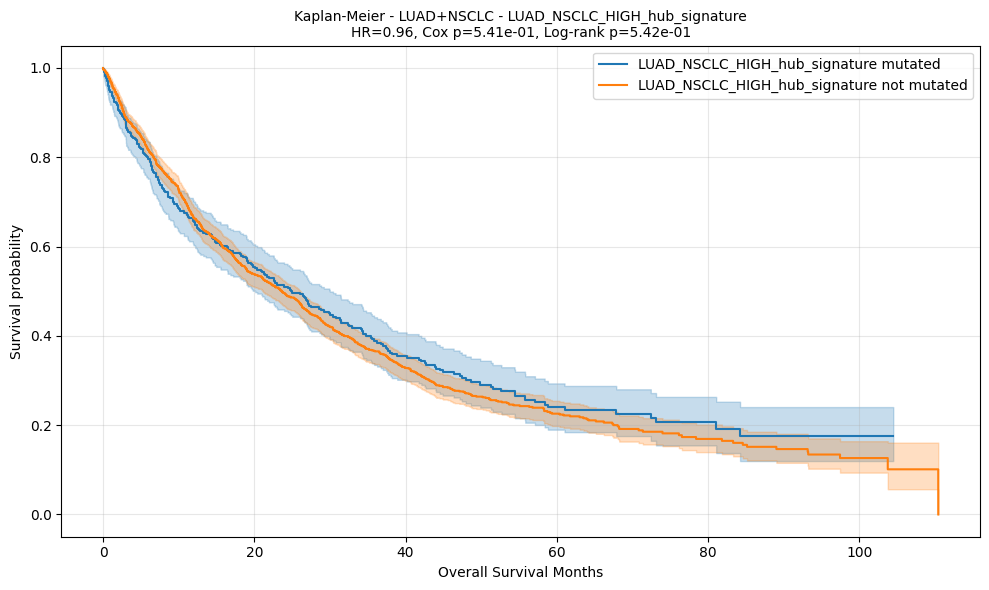

KM plot salvato in: data_lung\clinical_to_network_by_oncotree_groups\km_hub_signatures_by_oncotree_group\KM_LUAD_NSCLC_LUAD_NSCLC_HIGH_hub_signature.png

ONCOTREE GROUP: LUAD_NSCLC (LUAD+NSCLC)
Signature: LUAD_NSCLC_LOW_hub_signature
Genes: BRIP1, CD274, DIS3, GNAS, PDCD1LG2, RAD52, RASA1, RIT1, RPS6KB2, WT1
Patients with signature mutation: 261
Patients without signature mutation: 1436
Events with signature mutation: 193
Events without signature mutation: 946


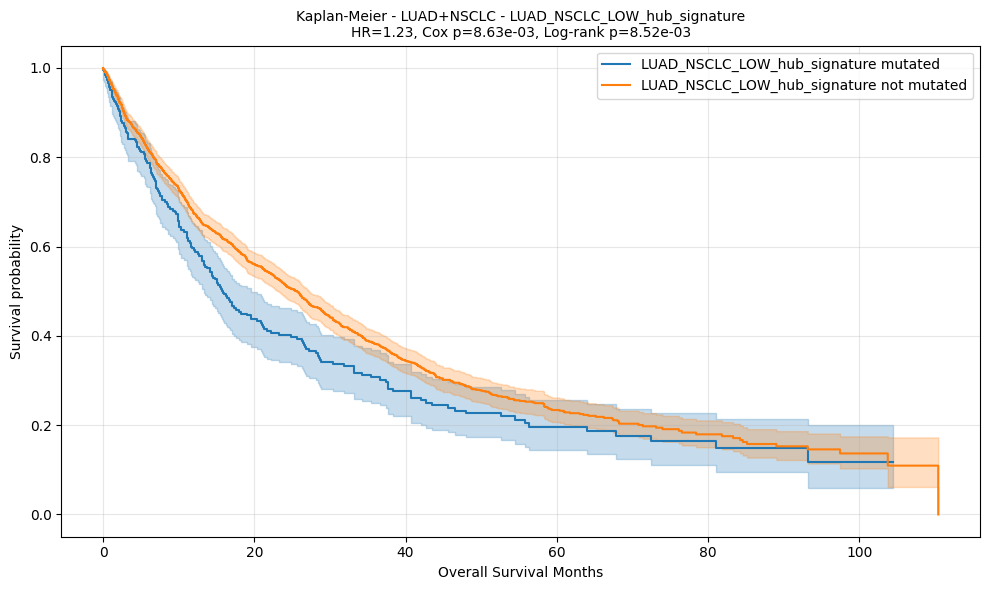

KM plot salvato in: data_lung\clinical_to_network_by_oncotree_groups\km_hub_signatures_by_oncotree_group\KM_LUAD_NSCLC_LUAD_NSCLC_LOW_hub_signature.png

ONCOTREE GROUP: LUSC_NSCLC (LUSC+NSCLC)
Signature: LUSC_NSCLC_HIGH_hub_signature
Genes: BCL6, CDKN2A, DCUN1D1, EIF4A2, MAP3K13, PIK3CA, PRKCI, SOX2, TP53, TP63
Patients with signature mutation: 251
Patients without signature mutation: 50
Events with signature mutation: 187
Events without signature mutation: 41


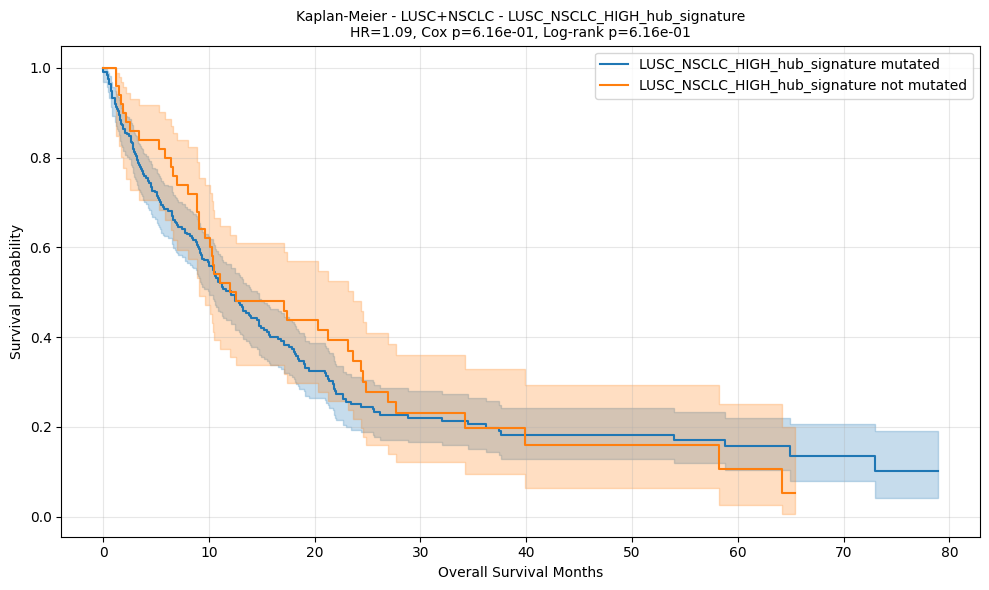

KM plot salvato in: data_lung\clinical_to_network_by_oncotree_groups\km_hub_signatures_by_oncotree_group\KM_LUSC_NSCLC_LUSC_NSCLC_HIGH_hub_signature.png

ONCOTREE GROUP: LUSC_NSCLC (LUSC+NSCLC)
Signature: LUSC_NSCLC_LOW_hub_signature
Genes: GLI1, KDR, KIT, KRAS, PDGFRA, PREX2, SMARCA4, STK11, TBX3, TET1
Patients with signature mutation: 134
Patients without signature mutation: 167
Events with signature mutation: 102
Events without signature mutation: 126


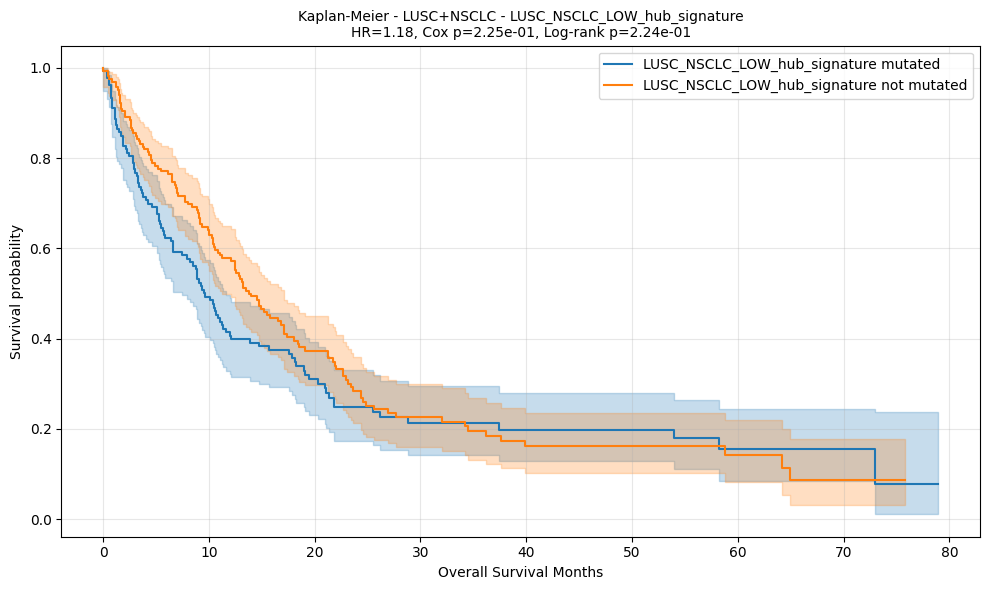

KM plot salvato in: data_lung\clinical_to_network_by_oncotree_groups\km_hub_signatures_by_oncotree_group\KM_LUSC_NSCLC_LUSC_NSCLC_LOW_hub_signature.png

KM results - clinical to network signatures by Oncotree Group:


,Oncotree_Group,Included_Oncotree_Codes,Signature,Num_genes,Genes,Patients_with_signature,Events_with_signature,Patients_without_signature,Events_without_signature,Logrank_p_value,Hazard_Ratio,Cox_p_value
0,LUAD_NSCLC,LUAD+NSCLC,LUAD_NSCLC_LOW_hub_signature,10,"BRIP1, CD274, DIS3, GNAS, PDCD1LG2, RAD52, RASA1, RIT1, RPS6KB2, WT1",261,193,1436,946,0.008523,1.230672,0.008628
1,LUAD_NSCLC,LUAD+NSCLC,LUAD_NSCLC_HIGH_hub_signature,10,"ABL1, ASXL1, ATRX, DNMT3A, ERCC5, MED12, PIK3CA, POLE, SLX4, SPEN",374,248,1323,891,0.541718,0.957050,0.541344
2,LUSC_NSCLC,LUSC+NSCLC,LUSC_NSCLC_LOW_hub_signature,10,"GLI1, KDR, KIT, KRAS, PDGFRA, PREX2, SMARCA4, STK11, TBX3, TET1",134,102,167,126,0.224102,1.175487,0.225378
3,LUSC_NSCLC,LUSC+NSCLC,LUSC_NSCLC_HIGH_hub_signature,10,"BCL6, CDKN2A, DCUN1D1, EIF4A2, MAP3K13, PIK3CA, PRKCI, SOX2, TP53, TP63",251,187,50,41,0.615555,1.090664,0.615703



KM results salvati in:
data_lung\clinical_to_network_by_oncotree_groups\km_hub_signatures_by_oncotree_group\km_results_clinical_to_network_hub_signatures_by_oncotree_groups.csv


In [58]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

from lifelines import KaplanMeierFitter, CoxPHFitter
from lifelines.statistics import logrank_test


# ============================================================
# KM ANALYSIS - CLINICAL TO NETWORK
# Oncotree Groups-oriented
# Hub gene signatures: HIGH-hub vs LOW-hub
#
# LUAD_NSCLC = LUAD + NSCLC
# LUSC_NSCLC = LUSC + NSCLC
# ============================================================

data_dir = Path("data_lung")

merged_path = (
        data_dir
        / "CLINICAL_merged_mutations_cna_sv_with_survival_groups_BY_ONCOTREE_GROUPS.csv"
)

km_output_dir = (
        data_dir
        / "clinical_to_network_by_oncotree_groups"
        / "km_hub_signatures_by_oncotree_group"
)

km_output_dir.mkdir(parents=True, exist_ok=True)

target_groups = ["LUAD_NSCLC", "LUSC_NSCLC"]

group_labels = {
    "LUAD_NSCLC": "LUAD+NSCLC",
    "LUSC_NSCLC": "LUSC+NSCLC",
}


# ============================================================
# Helpers against duplicate columns
# ============================================================

def collapse_duplicate_columns(df):
    """
    Se ci sono colonne duplicate, le collassa prendendo il primo valore non nullo.
    """
    df = df.copy()

    if not df.columns.duplicated().any():
        return df

    collapsed = pd.DataFrame(index=df.index)

    for col in pd.unique(df.columns):
        same_cols = df.loc[:, df.columns == col]

        if same_cols.shape[1] == 1:
            collapsed[col] = same_cols.iloc[:, 0]
        else:
            collapsed[col] = same_cols.bfill(axis=1).iloc[:, 0]

    return collapsed.copy()


def get_single_column(df, col):
    """
    Restituisce sempre una Series, anche se per errore ci sono colonne duplicate.
    """
    obj = df[col]

    if isinstance(obj, pd.DataFrame):
        return obj.iloc[:, 0]

    return obj


def safe_filename(text):
    text = str(text)
    text = text.replace("+", "_")
    text = text.replace("/", "_")
    text = text.replace(" ", "_")
    return text


# ============================================================
# Load merged dataset
# ============================================================

df_merge = pd.read_csv(merged_path, low_memory=False)
df_merge = collapse_duplicate_columns(df_merge)

# ------------------------------------------------------------
# Uniform column names safely
# ------------------------------------------------------------

if "PATIENT_ID" in df_merge.columns and "Patient_ID" not in df_merge.columns:
    df_merge = df_merge.rename(columns={"PATIENT_ID": "Patient_ID"})

if "Oncotree Code" in df_merge.columns and "ONCOTREE_CODE" not in df_merge.columns:
    df_merge = df_merge.rename(columns={"Oncotree Code": "ONCOTREE_CODE"})

if "ONCOTREE_GROUP" in df_merge.columns and "Oncotree_Group" not in df_merge.columns:
    df_merge = df_merge.rename(columns={"ONCOTREE_GROUP": "Oncotree_Group"})

if "Oncotree Group" in df_merge.columns and "Oncotree_Group" not in df_merge.columns:
    df_merge = df_merge.rename(columns={"Oncotree Group": "Oncotree_Group"})

# Gestione gene column:
# se esiste già Hugo_Symbol, uso quella;
# se non esiste ma esiste Gene, rinomino Gene.
if "Hugo_Symbol" not in df_merge.columns and "Gene" in df_merge.columns:
    df_merge = df_merge.rename(columns={"Gene": "Hugo_Symbol"})
elif "Hugo_Symbol" in df_merge.columns and "Gene" in df_merge.columns:
    df_merge = df_merge.drop(columns=["Gene"])

df_merge = collapse_duplicate_columns(df_merge)

required_cols = {
    "Patient_ID",
    "Hugo_Symbol",
    "Oncotree_Group",
    "OS_MONTHS",
    "event"
}

missing_cols = required_cols - set(df_merge.columns)

if missing_cols:
    raise ValueError(
        f"Colonne mancanti nel merged file per gruppi Oncotree: {missing_cols}. "
        "Controlla che OS_MONTHS, event e Oncotree_Group siano stati aggiunti al file merged."
    )

if "hub_comparison_all_oncotree" not in globals():
    raise ValueError(
        "hub_comparison_all_oncotree non disponibile. "
        "Esegui prima la cella hub high vs low per Oncotree Group."
    )

df_merge["Patient_ID"] = get_single_column(df_merge, "Patient_ID").astype(str)
df_merge["Hugo_Symbol"] = get_single_column(df_merge, "Hugo_Symbol").astype(str)
df_merge["Oncotree_Group"] = get_single_column(df_merge, "Oncotree_Group").astype(str)

df_merge["OS_MONTHS"] = pd.to_numeric(
    get_single_column(df_merge, "OS_MONTHS"),
    errors="coerce"
)

df_merge["event"] = pd.to_numeric(
    get_single_column(df_merge, "event"),
    errors="coerce"
)

df_merge = df_merge.dropna(
    subset=[
        "Patient_ID",
        "Hugo_Symbol",
        "Oncotree_Group",
        "OS_MONTHS",
        "event"
    ]
).copy()

df_merge["event"] = df_merge["event"].astype(int)

# Tengo solo i due gruppi richiesti
df_merge = df_merge[
    df_merge["Oncotree_Group"].isin(target_groups)
].copy()

if "Included_Oncotree_Codes" not in df_merge.columns:
    df_merge["Included_Oncotree_Codes"] = df_merge["Oncotree_Group"].map(group_labels)

print("Loaded:")
print(merged_path)

print("\nDuplicate columns after cleaning:")
print(df_merge.columns[df_merge.columns.duplicated()].tolist())

print("\nRows:", df_merge.shape[0])
print("Patients:", df_merge["Patient_ID"].nunique())
print("Oncotree Groups:", sorted(df_merge["Oncotree_Group"].unique()))

print("\nPatients by Oncotree Group:")

display(
    df_merge
    .drop_duplicates(["Patient_ID", "Oncotree_Group"])
    .groupby(["Oncotree_Group", "Included_Oncotree_Codes"])
    .agg(
        n_patients=("Patient_ID", "nunique"),
        n_events=("event", "sum")
    )
    .reset_index()
    .sort_values("n_patients", ascending=False)
)


# ============================================================
# PARAMETERS
# ============================================================

top_n_genes = 10
min_patients_per_group = 10
min_events_per_group = 5

km_results = []


# ============================================================
# KM helper
# ============================================================

def run_km_for_gene_signature(
        df_group,
        oncotree_group,
        gene_signature,
        signature_name
):
    """
    Confronta:
    - pazienti con almeno una mutazione nei geni della signature
    - pazienti senza mutazioni nei geni della signature
    """

    df_group = collapse_duplicate_columns(df_group)

    readable_group = group_labels.get(oncotree_group, oncotree_group)

    gene_signature = set([
        str(g)
        for g in gene_signature
        if pd.notna(g)
    ])

    if len(gene_signature) == 0:
        print(f"[{oncotree_group} - {signature_name}] No genes in signature.")
        return None

    clinical = (
        df_group[
            [
                "Patient_ID",
                "OS_MONTHS",
                "event"
            ]
        ]
        .drop_duplicates("Patient_ID")
        .copy()
    )

    gene_series = get_single_column(df_group, "Hugo_Symbol").astype(str)

    mask_signature = gene_series.isin(gene_signature)

    patients_with_signature = (
        df_group.loc[mask_signature, "Patient_ID"]
        .dropna()
        .astype(str)
        .unique()
    )

    clinical["has_signature"] = (
        clinical["Patient_ID"]
        .astype(str)
        .isin(patients_with_signature)
        .astype(int)
    )

    n_mut = int(clinical["has_signature"].sum())
    n_wt = int((clinical["has_signature"] == 0).sum())

    events_mut = int(
        clinical.loc[
            clinical["has_signature"] == 1,
            "event"
        ].sum()
    )

    events_wt = int(
        clinical.loc[
            clinical["has_signature"] == 0,
            "event"
        ].sum()
    )

    print("\n" + "=" * 90)
    print(f"ONCOTREE GROUP: {oncotree_group} ({readable_group})")
    print(f"Signature: {signature_name}")
    print(f"Genes: {', '.join(sorted(gene_signature))}")
    print(f"Patients with signature mutation: {n_mut}")
    print(f"Patients without signature mutation: {n_wt}")
    print(f"Events with signature mutation: {events_mut}")
    print(f"Events without signature mutation: {events_wt}")

    if (
            n_mut < min_patients_per_group
            or n_wt < min_patients_per_group
            or events_mut < min_events_per_group
            or events_wt < min_events_per_group
    ):
        print("Skipped: too few patients or events.")
        return None

    group_mut = clinical[clinical["has_signature"] == 1]
    group_wt = clinical[clinical["has_signature"] == 0]

    lr = logrank_test(
        group_mut["OS_MONTHS"],
        group_wt["OS_MONTHS"],
        event_observed_A=group_mut["event"],
        event_observed_B=group_wt["event"]
    )

    cox_df = clinical[
        [
            "OS_MONTHS",
            "event",
            "has_signature"
        ]
    ].copy()

    cph = CoxPHFitter()
    cph.fit(
        cox_df,
        duration_col="OS_MONTHS",
        event_col="event"
    )

    hr = np.exp(cph.params_["has_signature"])
    p_cox = cph.summary.loc["has_signature", "p"]

    kmf = KaplanMeierFitter()

    plt.figure(figsize=(10, 6))

    kmf.fit(
        group_mut["OS_MONTHS"],
        event_observed=group_mut["event"],
        label=f"{signature_name} mutated"
    )
    kmf.plot_survival_function()

    kmf.fit(
        group_wt["OS_MONTHS"],
        event_observed=group_wt["event"],
        label=f"{signature_name} not mutated"
    )
    kmf.plot_survival_function()

    plt.title(
        f"Kaplan-Meier - {readable_group} - {signature_name}\n"
        f"HR={hr:.2f}, Cox p={p_cox:.2e}, Log-rank p={lr.p_value:.2e}",
        fontsize=10
    )

    plt.xlabel("Overall Survival Months")
    plt.ylabel("Survival probability")
    plt.grid(alpha=0.3)
    plt.tight_layout()

    fig_path = (
            km_output_dir
            / f"KM_{safe_filename(oncotree_group)}_{safe_filename(signature_name)}.png"
    )

    plt.savefig(fig_path, dpi=300, bbox_inches="tight")
    plt.show()

    print(f"KM plot salvato in: {fig_path}")

    return {
        "Oncotree_Group": oncotree_group,
        "Included_Oncotree_Codes": readable_group,
        "Signature": signature_name,
        "Num_genes": len(gene_signature),
        "Genes": ", ".join(sorted(gene_signature)),
        "Patients_with_signature": n_mut,
        "Events_with_signature": events_mut,
        "Patients_without_signature": n_wt,
        "Events_without_signature": events_wt,
        "Logrank_p_value": lr.p_value,
        "Hazard_Ratio": hr,
        "Cox_p_value": p_cox
    }


# ============================================================
# RUN KM PER ONCOTREE GROUP
# ============================================================

hub_comparison_all_oncotree = collapse_duplicate_columns(hub_comparison_all_oncotree)

# Compatibilità:
# se per caso la tabella ha ancora ONCOTREE_CODE ma contiene LUAD_NSCLC/LUSC_NSCLC,
# la rinomino in Oncotree_Group.
if "Oncotree_Group" not in hub_comparison_all_oncotree.columns:
    if "ONCOTREE_CODE" in hub_comparison_all_oncotree.columns:
        hub_comparison_all_oncotree = hub_comparison_all_oncotree.rename(
            columns={"ONCOTREE_CODE": "Oncotree_Group"}
        )
    else:
        raise ValueError(
            "hub_comparison_all_oncotree deve contenere Oncotree_Group "
            "oppure ONCOTREE_CODE."
        )

required_hub_cols = {
    "Oncotree_Group",
    "Gene",
    "Delta_HubScore_high_minus_low"
}

missing_hub_cols = required_hub_cols - set(hub_comparison_all_oncotree.columns)

if missing_hub_cols:
    raise ValueError(
        f"Colonne mancanti in hub_comparison_all_oncotree: {missing_hub_cols}"
    )

hub_comparison_all_oncotree["Oncotree_Group"] = (
    hub_comparison_all_oncotree["Oncotree_Group"]
    .astype(str)
)

hub_comparison_all_oncotree = hub_comparison_all_oncotree[
    hub_comparison_all_oncotree["Oncotree_Group"].isin(target_groups)
].copy()


for oncotree_group in sorted(
        hub_comparison_all_oncotree["Oncotree_Group"]
                .dropna()
                .astype(str)
                .unique()
):

    readable_group = group_labels.get(oncotree_group, oncotree_group)

    df_group = df_merge[
        df_merge["Oncotree_Group"] == oncotree_group
        ].copy()

    comp = hub_comparison_all_oncotree[
        hub_comparison_all_oncotree["Oncotree_Group"].astype(str) == oncotree_group
        ].copy()

    if comp.empty:
        continue

    high_signature_genes = (
        comp
        .sort_values("Delta_HubScore_high_minus_low", ascending=False)
        .head(top_n_genes)["Gene"]
        .dropna()
        .astype(str)
        .tolist()
    )

    low_signature_genes = (
        comp
        .sort_values("Delta_HubScore_high_minus_low", ascending=True)
        .head(top_n_genes)["Gene"]
        .dropna()
        .astype(str)
        .tolist()
    )

    res_high = run_km_for_gene_signature(
        df_group=df_group,
        oncotree_group=oncotree_group,
        gene_signature=high_signature_genes,
        signature_name=f"{oncotree_group}_HIGH_hub_signature"
    )

    if res_high is not None:
        km_results.append(res_high)

    res_low = run_km_for_gene_signature(
        df_group=df_group,
        oncotree_group=oncotree_group,
        gene_signature=low_signature_genes,
        signature_name=f"{oncotree_group}_LOW_hub_signature"
    )

    if res_low is not None:
        km_results.append(res_low)


# ============================================================
# FINAL TABLE
# ============================================================

km_results_clinical_to_network = pd.DataFrame(km_results)

if not km_results_clinical_to_network.empty:
    km_results_clinical_to_network = (
        km_results_clinical_to_network
        .sort_values(["Oncotree_Group", "Logrank_p_value"])
        .reset_index(drop=True)
    )

    output_file = (
            km_output_dir
            / "km_results_clinical_to_network_hub_signatures_by_oncotree_groups.csv"
    )

    km_results_clinical_to_network.to_csv(
        output_file,
        index=False
    )

    print("\nKM results - clinical to network signatures by Oncotree Group:")

    display(km_results_clinical_to_network)

    print("\nKM results salvati in:")
    print(output_file)

else:
    print("\nNo KM result passed the minimum patient/event thresholds.")


# ============================================================
# OPTIONAL COMPATIBILITY ALIAS
# ============================================================

km_results_clinical_to_network_oncotree_groups = km_results_clinical_to_network